# **Project Based Internship Home Credit**

## Ringkasan Proyek
Home Credit bertujuan untuk meningkatkan prediksi risiko kredit guna memastikan bahwa pemohon yang mampu tidak ditolak, sekaligus meminimalkan risiko gagal bayar (default).

Proyek ini berfokus pada:



*   Memprediksi probabilitas gagal bayar nasabah.
*   Memanfaatkan berbagai kumpulan data relasional.
*   Membangun model pembelajaran mesin (machine learning) (XGBoost + Regresi Logistik).
*   Memberikan wawasan dan rekomendasi yang berorientasi pada bisnis.

---


## Setup Environment

In [ ]:
# Basic
import pandas as pd
import numpy as np
import os

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_curve
import matplotlib.pyplot as plt
# --------------------------------
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from xgboost import XGBClassifier

from xgboost.callback import EarlyStopping
from sklearn.metrics import roc_auc_score
import joblib
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report

from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve, auc,
    precision_recall_curve, average_precision_score
)
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np
import seaborn as sns

from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import StratifiedKFold
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
import numpy as np
import matplotlib.pyplot as plt


# Display
pd.set_option('display.max_columns', 100)
pd.set_option('display.max_rows', 100)

### Reduce Memory Usage

In [ ]:

def reduce_mem_usage(df):
    for col in df.columns:
        col_type = df[col].dtype

        if col_type != object:
            c_min = df[col].min()
            c_max = df[col].max()

            if str(col_type)[:3] == 'int':
                df[col] = pd.to_numeric(df[col], downcast='integer')
            else:
                df[col] = pd.to_numeric(df[col], downcast='float')
    return df

# usage
# app_train = reduce_mem_usage(app_train)

## Load Data

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
base_path = '/content/drive/MyDrive/dataset PBI home credit/'

In [ ]:
# Main dataset
app_train = pd.read_csv(base_path + 'application_train.csv')
app_test = pd.read_csv(base_path + 'application_test.csv')

# External data
bureau = pd.read_csv(base_path + 'bureau.csv')
bureau_balance = pd.read_csv(base_path + 'bureau_balance.csv')

previous_app = pd.read_csv(base_path + 'previous_application.csv')

pos_cash = pd.read_csv(base_path + 'POS_CASH_balance.csv')
installments = pd.read_csv(base_path + 'installments_payments.csv')
credit_card = pd.read_csv(base_path + 'credit_card_balance.csv')

In [ ]:
files = os.listdir(base_path)
print(files)

datasets = {
    'app_train': app_train,
    'app_test': app_test,
    'bureau': bureau,
    'bureau_balance': bureau_balance,
    'previous_app': previous_app,
    'pos_cash': pos_cash,
    'installments': installments,
    'credit_card': credit_card
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

['HomeCredit_columns_description.csv', 'POS_CASH_balance.csv', 'application_test.csv', 'application_train.csv', 'bureau.csv', 'bureau_balance.csv', 'credit_card_balance.csv', 'installments_payments.csv', 'previous_application.csv', 'sample_submission.csv', 'final_train_preprocessed.csv', 'final_test_preprocessed.csv', 'final_train.csv', 'final_test.csv']
app_train: (307511, 122)
app_test: (48744, 121)
bureau: (1716428, 17)
bureau_balance: (27299925, 3)
previous_app: (1670214, 37)
pos_cash: (10001358, 8)
installments: (13605401, 8)
credit_card: (3840312, 23)


In [ ]:
app_train = reduce_mem_usage(app_train)

## Data Understanding & EDA

In [ ]:
print(app_train.shape)
app_train.head()

(307511, 122)


,SK_ID_CURR,TARGET,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,...,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100002,1,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637,-3648.0,-2120,NaN,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.083037,0.262949,0.139376,0.0247,0.0369,0.9722,0.6192,0.0143,0.00,...,0.0250,0.0369,0.9722,0.6243,0.0144,0.00,0.0690,0.0833,0.1250,0.0375,0.0205,0.0193,0.0000,0.00,reg oper account,block of flats,0.0149,"Stone, brick",No,2.0,2.0,2.0,2.0,-1134.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,1.0
1,100003,0,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188,-1186.0,-291,NaN,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,NaN,0.0959,0.0529,0.9851,0.7960,0.0605,0.08,...,0.0968,0.0529,0.9851,0.7987,0.0608,0.08,0.0345,0.2917,0.3333,0.0132,0.0787,0.0558,0.0039,0.01,reg oper account,block of flats,0.0714,Block,No,1.0,0.0,1.0,0.0,-828.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
2,100004,0,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225,-4260.0,-2531,26.0,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,Government,NaN,0.555912,0.729567,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,-815.0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
3,100006,0,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,297000.0,Unaccompanied,Working,Secondary / secondary special,Civil marriage,House / apartment,0.008019,-19005,-3039,-9833.0,-2437,NaN,1,1,0,1,0,0,Laborers,2.0,2,2,WEDNESDAY,17,0,0,0,0,0,0,Business Entity Type 3,NaN,0.650442,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2.0,0.0,2.0,0.0,-617.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,NaN,NaN,NaN,NaN,NaN,NaN
4,100007,0,Cash loans,M,N,Y,0,121500.0,513000.0,21865.5,513000.0,Unaccompanied,Working,Secondary / secondary special,Single /

In [ ]:
app_train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 307511 entries, 0 to 307510
Columns: 122 entries, SK_ID_CURR to AMT_REQ_CREDIT_BUREAU_YEAR
dtypes: float32(64), float64(1), int16(2), int32(2), int8(37), object(16)
memory usage: 129.3+ MB


In [ ]:
num_cols = app_train.select_dtypes(include=['number']).columns
cat_cols = app_train.select_dtypes(include=['object']).columns

print(f"Numerical features: {len(num_cols)}")
print(f"Categorical features: {len(cat_cols)}")

Numerical features: 106
Categorical features: 16


In [ ]:
app_train['TARGET'].value_counts()
app_train['TARGET'].value_counts(normalize=True)

,proportion
TARGET,
0,0.919271
1,0.080729


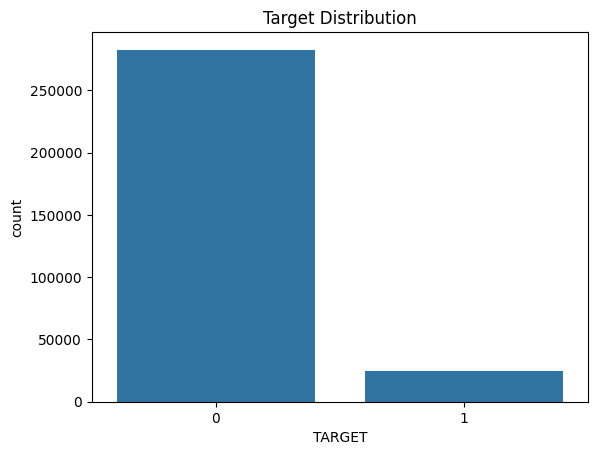

In [ ]:


sns.countplot(x='TARGET', data=app_train)
plt.title('Target Distribution')
plt.show()

### App_test, bureau, bureau_balance, previous_application, installments_payments, POS_CASH_balance, credit_card_balance

In [ ]:
print(app_test.shape)
app_test.head()

(48744, 121)


,SK_ID_CURR,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,OWN_CAR_AGE,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,YEARS_BUILD_AVG,COMMONAREA_AVG,ELEVATORS_AVG,ENTRANCES_AVG,...,APARTMENTS_MEDI,BASEMENTAREA_MEDI,YEARS_BEGINEXPLUATATION_MEDI,YEARS_BUILD_MEDI,COMMONAREA_MEDI,ELEVATORS_MEDI,ENTRANCES_MEDI,FLOORSMAX_MEDI,FLOORSMIN_MEDI,LANDAREA_MEDI,LIVINGAPARTMENTS_MEDI,LIVINGAREA_MEDI,NONLIVINGAPARTMENTS_MEDI,NONLIVINGAREA_MEDI,FONDKAPREMONT_MODE,HOUSETYPE_MODE,TOTALAREA_MODE,WALLSMATERIAL_MODE,EMERGENCYSTATE_MODE,OBS_30_CNT_SOCIAL_CIRCLE,DEF_30_CNT_SOCIAL_CIRCLE,OBS_60_CNT_SOCIAL_CIRCLE,DEF_60_CNT_SOCIAL_CIRCLE,DAYS_LAST_PHONE_CHANGE,FLAG_DOCUMENT_2,FLAG_DOCUMENT_3,FLAG_DOCUMENT_4,FLAG_DOCUMENT_5,FLAG_DOCUMENT_6,FLAG_DOCUMENT_7,FLAG_DOCUMENT_8,FLAG_DOCUMENT_9,FLAG_DOCUMENT_10,FLAG_DOCUMENT_11,FLAG_DOCUMENT_12,FLAG_DOCUMENT_13,FLAG_DOCUMENT_14,FLAG_DOCUMENT_15,FLAG_DOCUMENT_16,FLAG_DOCUMENT_17,FLAG_DOCUMENT_18,FLAG_DOCUMENT_19,FLAG_DOCUMENT_20,FLAG_DOCUMENT_21,AMT_REQ_CREDIT_BUREAU_HOUR,AMT_REQ_CREDIT_BUREAU_DAY,AMT_REQ_CREDIT_BUREAU_WEEK,AMT_REQ_CREDIT_BUREAU_MON,AMT_REQ_CREDIT_BUREAU_QRT,AMT_REQ_CREDIT_BUREAU_YEAR
0,100001,Cash loans,F,N,Y,0,135000.0,568800.0,20560.5,450000.0,Unaccompanied,Working,Higher education,Married,House / apartment,0.018850,-19241,-2329,-5170.0,-812,NaN,1,1,0,1,0,1,NaN,2.0,2,2,TUESDAY,18,0,0,0,0,0,0,Kindergarten,0.752614,0.789654,0.159520,0.0660,0.0590,0.9732,NaN,NaN,NaN,0.1379,...,0.0666,0.0590,0.9732,NaN,NaN,NaN,0.1379,0.125,NaN,NaN,NaN,0.0514,NaN,NaN,NaN,block of flats,0.0392,"Stone, brick",No,0.0,0.0,0.0,0.0,-1740.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,0.0
1,100005,Cash loans,M,N,Y,0,99000.0,222768.0,17370.0,180000.0,Unaccompanied,Working,Secondary / secondary special,Married,House / apartment,0.035792,-18064,-4469,-9118.0,-1623,NaN,1,1,0,1,0,0,Low-skill Laborers,2.0,2,2,FRIDAY,9,0,0,0,0,0,0,Self-employed,0.564990,0.291656,0.432962,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,0.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,3.0
2,100013,Cash loans,M,Y,Y,0,202500.0,663264.0,69777.0,630000.0,NaN,Working,Higher education,Married,House / apartment,0.019101,-20038,-4458,-2175.0,-3503,5.0,1,1,0,1,0,0,Drivers,2.0,2,2,MONDAY,14,0,0,0,0,0,0,Transport: type 3,NaN,0.699787,0.610991,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0.0,0.0,0.0,-856.0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,1.0,4.0
3,100028,Cash loans,F,N,Y,2,315000.0,1575000.0,49018.5,1575000.0,Unaccompanied,Working,Secondary / secondary special,Married,House / apartment,0.026392,-13976,-1866,-2000.0,-4208,NaN,1,1,0,1,1,0,Sales staff,4.0,2,2,WEDNESDAY,11,0,0,0,0,0,0,Business Entity Type 3,0.525734,0.509677,0.612704,0.3052,0.1974,0.9970,0.9592,0.1165,0.32,0.2759,...,0.3081,0.1974,0.9970,0.9597,0.1173,0.32,0.2759,0.375,0.0417,0.2078,0.2446,0.3739,0.0388,0.0817,reg oper account,block of flats,0.3700,Panel,No,0.0,0.0,0.0,0.0,-1805.0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.0,0.0,0.0,0.0,0.0,3.0
4,100038,Cash loans,M,Y,N,1,180000.0,625500.0,32067.0,625500.0,Unaccompanied,Working,Secondary / secondary special,Married,House / apartment,0.010032,-13040,-2191,-4000.0,-4262,16.0

In [ ]:
print(bureau.shape)
bureau.head()

(1716428, 17)


,SK_ID_CURR,SK_ID_BUREAU,CREDIT_ACTIVE,CREDIT_CURRENCY,DAYS_CREDIT,CREDIT_DAY_OVERDUE,DAYS_CREDIT_ENDDATE,DAYS_ENDDATE_FACT,AMT_CREDIT_MAX_OVERDUE,CNT_CREDIT_PROLONG,AMT_CREDIT_SUM,AMT_CREDIT_SUM_DEBT,AMT_CREDIT_SUM_LIMIT,AMT_CREDIT_SUM_OVERDUE,CREDIT_TYPE,DAYS_CREDIT_UPDATE,AMT_ANNUITY
0,215354,5714462,Closed,currency 1,-497,0,-153.0,-153.0,NaN,0,91323.0,0.0,NaN,0.0,Consumer credit,-131,NaN
1,215354,5714463,Active,currency 1,-208,0,1075.0,NaN,NaN,0,225000.0,171342.0,NaN,0.0,Credit card,-20,NaN
2,215354,5714464,Active,currency 1,-203,0,528.0,NaN,NaN,0,464323.5,NaN,NaN,0.0,Consumer credit,-16,NaN
3,215354,5714465,Active,currency 1,-203,0,NaN,NaN,NaN,0,90000.0,NaN,NaN,0.0,Credit card,-16,NaN
4,215354,5714466,Active,currency 1,-629,0,1197.0,NaN,77674.5,0,2700000.0,NaN,NaN,0.0,Consumer credit,-21,NaN


In [ ]:
print(bureau_balance.shape)
bureau_balance.head()

(27299925, 3)


,SK_ID_BUREAU,MONTHS_BALANCE,STATUS
0,5715448,0,C
1,5715448,-1,C
2,5715448,-2,C
3,5715448,-3,C
4,5715448,-4,C


In [ ]:
print(previous_app.shape)
previous_app.head()

(1670214, 37)


,SK_ID_PREV,SK_ID_CURR,NAME_CONTRACT_TYPE,AMT_ANNUITY,AMT_APPLICATION,AMT_CREDIT,AMT_DOWN_PAYMENT,AMT_GOODS_PRICE,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,FLAG_LAST_APPL_PER_CONTRACT,NFLAG_LAST_APPL_IN_DAY,RATE_DOWN_PAYMENT,RATE_INTEREST_PRIMARY,RATE_INTEREST_PRIVILEGED,NAME_CASH_LOAN_PURPOSE,NAME_CONTRACT_STATUS,DAYS_DECISION,NAME_PAYMENT_TYPE,CODE_REJECT_REASON,NAME_TYPE_SUITE,NAME_CLIENT_TYPE,NAME_GOODS_CATEGORY,NAME_PORTFOLIO,NAME_PRODUCT_TYPE,CHANNEL_TYPE,SELLERPLACE_AREA,NAME_SELLER_INDUSTRY,CNT_PAYMENT,NAME_YIELD_GROUP,PRODUCT_COMBINATION,DAYS_FIRST_DRAWING,DAYS_FIRST_DUE,DAYS_LAST_DUE_1ST_VERSION,DAYS_LAST_DUE,DAYS_TERMINATION,NFLAG_INSURED_ON_APPROVAL
0,2030495,271877,Consumer loans,1730.430,17145.0,17145.0,0.0,17145.0,SATURDAY,15,Y,1,0.0,0.182832,0.867336,XAP,Approved,-73,Cash through the bank,XAP,NaN,Repeater,Mobile,POS,XNA,Country-wide,35,Connectivity,12.0,middle,POS mobile with interest,365243.0,-42.0,300.0,-42.0,-37.0,0.0
1,2802425,108129,Cash loans,25188.615,607500.0,679671.0,NaN,607500.0,THURSDAY,11,Y,1,NaN,NaN,NaN,XNA,Approved,-164,XNA,XAP,Unaccompanied,Repeater,XNA,Cash,x-sell,Contact center,-1,XNA,36.0,low_action,Cash X-Sell: low,365243.0,-134.0,916.0,365243.0,365243.0,1.0
2,2523466,122040,Cash loans,15060.735,112500.0,136444.5,NaN,112500.0,TUESDAY,11,Y,1,NaN,NaN,NaN,XNA,Approved,-301,Cash through the bank,XAP,"Spouse, partner",Repeater,XNA,Cash,x-sell,Credit and cash offices,-1,XNA,12.0,high,Cash X-Sell: high,365243.0,-271.0,59.0,365243.0,365243.0,1.0
3,2819243,176158,Cash loans,47041.335,450000.0,470790.0,NaN,450000.0,MONDAY,7,Y,1,NaN,NaN,NaN,XNA,Approved,-512,Cash through the bank,XAP,NaN,Repeater,XNA,Cash,x-sell,Credit and cash offices,-1,XNA,12.0,middle,Cash X-Sell: middle,365243.0,-482.0,-152.0,-182.0,-177.0,1.0
4,1784265,202054,Cash loans,31924.395,337500.0,404055.0,NaN,337500.0,THURSDAY,9,Y,1,NaN,NaN,NaN,Repairs,Refused,-781,Cash through the bank,HC,NaN,Repeater,XNA,Cash,walk-in,Credit and cash offices,-1,XNA,24.0,high,Cash Street: high,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
print(pos_cash.shape)
pos_cash.head()

(10001358, 8)


,SK_ID_PREV,SK_ID_CURR,MONTHS_BALANCE,CNT_INSTALMENT,CNT_INSTALMENT_FUTURE,NAME_CONTRACT_STATUS,SK_DPD,SK_DPD_DEF
0,1803195,182943,-31,48.0,45.0,Active,0,0
1,1715348,367990,-33,36.0,35.0,Active,0,0
2,1784872,397406,-32,12.0,9.0,Active,0,0
3,1903291,269225,-35,48.0,42.0,Active,0,0
4,2341044,334279,-35,36.0,35.0,Active,0,0


In [ ]:
print(installments.shape)
installments.head()

(13605401, 8)


,SK_ID_PREV,SK_ID_CURR,NUM_INSTALMENT_VERSION,NUM_INSTALMENT_NUMBER,DAYS_INSTALMENT,DAYS_ENTRY_PAYMENT,AMT_INSTALMENT,AMT_PAYMENT
0,1054186,161674,1.0,6,-1180.0,-1187.0,6948.360,6948.360
1,1330831,151639,0.0,34,-2156.0,-2156.0,1716.525,1716.525
2,2085231,193053,2.0,1,-63.0,-63.0,25425.000,25425.000
3,2452527,199697,1.0,3,-2418.0,-2426.0,24350.130,24350.130
4,2714724,167756,1.0,2,-1383.0,-1366.0,2165.040,2160.585


In [ ]:
print(credit_card.shape)
credit_card.head()

(3840312, 23)


,SK_ID_PREV,SK_ID_CURR,MONTHS_BALANCE,AMT_BALANCE,AMT_CREDIT_LIMIT_ACTUAL,AMT_DRAWINGS_ATM_CURRENT,AMT_DRAWINGS_CURRENT,AMT_DRAWINGS_OTHER_CURRENT,AMT_DRAWINGS_POS_CURRENT,AMT_INST_MIN_REGULARITY,AMT_PAYMENT_CURRENT,AMT_PAYMENT_TOTAL_CURRENT,AMT_RECEIVABLE_PRINCIPAL,AMT_RECIVABLE,AMT_TOTAL_RECEIVABLE,CNT_DRAWINGS_ATM_CURRENT,CNT_DRAWINGS_CURRENT,CNT_DRAWINGS_OTHER_CURRENT,CNT_DRAWINGS_POS_CURRENT,CNT_INSTALMENT_MATURE_CUM,NAME_CONTRACT_STATUS,SK_DPD,SK_DPD_DEF
0,2562384,378907,-6,56.970,135000,0.0,877.5,0.0,877.5,1700.325,1800.0,1800.0,0.000,0.000,0.000,0.0,1,0.0,1.0,35.0,Active,0,0
1,2582071,363914,-1,63975.555,45000,2250.0,2250.0,0.0,0.0,2250.000,2250.0,2250.0,60175.080,64875.555,64875.555,1.0,1,0.0,0.0,69.0,Active,0,0
2,1740877,371185,-7,31815.225,450000,0.0,0.0,0.0,0.0,2250.000,2250.0,2250.0,26926.425,31460.085,31460.085,0.0,0,0.0,0.0,30.0,Active,0,0
3,1389973,337855,-4,236572.110,225000,2250.0,2250.0,0.0,0.0,11795.760,11925.0,11925.0,224949.285,233048.970,233048.970,1.0,1,0.0,0.0,10.0,Active,0,0
4,1891521,126868,-1,453919.455,450000,0.0,11547.0,0.0,11547.0,22924.890,27000.0,27000.0,443044.395,453919.455,453919.455,0.0,1,0.0,1.0,101.0,Active,0,0


### Missing Value Analysis

In [ ]:
missing = app_train.isnull().mean().sort_values(ascending=False)
missing.head(20)


,0
COMMONAREA_AVG,0.698723
COMMONAREA_MODE,0.698723
COMMONAREA_MEDI,0.698723
NONLIVINGAPARTMENTS_MEDI,0.694330
NONLIVINGAPARTMENTS_MODE,0.694330
NONLIVINGAPARTMENTS_AVG,0.694330
FONDKAPREMONT_MODE,0.683862
LIVINGAPARTMENTS_AVG,0.683550
LIVINGAPARTMENTS_MEDI,0.683550
LIVINGAPARTMENTS_MODE,0.683550


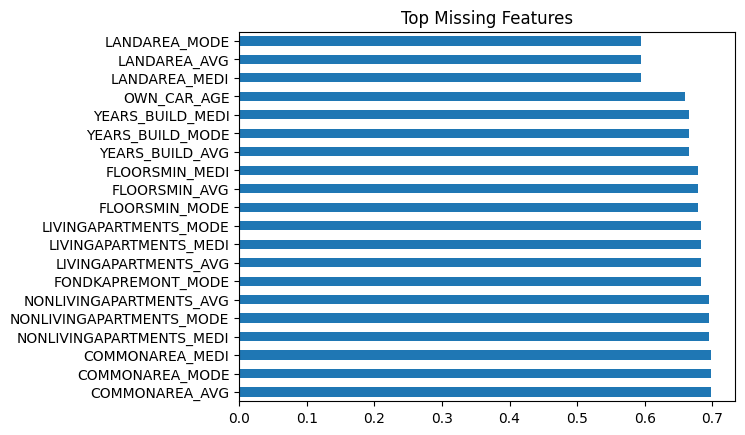

In [ ]:
missing[missing > 0].head(20).plot(kind='barh')
plt.title('Top Missing Features')
plt.show()

### Numerical Feature Overview

In [ ]:
num_cols = app_train.select_dtypes(include='number').columns

app_train[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
SK_ID_CURR,307511.0,278180.518577,102790.175348,100002.0,189145.5,278202.0,367142.5,456255.0
TARGET,307511.0,0.080729,0.272419,0.0,0.0,0.0,0.0,1.0
CNT_CHILDREN,307511.0,0.417052,0.722121,0.0,0.0,0.0,1.0,19.0
AMT_INCOME_TOTAL,307511.0,168797.919297,237123.146279,25650.0,112500.0,147150.0,202500.0,117000000.0
AMT_CREDIT,307511.0,599025.937500,402479.531250,45000.0,270000.0,513531.0,808650.0,4050000.0
...,...,...,...,...,...,...,...,...
AMT_REQ_CREDIT_BUREAU_DAY,265992.0,0.007000,0.110626,0.0,0.0,0.0,0.0,9.0
AMT_REQ_CREDIT_BUREAU_WEEK,265992.0,0.034362,0.204412,0.0,0.0,0.0,0.0,8.0
AMT_REQ_CREDIT_BUREAU_MON,265992.0,0.267395,0.916884,0.0,0.0,0.0,0.0,27.0
AMT_REQ_CREDIT_BUREAU_QRT,265992.0,0.265474,0.795006,0.0,0.0,0.0,0.0,261.0


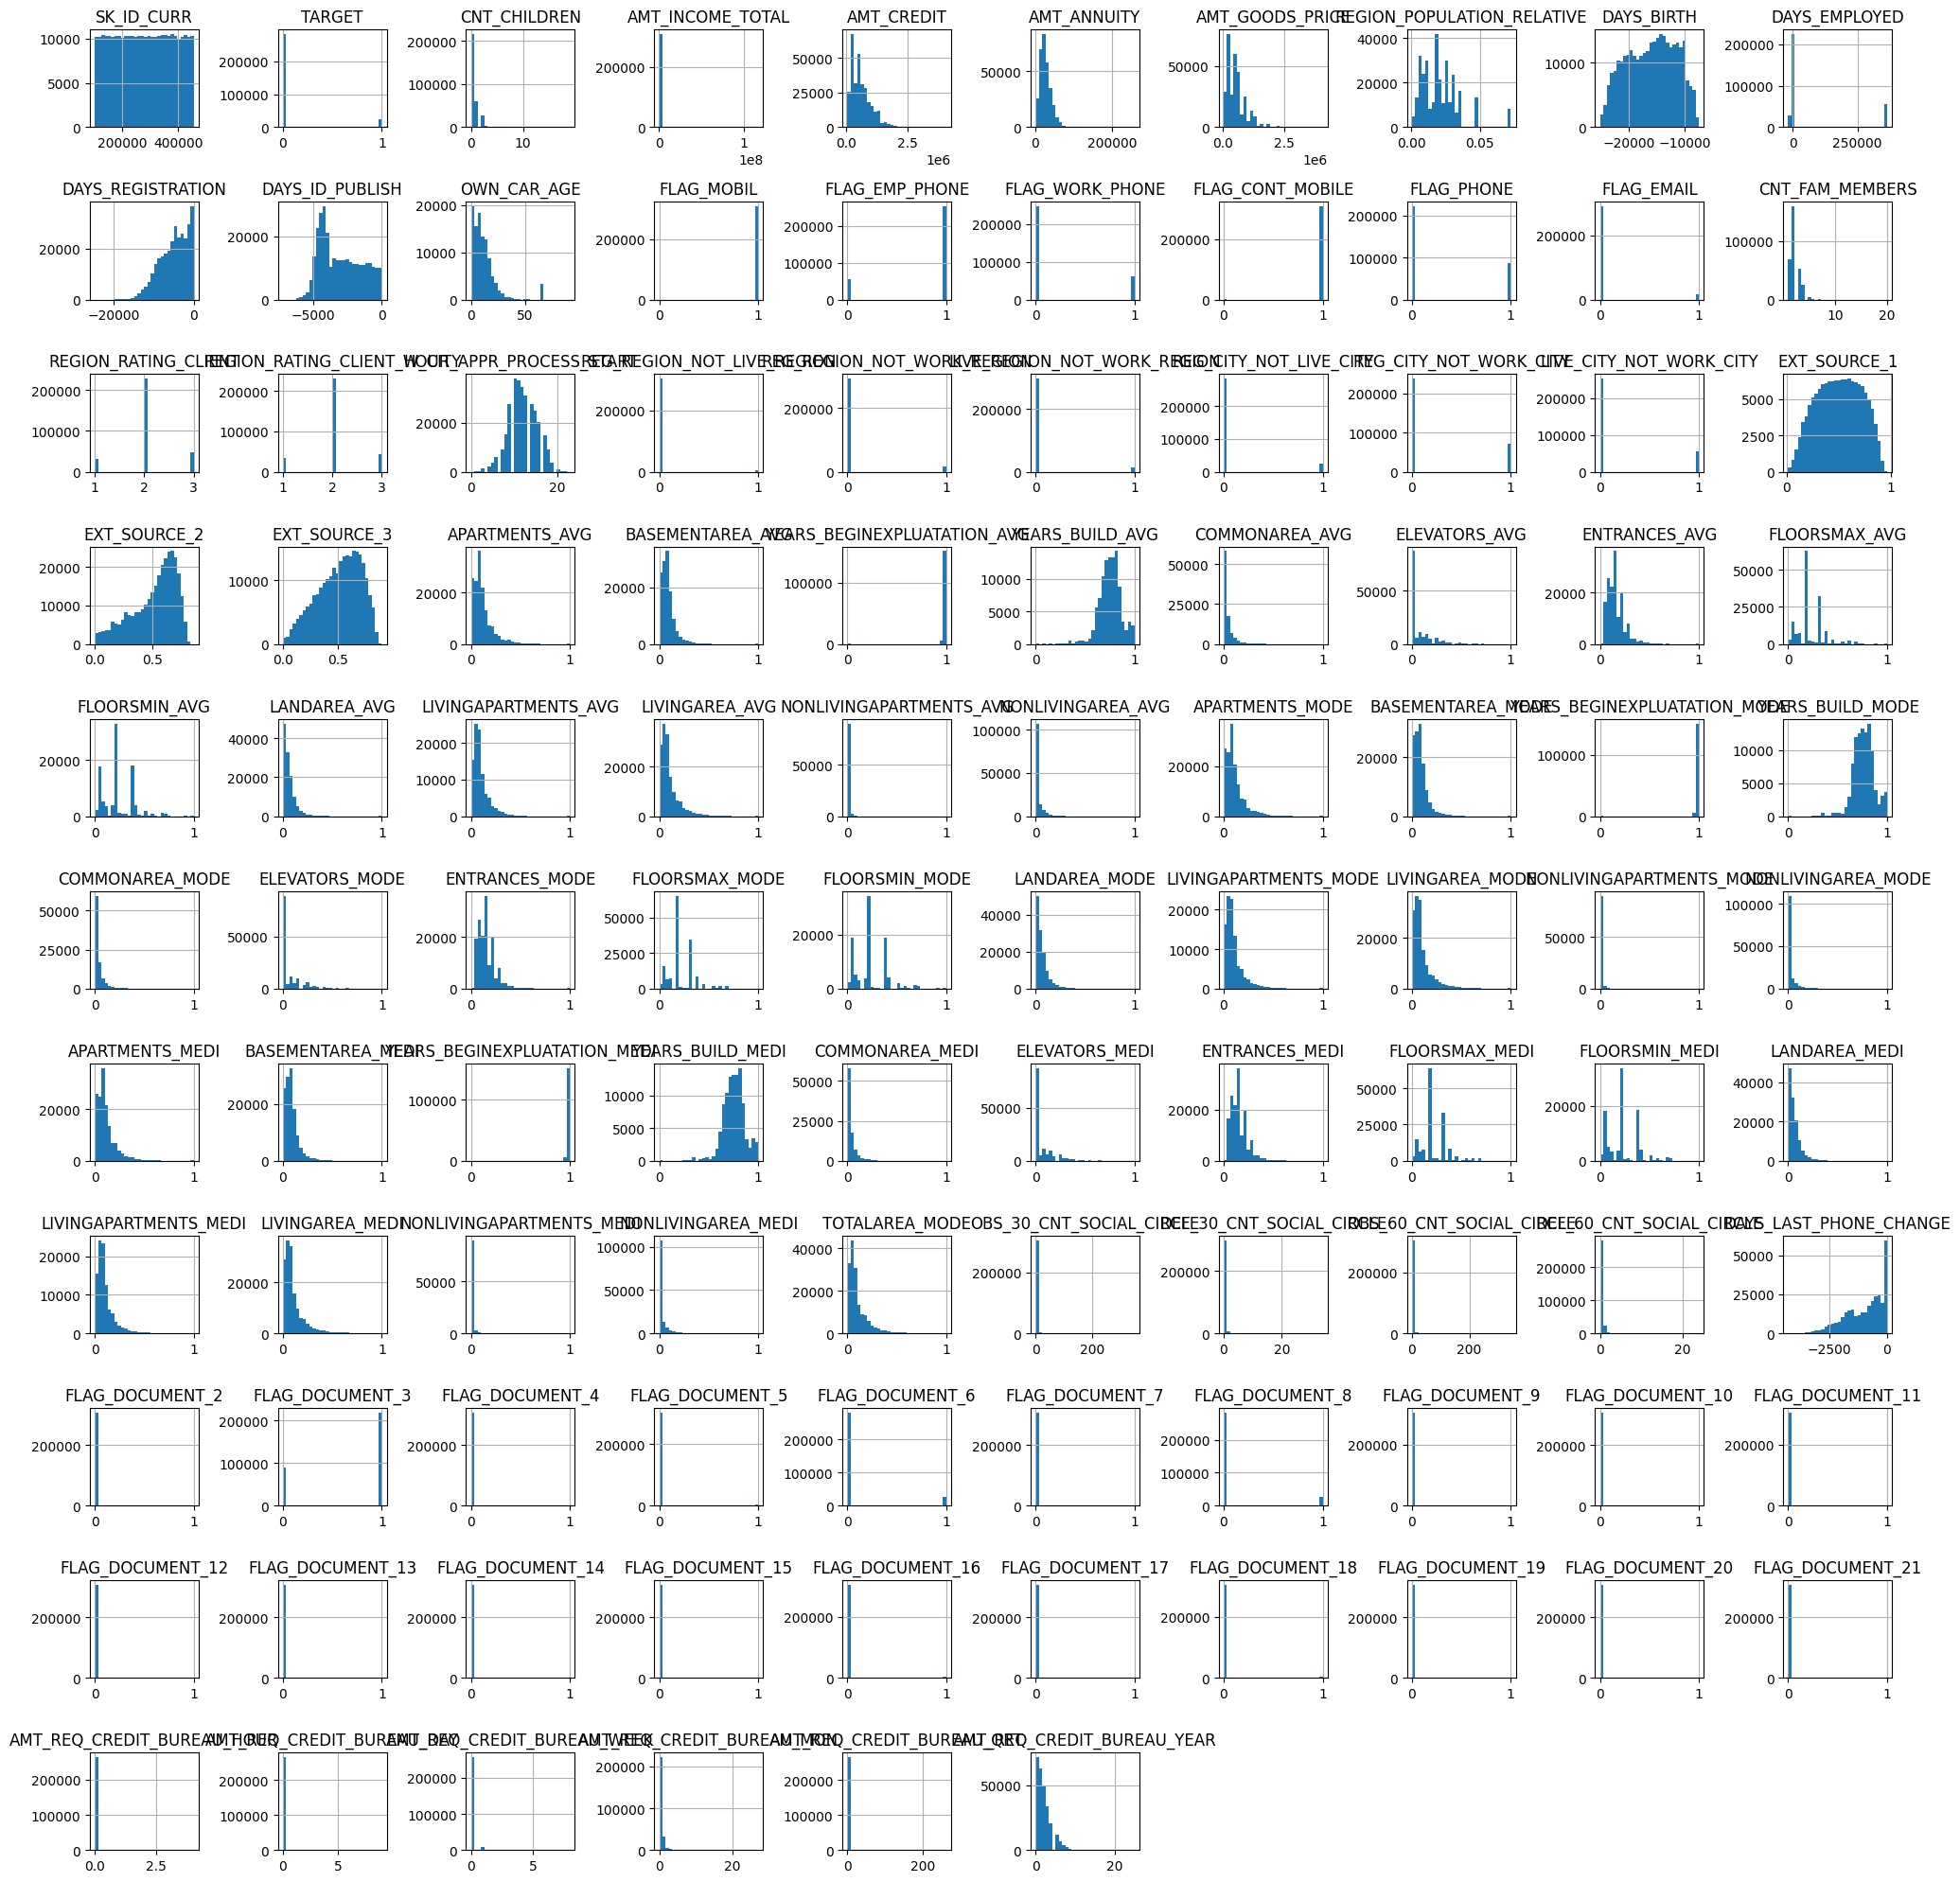

In [ ]:
import matplotlib.pyplot as plt

app_train[num_cols].hist(figsize=(20, 20), bins=30)
plt.tight_layout()
plt.show()


### Skewness Check

In [ ]:
skewness = app_train[num_cols].skew().sort_values(ascending=False)
skewness.head(20)

,0
FLAG_DOCUMENT_12,392.114779
AMT_INCOME_TOTAL,391.559654
FLAG_DOCUMENT_10,209.589054
FLAG_DOCUMENT_2,153.791817
AMT_REQ_CREDIT_BUREAU_QRT,134.365768
FLAG_DOCUMENT_4,110.894364
FLAG_DOCUMENT_7,72.174108
FLAG_DOCUMENT_17,61.214140
FLAG_DOCUMENT_21,54.612939
FLAG_DOCUMENT_20,44.364897


### Relationship with Target

In [ ]:
corr_target = app_train[num_cols].corr()['TARGET'].sort_values(ascending=False)

print("Top Positive Correlation:")
print(corr_target.head(10))

print("\nTop Negative Correlation:")
print(corr_target.tail(10))

Top Positive Correlation:
TARGET                         1.000000
DAYS_BIRTH                     0.078239
REGION_RATING_CLIENT_W_CITY    0.060893
REGION_RATING_CLIENT           0.058899
DAYS_LAST_PHONE_CHANGE         0.055218
DAYS_ID_PUBLISH                0.051457
REG_CITY_NOT_WORK_CITY         0.050994
FLAG_EMP_PHONE                 0.045982
REG_CITY_NOT_LIVE_CITY         0.044395
FLAG_DOCUMENT_3                0.044346
Name: TARGET, dtype: float64

Top Negative Correlation:
ELEVATORS_AVG                -0.034199
REGION_POPULATION_RELATIVE   -0.037227
AMT_GOODS_PRICE              -0.039645
FLOORSMAX_MODE               -0.043226
FLOORSMAX_MEDI               -0.043768
FLOORSMAX_AVG                -0.044003
DAYS_EMPLOYED                -0.044932
EXT_SOURCE_1                 -0.155317
EXT_SOURCE_2                 -0.160472
EXT_SOURCE_3                 -0.178919
Name: TARGET, dtype: float64


### Boxplot Top Features ONLY

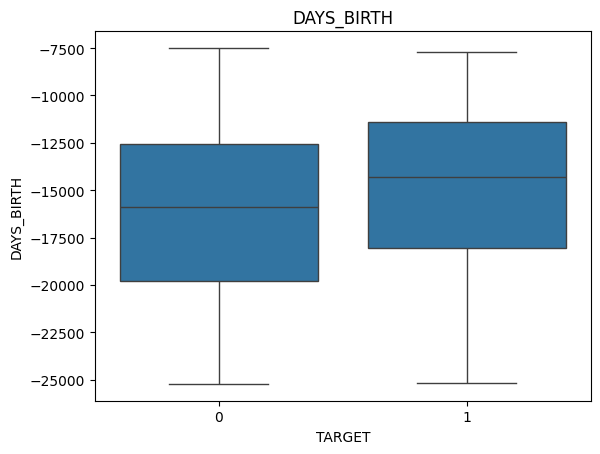

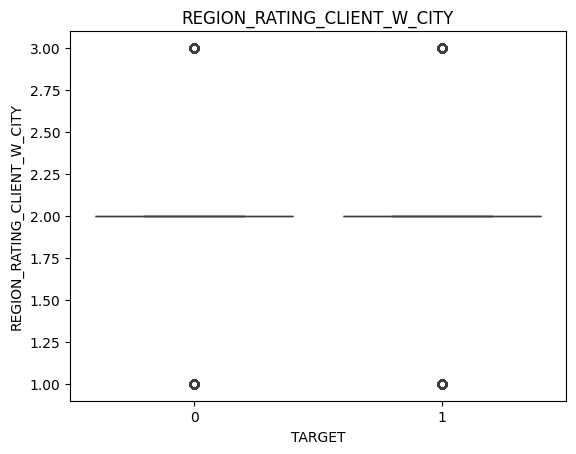

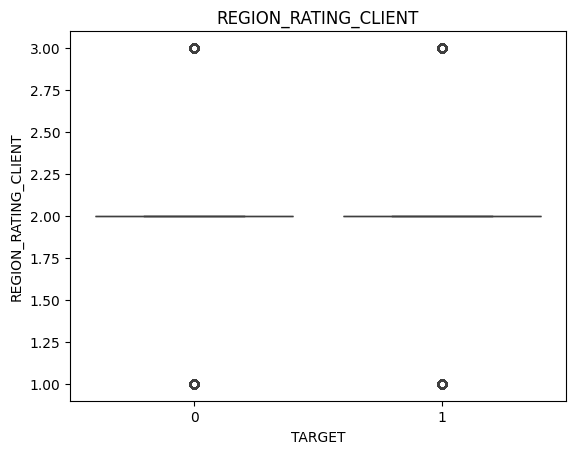

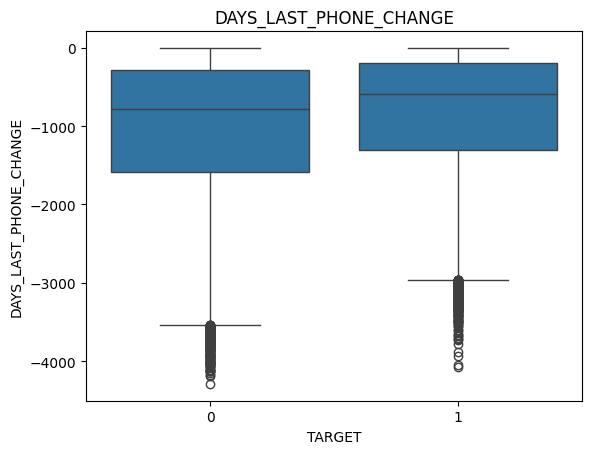

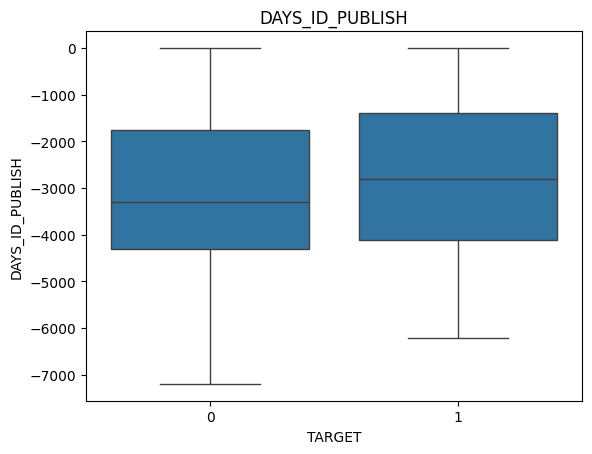

In [ ]:
top_features = corr_target.index[1:6]  # skip TARGET

for col in top_features:
    plt.figure()
    sns.boxplot(x='TARGET', y=col, data=app_train)
    plt.title(col)
    plt.show()

### Categorical Analysis

In [ ]:
cat_cols = app_train.select_dtypes(include='object').columns

app_train[cat_cols].describe().T

,count,unique,top,freq
NAME_CONTRACT_TYPE,307511,2,Cash loans,278232
CODE_GENDER,307511,3,F,202448
FLAG_OWN_CAR,307511,2,N,202924
FLAG_OWN_REALTY,307511,2,Y,213312
NAME_TYPE_SUITE,306219,7,Unaccompanied,248526
NAME_INCOME_TYPE,307511,8,Working,158774
NAME_EDUCATION_TYPE,307511,5,Secondary / secondary special,218391
NAME_FAMILY_STATUS,307511,6,Married,196432
NAME_HOUSING_TYPE,307511,6,House / apartment,272868
OCCUPATION_TYPE,211120,18,Laborers,55186


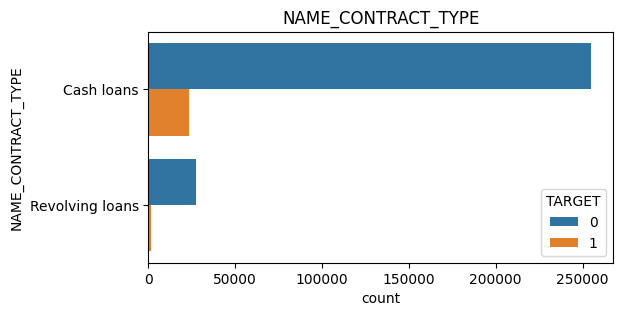

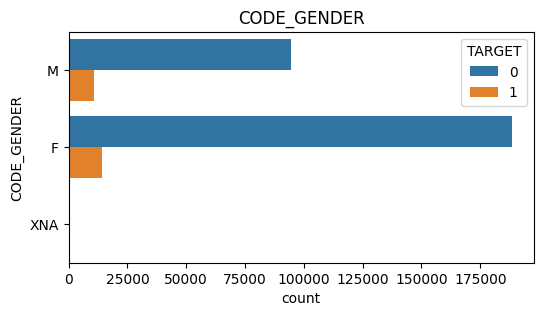

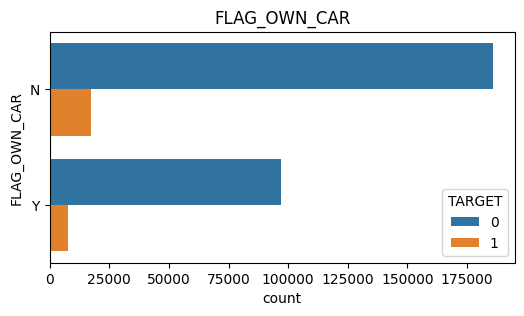

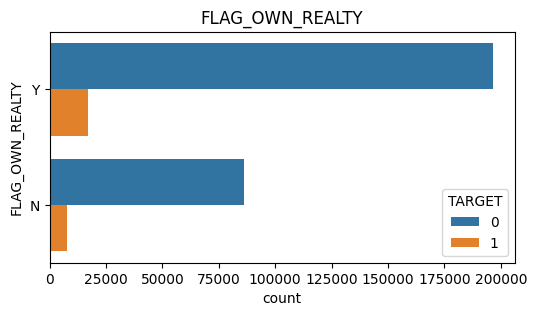

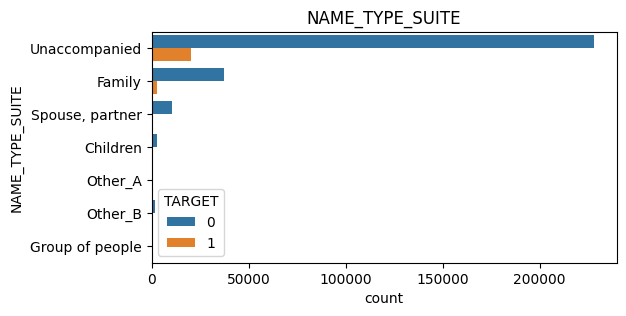

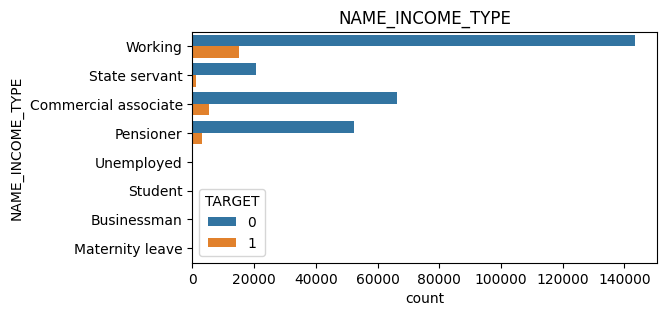

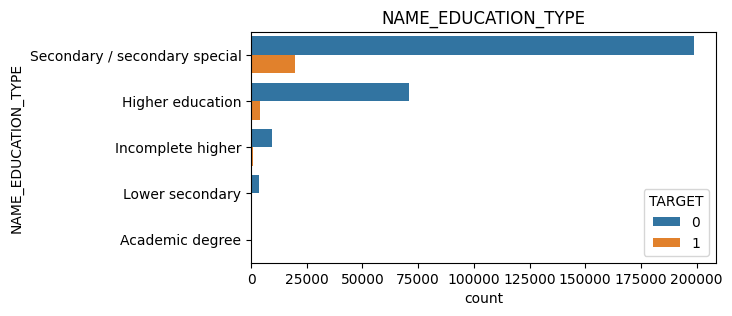

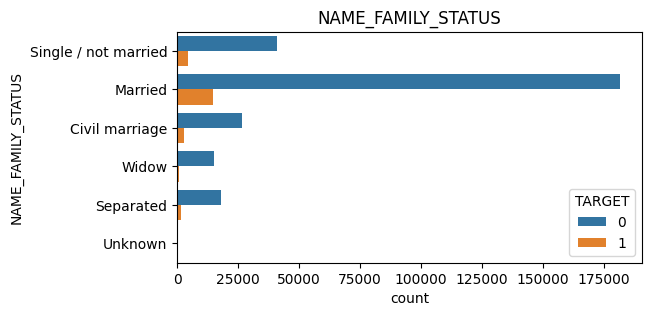

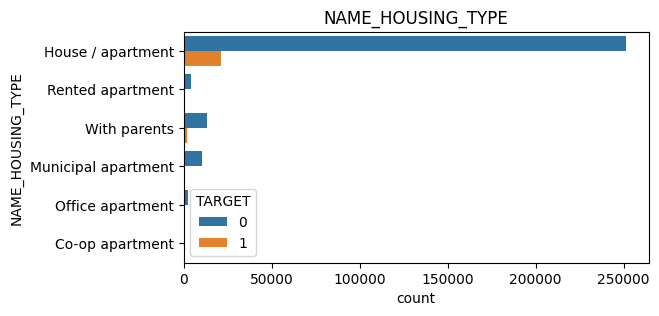

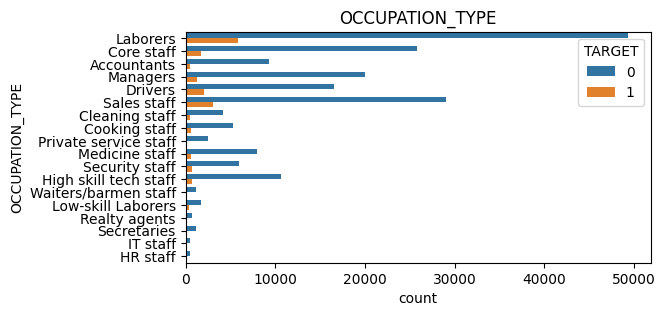

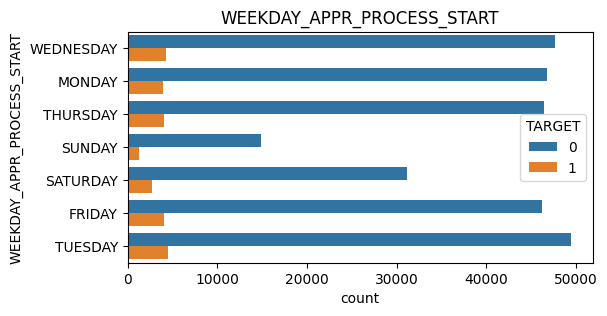

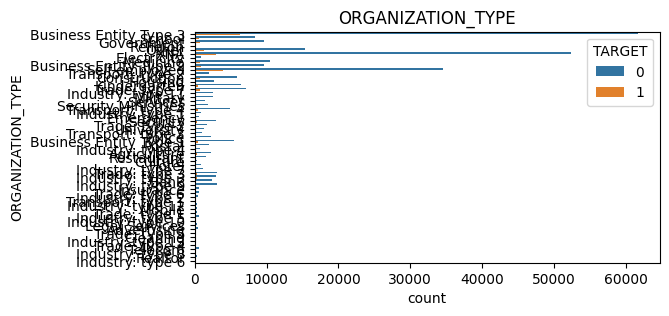

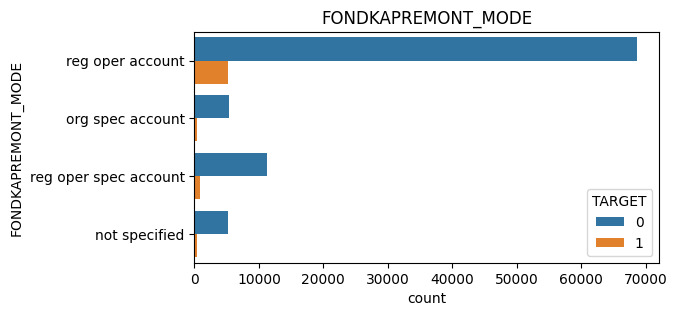

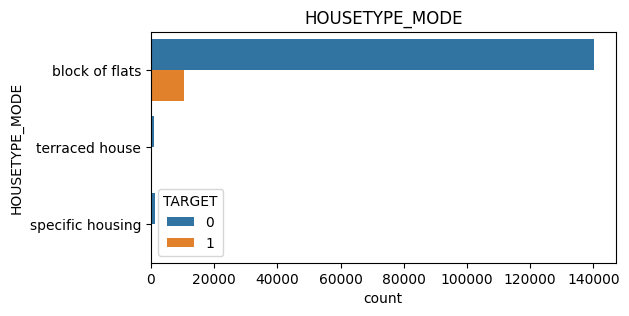

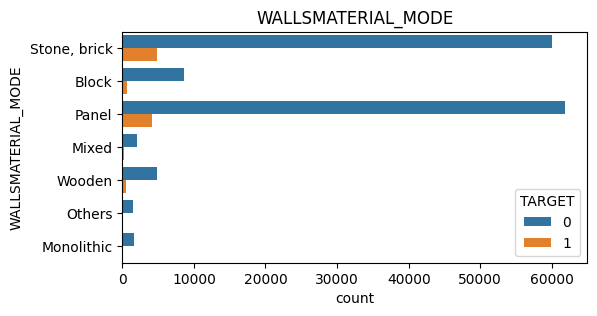

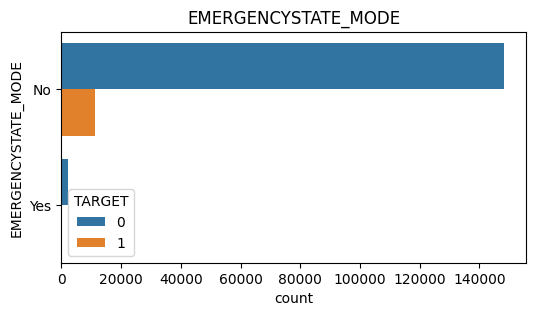

In [ ]:
cat_cols = app_train.select_dtypes(include='object').columns

for col in cat_cols:
    plt.figure(figsize=(6,3))
    sns.countplot(y=col, hue='TARGET', data=app_train)
    plt.title(col)
    plt.show()

### Missing Value Summary

In [ ]:
missing = app_train.isnull().mean().sort_values(ascending=False)

missing_df = pd.DataFrame({
    'feature': missing.index,
    'missing_ratio': missing.values
})

missing_df.head(20)

,feature,missing_ratio
0,COMMONAREA_AVG,0.698723
1,COMMONAREA_MODE,0.698723
2,COMMONAREA_MEDI,0.698723
3,NONLIVINGAPARTMENTS_MEDI,0.694330
4,NONLIVINGAPARTMENTS_MODE,0.694330
5,NONLIVINGAPARTMENTS_AVG,0.694330
6,FONDKAPREMONT_MODE,0.683862
7,LIVINGAPARTMENTS_AVG,0.683550
8,LIVINGAPARTMENTS_MEDI,0.683550
9,LIVINGAPARTMENTS_MODE,0.683550


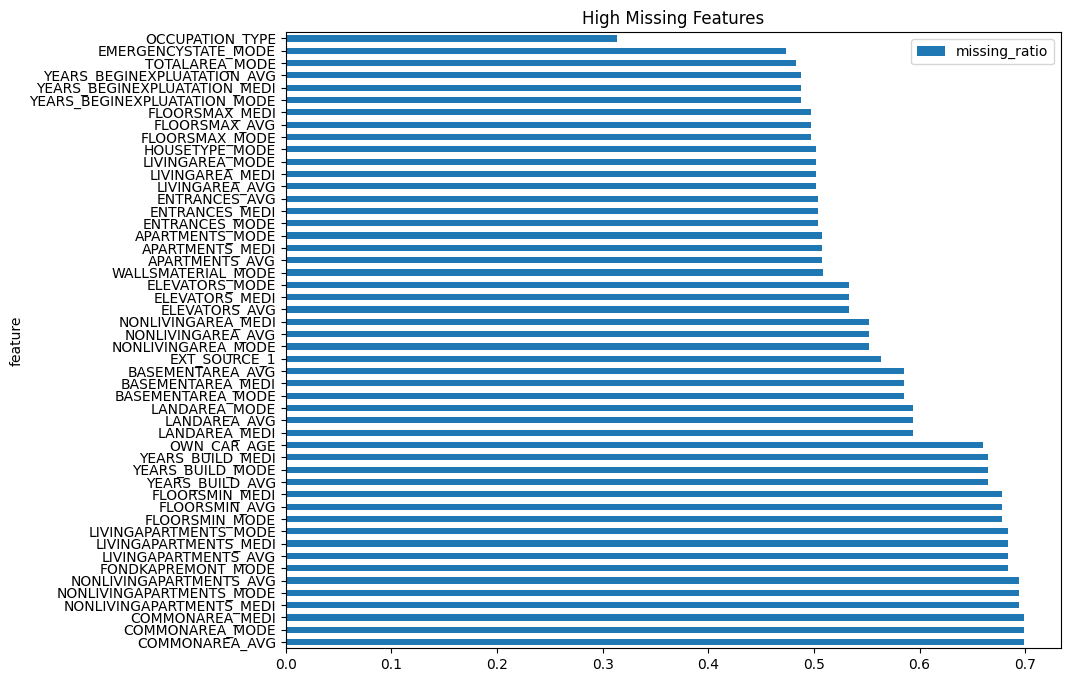

In [ ]:
missing_df[missing_df['missing_ratio'] > 0.3].plot(
    x='feature', y='missing_ratio', kind='barh', figsize=(10,8)
)
plt.title('High Missing Features')
plt.show()

### Anomaly Detection

In [ ]:
for col in num_cols:
    if app_train[col].max() > 1e6:
        print(f"{col} has extreme values")

AMT_INCOME_TOTAL has extreme values
AMT_CREDIT has extreme values
AMT_GOODS_PRICE has extreme values


### Key Feature Quick Check

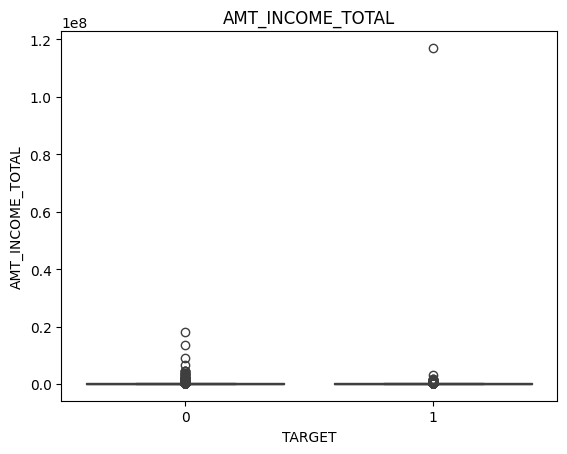

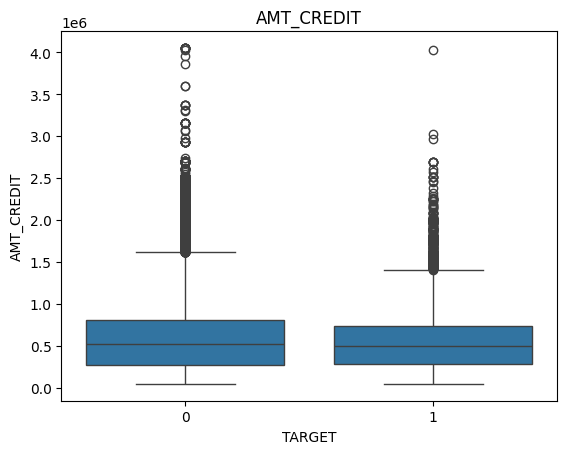

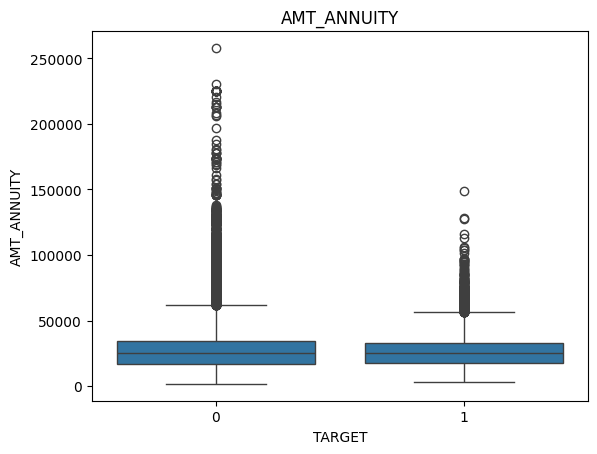

In [ ]:
key_cols = ['AMT_INCOME_TOTAL', 'AMT_CREDIT', 'AMT_ANNUITY']

for col in key_cols:
    sns.boxplot(x='TARGET', y=col, data=app_train)
    plt.title(col)
    plt.show()

## Data Preprocessing

### Data Cleaning & Feature Engineering

#### **app_train** cleaning & feature engineering

In [ ]:
# =========================
# 1.A APP TRAIN - CLEANING & FEATURE ENGINEERING
# =========================
import numpy as np
import pandas as pd

df = app_train.copy()

# --- Helper ---
def safe_div(a, b):
    return np.where((b == 0) | (pd.isna(b)), 0, a / b)

# --- 1. DATA CLEANING ---
df['DAYS_EMPLOYED'] = df['DAYS_EMPLOYED'].replace(365243, np.nan)

missing_ratio = df.isnull().mean()
high_missing_cols = missing_ratio[missing_ratio > 0.6].index.tolist()
df = df.drop(columns=high_missing_cols)
print(f"Dropped {len(high_missing_cols)} high-missing columns: {high_missing_cols}")

num_cols = df.select_dtypes(include='number').columns
cat_cols = df.select_dtypes(include='object').columns

df[num_cols] = df[num_cols].fillna(df[num_cols].median())
df[cat_cols] = df[cat_cols].fillna(df[cat_cols].mode().iloc[0])

# --- 2. FEATURE ENGINEERING (pakai pd.concat agar tidak fragmented) ---
new_features = {}

# Financial ratios
new_features['CREDIT_INCOME_RATIO']   = safe_div(df['AMT_CREDIT'], df['AMT_INCOME_TOTAL'])
new_features['ANNUITY_INCOME_RATIO']  = safe_div(df['AMT_ANNUITY'], df['AMT_INCOME_TOTAL'])
new_features['CREDIT_ANNUITY_RATIO']  = safe_div(df['AMT_CREDIT'], df['AMT_ANNUITY'])
new_features['GOODS_CREDIT_RATIO']    = safe_div(df['AMT_GOODS_PRICE'], df['AMT_CREDIT'])

# Family
new_features['INCOME_PER_FAMILY']     = safe_div(df['AMT_INCOME_TOTAL'], df['CNT_FAM_MEMBERS'])
new_features['CHILDREN_RATIO']        = safe_div(df['CNT_CHILDREN'], df['CNT_FAM_MEMBERS'])

# Age & employment
new_features['AGE']                   = df['DAYS_BIRTH'] / -365
new_features['EMPLOYMENT_YEARS']      = df['DAYS_EMPLOYED'].abs() / 365
new_features['EMPLOYMENT_RATIO']      = safe_div(df['DAYS_EMPLOYED'], df['DAYS_BIRTH'])
new_features['EMPLOYED_TO_AGE_RATIO'] = safe_div(new_features['EMPLOYMENT_YEARS'],
                                                   new_features['AGE'])

# ID & Registration age
new_features['ID_PUBLISH_YEARS']      = df['DAYS_ID_PUBLISH'] / -365
new_features['REGISTRATION_YEARS']    = df['DAYS_REGISTRATION'] / -365

# External score — ini fitur PALING PENTING di dataset ini
new_features['EXT_SOURCE_MEAN']       = df[['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']].mean(axis=1)
new_features['EXT_SOURCE_STD']        = df[['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']].std(axis=1)
new_features['EXT_SOURCE_MIN']        = df[['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']].min(axis=1)
new_features['EXT_SOURCE_MAX']        = df[['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']].max(axis=1)
new_features['EXT_SOURCE_PROD']       = (df['EXT_SOURCE_1'] *
                                          df['EXT_SOURCE_2'] *
                                          df['EXT_SOURCE_3'])
# Weighted EXT_SOURCE (EXT_SOURCE_2 paling predictive)
new_features['EXT_SOURCE_WEIGHTED']   = (0.2 * df['EXT_SOURCE_1'] +
                                          0.5 * df['EXT_SOURCE_2'] +
                                          0.3 * df['EXT_SOURCE_3'])

# EXT_SOURCE vs Age interaction
new_features['EXT2_AGE_RATIO']        = safe_div(df['EXT_SOURCE_2'], new_features['AGE'])

# Log transform
new_features['LOG_INCOME']            = np.log1p(df['AMT_INCOME_TOTAL'])
new_features['LOG_CREDIT']            = np.log1p(df['AMT_CREDIT'])
new_features['LOG_ANNUITY']           = np.log1p(df['AMT_ANNUITY'])

# Credit bureau request pattern (banyak request = risiko tinggi)
new_features['CREDIT_REQ_TOTAL']      = (df['AMT_REQ_CREDIT_BUREAU_DAY'].fillna(0) +
                                          df['AMT_REQ_CREDIT_BUREAU_WEEK'].fillna(0) +
                                          df['AMT_REQ_CREDIT_BUREAU_MON'].fillna(0))

# Concat semua new features sekaligus (hindari PerformanceWarning)
df = pd.concat([df, pd.DataFrame(new_features, index=df.index)], axis=1)

# --- 3. FINAL CHECK ---
print("Train shape:", df.shape)
print("Missing remaining:", df.isnull().mean().sort_values(ascending=False).head())

Dropped 17 high-missing columns: ['OWN_CAR_AGE', 'YEARS_BUILD_AVG', 'COMMONAREA_AVG', 'FLOORSMIN_AVG', 'LIVINGAPARTMENTS_AVG', 'NONLIVINGAPARTMENTS_AVG', 'YEARS_BUILD_MODE', 'COMMONAREA_MODE', 'FLOORSMIN_MODE', 'LIVINGAPARTMENTS_MODE', 'NONLIVINGAPARTMENTS_MODE', 'YEARS_BUILD_MEDI', 'COMMONAREA_MEDI', 'FLOORSMIN_MEDI', 'LIVINGAPARTMENTS_MEDI', 'NONLIVINGAPARTMENTS_MEDI', 'FONDKAPREMONT_MODE']
Train shape: (307511, 128)
Missing remaining: SK_ID_CURR            0.0
TARGET                0.0
NAME_CONTRACT_TYPE    0.0
CODE_GENDER           0.0
FLAG_OWN_CAR          0.0
dtype: float64


#### **app_test** cleaning & feature engineering

In [ ]:
# =========================
# 1.B APP TEST - CLEANING & FEATURE ENGINEERING
# =========================

df_test = app_test.copy()

# --- 1. DATA CLEANING ---
df_test['DAYS_EMPLOYED'] = df_test['DAYS_EMPLOYED'].replace(365243, np.nan)
df_test = df_test.drop(columns=high_missing_cols, errors='ignore')

num_cols_test = df_test.select_dtypes(include='number').columns
cat_cols_test = df_test.select_dtypes(include='object').columns

df_test[num_cols_test] = df_test[num_cols_test].fillna(df_test[num_cols_test].median())
df_test[cat_cols_test] = df_test[cat_cols_test].fillna(df_test[cat_cols_test].mode().iloc[0])

# --- 2. FEATURE ENGINEERING (identik dengan train, pakai pd.concat) ---
new_features_test = {}

new_features_test['CREDIT_INCOME_RATIO']   = safe_div(df_test['AMT_CREDIT'], df_test['AMT_INCOME_TOTAL'])
new_features_test['ANNUITY_INCOME_RATIO']  = safe_div(df_test['AMT_ANNUITY'], df_test['AMT_INCOME_TOTAL'])
new_features_test['CREDIT_ANNUITY_RATIO']  = safe_div(df_test['AMT_CREDIT'], df_test['AMT_ANNUITY'])
new_features_test['GOODS_CREDIT_RATIO']    = safe_div(df_test['AMT_GOODS_PRICE'], df_test['AMT_CREDIT'])

new_features_test['INCOME_PER_FAMILY']     = safe_div(df_test['AMT_INCOME_TOTAL'], df_test['CNT_FAM_MEMBERS'])
new_features_test['CHILDREN_RATIO']        = safe_div(df_test['CNT_CHILDREN'], df_test['CNT_FAM_MEMBERS'])

new_features_test['AGE']                   = df_test['DAYS_BIRTH'] / -365
new_features_test['EMPLOYMENT_YEARS']      = df_test['DAYS_EMPLOYED'].abs() / 365
new_features_test['EMPLOYMENT_RATIO']      = safe_div(df_test['DAYS_EMPLOYED'], df_test['DAYS_BIRTH'])
new_features_test['EMPLOYED_TO_AGE_RATIO'] = safe_div(new_features_test['EMPLOYMENT_YEARS'],
                                                        new_features_test['AGE'])

new_features_test['ID_PUBLISH_YEARS']      = df_test['DAYS_ID_PUBLISH'] / -365
new_features_test['REGISTRATION_YEARS']    = df_test['DAYS_REGISTRATION'] / -365

new_features_test['EXT_SOURCE_MEAN']       = df_test[['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']].mean(axis=1)
new_features_test['EXT_SOURCE_STD']        = df_test[['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']].std(axis=1)
new_features_test['EXT_SOURCE_MIN']        = df_test[['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']].min(axis=1)
new_features_test['EXT_SOURCE_MAX']        = df_test[['EXT_SOURCE_1','EXT_SOURCE_2','EXT_SOURCE_3']].max(axis=1)
new_features_test['EXT_SOURCE_PROD']       = (df_test['EXT_SOURCE_1'] *
                                               df_test['EXT_SOURCE_2'] *
                                               df_test['EXT_SOURCE_3'])
new_features_test['EXT_SOURCE_WEIGHTED']   = (0.2 * df_test['EXT_SOURCE_1'] +
                                               0.5 * df_test['EXT_SOURCE_2'] +
                                               0.3 * df_test['EXT_SOURCE_3'])
new_features_test['EXT2_AGE_RATIO']        = safe_div(df_test['EXT_SOURCE_2'],
                                                        new_features_test['AGE'])

new_features_test['LOG_INCOME']            = np.log1p(df_test['AMT_INCOME_TOTAL'])
new_features_test['LOG_CREDIT']            = np.log1p(df_test['AMT_CREDIT'])
new_features_test['LOG_ANNUITY']           = np.log1p(df_test['AMT_ANNUITY'])

new_features_test['CREDIT_REQ_TOTAL']      = (df_test['AMT_REQ_CREDIT_BUREAU_DAY'].fillna(0) +
                                               df_test['AMT_REQ_CREDIT_BUREAU_WEEK'].fillna(0) +
                                               df_test['AMT_REQ_CREDIT_BUREAU_MON'].fillna(0))

df_test = pd.concat([df_test, pd.DataFrame(new_features_test, index=df_test.index)], axis=1)

print("Test shape:", df_test.shape)
print("Missing:", df_test.isnull().mean().sort_values(ascending=False).head())

Test shape: (48744, 127)
Missing: SK_ID_CURR            0.0
NAME_CONTRACT_TYPE    0.0
CODE_GENDER           0.0
FLAG_OWN_CAR          0.0
FLAG_OWN_REALTY       0.0
dtype: float64


#### **bureau & bureau_balance** cleaning & feature engineering

In [ ]:
# =========================
# 1.C BUREAU & BUREAU BALANCE
# =========================

df_bureau = bureau.copy()
df_bb     = bureau_balance.copy()

# --- 1. CLEANING BUREAU_BALANCE ---
status_map = {'C':0, 'X':0, '0':0, '1':1, '2':2, '3':3, '4':4, '5':5}
df_bb['STATUS_NUM'] = df_bb['STATUS'].map(status_map).fillna(0)

bb_agg = df_bb.groupby('SK_ID_BUREAU').agg(
    BB_STATUS_MEAN=('STATUS_NUM', 'mean'),
    BB_STATUS_MAX =('STATUS_NUM', 'max'),
    BB_MONTHS_COUNT=('MONTHS_BALANCE', 'count')  # berapa bulan history
).reset_index()

# --- 2. CLEANING BUREAU ---
df_bureau['AMT_CREDIT_SUM_DEBT']  = df_bureau['AMT_CREDIT_SUM_DEBT'].fillna(0)
df_bureau['AMT_CREDIT_SUM']       = df_bureau['AMT_CREDIT_SUM'].fillna(0)
df_bureau['AMT_CREDIT_SUM_LIMIT'] = df_bureau['AMT_CREDIT_SUM_LIMIT'].fillna(0)
df_bureau['DAYS_CREDIT_ENDDATE']  = df_bureau['DAYS_CREDIT_ENDDATE'].fillna(0)
df_bureau['DAYS_CREDIT_UPDATE']   = df_bureau['DAYS_CREDIT_UPDATE'].fillna(0)

# Merge BB ke bureau
df_bureau = df_bureau.merge(bb_agg, on='SK_ID_BUREAU', how='left')

# --- 3. FEATURE ENGINEERING ---
df_bureau['ACTIVE_CREDIT']       = (df_bureau['CREDIT_ACTIVE'] == 'Active').astype(int)
df_bureau['CLOSED_CREDIT']       = (df_bureau['CREDIT_ACTIVE'] == 'Closed').astype(int)
df_bureau['CREDIT_DURATION']     = df_bureau['DAYS_CREDIT_ENDDATE'] - df_bureau['DAYS_CREDIT']
df_bureau['CREDIT_TO_ENDDATE']   = df_bureau['DAYS_CREDIT_ENDDATE']  # hari sampai kredit berakhir
df_bureau['CREDIT_PAST_DUE']     = (df_bureau['AMT_CREDIT_SUM_OVERDUE'] > 0).astype(int)

df_bureau['DEBT_CREDIT_RATIO']   = safe_div(
    df_bureau['AMT_CREDIT_SUM_DEBT'],
    df_bureau['AMT_CREDIT_SUM']
)

# --- 4. AGGREGATION (FIXED — pakai named aggregation, bukan MultiIndex join) ---
bureau_agg = df_bureau.groupby('SK_ID_CURR').agg(
    BURO_COUNT               =('SK_ID_BUREAU',           'count'),
    BURO_AMT_CREDIT_MEAN     =('AMT_CREDIT_SUM',         'mean'),
    BURO_AMT_CREDIT_SUM      =('AMT_CREDIT_SUM',         'sum'),
    BURO_AMT_CREDIT_MAX      =('AMT_CREDIT_SUM',         'max'),
    BURO_AMT_DEBT_MEAN       =('AMT_CREDIT_SUM_DEBT',    'mean'),
    BURO_AMT_DEBT_SUM        =('AMT_CREDIT_SUM_DEBT',    'sum'),
    BURO_AMT_LIMIT_MEAN      =('AMT_CREDIT_SUM_LIMIT',   'mean'),
    BURO_ACTIVE_COUNT        =('ACTIVE_CREDIT',          'sum'),
    BURO_CLOSED_COUNT        =('CLOSED_CREDIT',          'sum'),
    BURO_CREDIT_DURATION_MEAN=('CREDIT_DURATION',        'mean'),
    BURO_DEBT_RATIO_MEAN     =('DEBT_CREDIT_RATIO',      'mean'),
    BURO_PAST_DUE_COUNT      =('CREDIT_PAST_DUE',        'sum'),
    BURO_BB_STATUS_MEAN      =('BB_STATUS_MEAN',         'mean'),
    BURO_BB_STATUS_MAX       =('BB_STATUS_MAX',          'max'),
    BURO_BB_MONTHS_MEAN      =('BB_MONTHS_COUNT',        'mean'),
    BURO_DAYS_CREDIT_MEAN    =('DAYS_CREDIT',            'mean'),
    BURO_DAYS_UPDATE_MEAN    =('DAYS_CREDIT_UPDATE',     'mean')
).reset_index()

# Cross-bureau features
bureau_agg['BURO_ACTIVE_RATIO']  = safe_div(
    bureau_agg['BURO_ACTIVE_COUNT'],
    bureau_agg['BURO_COUNT']
)
bureau_agg['BURO_DEBT_TO_CREDIT'] = safe_div(
    bureau_agg['BURO_AMT_DEBT_SUM'],
    bureau_agg['BURO_AMT_CREDIT_SUM']
)

print("Bureau Aggregated Shape:", bureau_agg.shape)
print("Columns:", bureau_agg.columns.tolist())

Bureau Aggregated Shape: (305811, 20)
Columns: ['SK_ID_CURR', 'BURO_COUNT', 'BURO_AMT_CREDIT_MEAN', 'BURO_AMT_CREDIT_SUM', 'BURO_AMT_CREDIT_MAX', 'BURO_AMT_DEBT_MEAN', 'BURO_AMT_DEBT_SUM', 'BURO_AMT_LIMIT_MEAN', 'BURO_ACTIVE_COUNT', 'BURO_CLOSED_COUNT', 'BURO_CREDIT_DURATION_MEAN', 'BURO_DEBT_RATIO_MEAN', 'BURO_PAST_DUE_COUNT', 'BURO_BB_STATUS_MEAN', 'BURO_BB_STATUS_MAX', 'BURO_BB_MONTHS_MEAN', 'BURO_DAYS_CREDIT_MEAN', 'BURO_DAYS_UPDATE_MEAN', 'BURO_ACTIVE_RATIO', 'BURO_DEBT_TO_CREDIT']


#### **POS_CASH_balance** cleaning & feature engineering

In [ ]:
# =========================
# 1.D POS CASH BALANCE
# =========================

df_pos = pos_cash.copy()

df_pos[['CNT_INSTALMENT', 'CNT_INSTALMENT_FUTURE']] = \
    df_pos[['CNT_INSTALMENT', 'CNT_INSTALMENT_FUTURE']].fillna(0)

# FE
df_pos['LATE_PAYMENT']        = (df_pos['SK_DPD'] > 0).astype(int)
df_pos['LATE_PAYMENT_DEF']    = (df_pos['SK_DPD_DEF'] > 0).astype(int)
df_pos['INSTALMENT_PROGRESS'] = safe_div(
    df_pos['CNT_INSTALMENT'] - df_pos['CNT_INSTALMENT_FUTURE'],
    df_pos['CNT_INSTALMENT']
)

# Aggregation (FIXED — named aggregation)
pos_agg = df_pos.groupby('SK_ID_CURR').agg(
    POS_COUNT              =('SK_ID_PREV',          'count'),
    POS_DPD_MEAN           =('SK_DPD',              'mean'),
    POS_DPD_MAX            =('SK_DPD',              'max'),
    POS_DPD_DEF_MEAN       =('SK_DPD_DEF',          'mean'),
    POS_LATE_PAYMENT_MEAN  =('LATE_PAYMENT',         'mean'),
    POS_LATE_PAYMENT_SUM   =('LATE_PAYMENT',         'sum'),
    POS_LATE_DEF_MEAN      =('LATE_PAYMENT_DEF',     'mean'),
    POS_PROGRESS_MEAN      =('INSTALMENT_PROGRESS',  'mean'),
    POS_MONTHS_COUNT       =('MONTHS_BALANCE',       'count')
).reset_index()

print("POS Cash Shape:", pos_agg.shape)
print("Columns:", pos_agg.columns.tolist())

POS Cash Shape: (337252, 10)
Columns: ['SK_ID_CURR', 'POS_COUNT', 'POS_DPD_MEAN', 'POS_DPD_MAX', 'POS_DPD_DEF_MEAN', 'POS_LATE_PAYMENT_MEAN', 'POS_LATE_PAYMENT_SUM', 'POS_LATE_DEF_MEAN', 'POS_PROGRESS_MEAN', 'POS_MONTHS_COUNT']


#### **credit_card_balance** cleaning, feature engineering, agregation

In [ ]:
# =========================
# 1.E CREDIT CARD BALANCE
# =========================

df_cc = credit_card.copy()

num_cols_cc = df_cc.select_dtypes(include='number').columns
df_cc[num_cols_cc] = df_cc[num_cols_cc].fillna(0)

# FE
df_cc['UTILIZATION']         = safe_div(df_cc['AMT_BALANCE'], df_cc['AMT_CREDIT_LIMIT_ACTUAL'])
df_cc['PAYMENT_RATIO']       = safe_div(df_cc['AMT_PAYMENT_TOTAL_CURRENT'], df_cc['AMT_BALANCE'])
df_cc['MIN_PAYMENT_RATIO']   = safe_div(df_cc['AMT_PAYMENT_CURRENT'], df_cc['AMT_INST_MIN_REGULARITY'])
df_cc['LATE_PAYMENT']        = (df_cc['SK_DPD'] > 0).astype(int)
df_cc['OVER_LIMIT']          = (df_cc['AMT_BALANCE'] > df_cc['AMT_CREDIT_LIMIT_ACTUAL']).astype(int)

# Aggregation (FIXED)
cc_agg = df_cc.groupby('SK_ID_CURR').agg(
    CC_COUNT             =('SK_ID_PREV',            'count'),
    CC_AMT_BALANCE_MEAN  =('AMT_BALANCE',           'mean'),
    CC_AMT_BALANCE_MAX   =('AMT_BALANCE',           'max'),
    CC_UTILIZATION_MEAN  =('UTILIZATION',           'mean'),
    CC_UTILIZATION_MAX   =('UTILIZATION',           'max'),
    CC_PAYMENT_RATIO_MEAN=('PAYMENT_RATIO',         'mean'),
    CC_LATE_PAYMENT_MEAN =('LATE_PAYMENT',          'mean'),
    CC_LATE_PAYMENT_SUM  =('LATE_PAYMENT',          'sum'),
    CC_OVER_LIMIT_MEAN   =('OVER_LIMIT',            'mean'),
    CC_DRAWINGS_MEAN     =('AMT_DRAWINGS_CURRENT',  'mean')
).reset_index()

print("Credit Card Shape:", cc_agg.shape)
print("Columns:", cc_agg.columns.tolist())

Credit Card Shape: (103558, 11)
Columns: ['SK_ID_CURR', 'CC_COUNT', 'CC_AMT_BALANCE_MEAN', 'CC_AMT_BALANCE_MAX', 'CC_UTILIZATION_MEAN', 'CC_UTILIZATION_MAX', 'CC_PAYMENT_RATIO_MEAN', 'CC_LATE_PAYMENT_MEAN', 'CC_LATE_PAYMENT_SUM', 'CC_OVER_LIMIT_MEAN', 'CC_DRAWINGS_MEAN']


#### **previous_application** cleaning, feature engineering, agregation

In [ ]:
# =========================
# 1.F PREVIOUS APPLICATION
# =========================

df_prev = previous_app.copy()

date_cols = ['DAYS_FIRST_DRAWING', 'DAYS_FIRST_DUE', 'DAYS_LAST_DUE_1ST_VERSION',
             'DAYS_LAST_DUE', 'DAYS_TERMINATION']
for col in date_cols:
    df_prev[col] = df_prev[col].replace(365243, np.nan)

num_cols_prev = df_prev.select_dtypes(include='number').columns
df_prev[num_cols_prev] = df_prev[num_cols_prev].fillna(0)

# FE
df_prev['APP_CREDIT_RATIO']    = safe_div(df_prev['AMT_APPLICATION'], df_prev['AMT_CREDIT'])
df_prev['DOWNPAYMENT_RATIO']   = safe_div(df_prev['AMT_DOWN_PAYMENT'], df_prev['AMT_CREDIT'])
df_prev['APPROVED']            = (df_prev['NAME_CONTRACT_STATUS'] == 'Approved').astype(int)
df_prev['REFUSED']             = (df_prev['NAME_CONTRACT_STATUS'] == 'Refused').astype(int)
df_prev['CANCELLED']           = (df_prev['NAME_CONTRACT_STATUS'] == 'Canceled').astype(int)
df_prev['PAYMENT_RATIO']       = safe_div(
    df_prev['AMT_ANNUITY'] * df_prev['CNT_PAYMENT'],
    df_prev['AMT_CREDIT']
)
df_prev['CREDIT_TO_GOODS']     = safe_div(df_prev['AMT_CREDIT'], df_prev['AMT_GOODS_PRICE'])

# Aggregation (FIXED)
prev_agg = df_prev.groupby('SK_ID_CURR').agg(
    PREV_COUNT             =('SK_ID_PREV',          'count'),
    PREV_AMT_APP_MEAN      =('AMT_APPLICATION',     'mean'),
    PREV_AMT_CREDIT_MEAN   =('AMT_CREDIT',          'mean'),
    PREV_AMT_CREDIT_SUM    =('AMT_CREDIT',          'sum'),
    PREV_APP_CREDIT_RATIO  =('APP_CREDIT_RATIO',    'mean'),
    PREV_DOWNPAYMENT_RATIO =('DOWNPAYMENT_RATIO',   'mean'),
    PREV_APPROVED_MEAN     =('APPROVED',            'mean'),  # approval rate
    PREV_APPROVED_SUM      =('APPROVED',            'sum'),
    PREV_REFUSED_MEAN      =('REFUSED',             'mean'),  # refusal rate — penting!
    PREV_REFUSED_SUM       =('REFUSED',             'sum'),
    PREV_CANCELLED_MEAN    =('CANCELLED',           'mean'),
    PREV_PAYMENT_RATIO     =('PAYMENT_RATIO',       'mean'),
    PREV_CREDIT_TO_GOODS   =('CREDIT_TO_GOODS',     'mean'),
    PREV_DAYS_DECISION_MEAN=('DAYS_DECISION',       'mean'),
    PREV_CNT_PAYMENT_MEAN  =('CNT_PAYMENT',         'mean')
).reset_index()

print("Previous App Shape:", prev_agg.shape)
print("Columns:", prev_agg.columns.tolist())

Previous App Shape: (338857, 16)
Columns: ['SK_ID_CURR', 'PREV_COUNT', 'PREV_AMT_APP_MEAN', 'PREV_AMT_CREDIT_MEAN', 'PREV_AMT_CREDIT_SUM', 'PREV_APP_CREDIT_RATIO', 'PREV_DOWNPAYMENT_RATIO', 'PREV_APPROVED_MEAN', 'PREV_APPROVED_SUM', 'PREV_REFUSED_MEAN', 'PREV_REFUSED_SUM', 'PREV_CANCELLED_MEAN', 'PREV_PAYMENT_RATIO', 'PREV_CREDIT_TO_GOODS', 'PREV_DAYS_DECISION_MEAN', 'PREV_CNT_PAYMENT_MEAN']


#### **installments_payments** cleaning, feature engineering, agregation

In [ ]:
# =========================
# 1.G INSTALLMENTS PAYMENTS
# =========================

df_inst = installments.copy()

num_cols_inst = df_inst.select_dtypes(include='number').columns
df_inst[num_cols_inst] = df_inst[num_cols_inst].fillna(0)

# FE
df_inst['PAYMENT_DELAY']     = df_inst['DAYS_ENTRY_PAYMENT'] - df_inst['DAYS_INSTALMENT']
df_inst['LATE_PAYMENT']      = (df_inst['PAYMENT_DELAY'] > 0).astype(int)
df_inst['PAYMENT_RATIO']     = safe_div(df_inst['AMT_PAYMENT'], df_inst['AMT_INSTALMENT'])
df_inst['UNDERPAYMENT']      = (df_inst['AMT_PAYMENT'] < df_inst['AMT_INSTALMENT']).astype(int)
df_inst['OVERPAYMENT']       = (df_inst['AMT_PAYMENT'] > df_inst['AMT_INSTALMENT']).astype(int)

# Aggregation (FIXED)
inst_agg = df_inst.groupby('SK_ID_CURR').agg(
    INST_COUNT              =('SK_ID_PREV',        'count'),
    INST_AMT_PAYMENT_MEAN   =('AMT_PAYMENT',       'mean'),
    INST_AMT_PAYMENT_SUM    =('AMT_PAYMENT',       'sum'),
    INST_PAYMENT_DELAY_MEAN =('PAYMENT_DELAY',     'mean'),
    INST_PAYMENT_DELAY_MAX  =('PAYMENT_DELAY',     'max'),
    INST_LATE_PAYMENT_MEAN  =('LATE_PAYMENT',      'mean'),  # % cicilan terlambat
    INST_LATE_PAYMENT_SUM   =('LATE_PAYMENT',      'sum'),
    INST_PAYMENT_RATIO_MEAN =('PAYMENT_RATIO',     'mean'),
    INST_UNDERPAYMENT_MEAN  =('UNDERPAYMENT',      'mean'),
    INST_OVERPAYMENT_MEAN   =('OVERPAYMENT',       'mean')
).reset_index()

print("Installments Shape:", inst_agg.shape)
print("Columns:", inst_agg.columns.tolist())

Installments Shape: (339587, 11)
Columns: ['SK_ID_CURR', 'INST_COUNT', 'INST_AMT_PAYMENT_MEAN', 'INST_AMT_PAYMENT_SUM', 'INST_PAYMENT_DELAY_MEAN', 'INST_PAYMENT_DELAY_MAX', 'INST_LATE_PAYMENT_MEAN', 'INST_LATE_PAYMENT_SUM', 'INST_PAYMENT_RATIO_MEAN', 'INST_UNDERPAYMENT_MEAN', 'INST_OVERPAYMENT_MEAN']


### Data Integration

#### Cek duplikasi

In [ ]:
def check_duplicates(df, name):
    dup = df['SK_ID_CURR'].duplicated().sum()
    print(f"{name} duplicate SK_ID_CURR: {dup}")

check_duplicates(df,          "application_train")
check_duplicates(bureau_agg,  "bureau")
check_duplicates(prev_agg,    "previous")
check_duplicates(pos_agg,     "pos")
check_duplicates(inst_agg,    "installments")
check_duplicates(cc_agg,      "credit_card")

application_train duplicate SK_ID_CURR: 0
bureau duplicate SK_ID_CURR: 0
previous duplicate SK_ID_CURR: 0
pos duplicate SK_ID_CURR: 0
installments duplicate SK_ID_CURR: 0
credit_card duplicate SK_ID_CURR: 0


#### Merg (train)

In [ ]:
# =========================
# 2.B MERGE TRAIN
# =========================

df_final = df.copy()  # df = hasil 1.A

df_final = df_final.merge(bureau_agg, on='SK_ID_CURR', how='left')
df_final = df_final.merge(prev_agg,   on='SK_ID_CURR', how='left')
df_final = df_final.merge(pos_agg,    on='SK_ID_CURR', how='left')
df_final = df_final.merge(inst_agg,   on='SK_ID_CURR', how='left')
df_final = df_final.merge(cc_agg,     on='SK_ID_CURR', how='left')

print("Final TRAIN shape:", df_final.shape)

Final TRAIN shape: (307511, 191)


#### Merg (test)

In [ ]:
# =========================
# 2.C MERGE TEST
# =========================

df_test_final = df_test.copy()  # df_test = hasil 1.B

df_test_final = df_test_final.merge(bureau_agg, on='SK_ID_CURR', how='left')
df_test_final = df_test_final.merge(prev_agg,   on='SK_ID_CURR', how='left')
df_test_final = df_test_final.merge(pos_agg,    on='SK_ID_CURR', how='left')
df_test_final = df_test_final.merge(inst_agg,   on='SK_ID_CURR', how='left')
df_test_final = df_test_final.merge(cc_agg,     on='SK_ID_CURR', how='left')

print("Final TEST shape:", df_test_final.shape)

Final TEST shape: (48744, 190)


#### Handle Missing (after merge)

In [ ]:
# =========================
# 2.D HANDLE MISSING AFTER MERGE (PERBAIKAN)
# =========================

# Kolom yang NaN karena tidak ada data external (bukan missing biasa)
# → isi -1 sebagai penanda eksplisit "tidak punya riwayat"
external_count_cols = [
    'BURO_COUNT', 'PREV_COUNT', 'POS_COUNT', 'INST_COUNT', 'CC_COUNT'
]

for col in external_count_cols:
    if col in df_final.columns:
        df_final[col]      = df_final[col].fillna(0)
    if col in df_test_final.columns:
        df_test_final[col] = df_test_final[col].fillna(0)

# Kolom ratio/amount dari external → isi 0 (tidak ada transaksi = 0)
num_cols_final      = df_final.select_dtypes(include='number').columns
num_cols_test_final = df_test_final.select_dtypes(include='number').columns

df_final[num_cols_final]           = df_final[num_cols_final].fillna(0)
df_test_final[num_cols_test_final] = df_test_final[num_cols_test_final].fillna(0)

# Kolom object (categorical) sisa
cat_cols_final = df_final.select_dtypes(include='object').columns
cat_cols_test  = df_test_final.select_dtypes(include='object').columns

df_final[cat_cols_final]   = df_final[cat_cols_final].fillna('Unknown')
df_test_final[cat_cols_test] = df_test_final[cat_cols_test].fillna('Unknown')

print("Missing train:", df_final.isnull().sum().sum())
print("Missing test :", df_test_final.isnull().sum().sum())

Missing train: 0
Missing test : 0


#### Final alignment train vs test

In [ ]:
# =========================
# 2.E FINAL ALIGNMENT TRAIN VS TEST (PERBAIKAN)
# =========================

# Simpan target & ID
target     = df_final['TARGET']
train_ids  = df_final['SK_ID_CURR']
test_ids   = df_test_final['SK_ID_CURR']

# Drop dari kedua dataframe
df_features      = df_final.drop(columns=['TARGET', 'SK_ID_CURR'])
df_test_features = df_test_final.drop(columns=['SK_ID_CURR'])

# Align: test harus punya kolom yang sama dengan train
# join='left' → pakai kolom train sebagai acuan
df_features, df_test_features = df_features.align(
    df_test_features,
    join='left',
    axis=1,
    fill_value=0
)

# Verifikasi
assert df_features.shape[1] == df_test_features.shape[1], \
    f"Kolom tidak sama! Train: {df_features.shape[1]}, Test: {df_test_features.shape[1]}"

print("✅ Kolom train == test:", df_features.shape[1])

# Gabungkan kembali
df_final      = pd.concat([train_ids.reset_index(drop=True),
                            df_features.reset_index(drop=True),
                            target.reset_index(drop=True)], axis=1)

df_test_final = pd.concat([test_ids.reset_index(drop=True),
                            df_test_features.reset_index(drop=True)], axis=1)

print("Train shape:", df_final.shape)
print("Test shape :", df_test_final.shape)

✅ Kolom train == test: 189
Train shape: (307511, 191)
Test shape : (48744, 190)


### Save Train & Test

In [ ]:
# =========================
# 2.F SAVE DATA
# =========================
import pandas as pd
import os

base_path = '/content/drive/MyDrive/dataset PBI home credit/'

# Pastikan folder ada
os.makedirs(base_path, exist_ok=True)

# Simpan
df_final.to_csv(base_path + 'final_train.csv', index=False)
df_test_final.to_csv(base_path + 'final_test.csv', index=False)

# Verifikasi
print("✅ Data berhasil disimpan!")
print(f"   final_train.csv → shape : {df_final.shape}")
print(f"   final_test.csv  → shape : {df_test_final.shape}")
print(f"\nKolom train: {df_final.shape[1]} | Kolom test: {df_test_final.shape[1]}")
print(f"Perbedaan kolom (harusnya hanya TARGET):")

cols_train = set(df_final.columns)
cols_test  = set(df_test_final.columns)
print(f"  Ada di train, tidak di test : {cols_train - cols_test}")
print(f"  Ada di test, tidak di train : {cols_test - cols_train}")

✅ Data berhasil disimpan!
   final_train.csv → shape : (307511, 191)
   final_test.csv  → shape : (48744, 190)

Kolom train: 191 | Kolom test: 190
Perbedaan kolom (harusnya hanya TARGET):
  Ada di train, tidak di test : {'TARGET'}
  Ada di test, tidak di train : set()


In [ ]:
import os

train_path = base_path + 'final_train.csv'

print(os.path.exists(train_path))

if os.path.exists(train_path):
    print("Size (MB):", os.path.getsize(train_path)/(1024**2))

True
Size (MB): 398.8099241256714


### Load Dataset

In [ ]:
# =========================
# 2.G LOAD DATA
# =========================
import pandas as pd
import numpy as np

base_path = '/content/drive/MyDrive/dataset PBI home credit/'

df_final      = pd.read_csv(base_path + 'final_train.csv')
df_test_final = pd.read_csv(base_path + 'final_test.csv')

# --- Verifikasi shape ---
print("Train shape :", df_final.shape)
print("Test shape  :", df_test_final.shape)

# --- Verifikasi TARGET ---
print("\nTARGET distribution:")
print(df_final['TARGET'].value_counts())
print(df_final['TARGET'].value_counts(normalize=True).round(4))

# --- Verifikasi kolom kunci masih ada ---
key_cols = [
    'SK_ID_CURR', 'TARGET',
    'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3',
    'EXT_SOURCE_MEAN', 'EXT_SOURCE_PROD', 'EXT_SOURCE_WEIGHTED',
    'BURO_COUNT', 'PREV_COUNT', 'INST_COUNT',
    'CREDIT_INCOME_RATIO', 'ANNUITY_INCOME_RATIO'
]

print("\nCek kolom kunci:")
for col in key_cols:
    status = "✅" if col in df_final.columns else "❌ TIDAK ADA"
    print(f"  {status} {col}")

# --- Verifikasi tidak ada kolom rusak (nama aneh) ---
weird_cols = [c for c in df_final.columns if '___' in c]
if weird_cols:
    print(f"\n⚠️  Kolom nama rusak ditemukan: {weird_cols}")
else:
    print("\n✅ Tidak ada kolom nama rusak")

# --- Cek missing value ---
missing_train = df_final.isnull().sum().sum()
missing_test  = df_test_final.isnull().sum().sum()
print(f"\nMissing train : {missing_train}")
print(f"Missing test  : {missing_test}")

Train shape : (307511, 191)
Test shape  : (48744, 190)

TARGET distribution:
TARGET
0    282686
1     24825
Name: count, dtype: int64
TARGET
0    0.9193
1    0.0807
Name: proportion, dtype: float64

Cek kolom kunci:
  ✅ SK_ID_CURR
  ✅ TARGET
  ✅ EXT_SOURCE_1
  ✅ EXT_SOURCE_2
  ✅ EXT_SOURCE_3
  ✅ EXT_SOURCE_MEAN
  ✅ EXT_SOURCE_PROD
  ✅ EXT_SOURCE_WEIGHTED
  ✅ BURO_COUNT
  ✅ PREV_COUNT
  ✅ INST_COUNT
  ✅ CREDIT_INCOME_RATIO
  ✅ ANNUITY_INCOME_RATIO

✅ Tidak ada kolom nama rusak

Missing train : 0
Missing test  : 0


#### Data Cleaning Final

In [ ]:
# =========================
# 3. FINAL CLEANING
# =========================

def cap_outliers(df, cols):
    """Cap outliers di percentile 1% dan 99%"""
    df = df.copy()
    for col in cols:
        q1  = df[col].quantile(0.01)
        q99 = df[col].quantile(0.99)
        df[col] = df[col].clip(q1, q99)
    return df

# --- Simpan ID test sebelum di-drop (untuk submission nanti) ---
submission_ids = df_test_final['SK_ID_CURR'].values
print(f"Submission IDs tersimpan: {len(submission_ids)} baris")

# --- Tentukan kolom numerik untuk outlier capping ---
# Eksplisit exclude TARGET dan ID agar tidak ikut di-cap
exclude_cols = ['TARGET', 'SK_ID_CURR']

num_cols = [
    col for col in df_final.select_dtypes(include='number').columns
    if col not in exclude_cols
]

print(f"Jumlah kolom numerik yang akan di-cap: {len(num_cols)}")

# --- Apply cap outliers ---
df_final      = cap_outliers(df_final, num_cols)
df_test_final = cap_outliers(
    df_test_final,
    [col for col in num_cols if col in df_test_final.columns]
)

# --- Drop ID (sudah disimpan di submission_ids) ---
df_final      = df_final.drop(columns=['SK_ID_CURR'], errors='ignore')
df_test_final = df_test_final.drop(columns=['SK_ID_CURR'], errors='ignore')

print("\nAfter final cleaning:")
print(f"  Train : {df_final.shape}")
print(f"  Test  : {df_test_final.shape}")

# --- Sanity check: TARGET masih ada di train, tidak ada di test ---
assert 'TARGET' in df_final.columns,      "❌ TARGET hilang dari train!"
assert 'TARGET' not in df_test_final.columns, "❌ TARGET ada di test, harusnya tidak!"
assert 'SK_ID_CURR' not in df_final.columns,  "❌ SK_ID_CURR masih ada di train!"
assert 'SK_ID_CURR' not in df_test_final.columns, "❌ SK_ID_CURR masih ada di test!"

print("\n✅ Semua sanity check passed!")
print(f"✅ submission_ids siap dipakai saat membuat file submission")

Submission IDs tersimpan: 48744 baris
Jumlah kolom numerik yang akan di-cap: 174

After final cleaning:
  Train : (307511, 190)
  Test  : (48744, 189)

✅ Semua sanity check passed!
✅ submission_ids siap dipakai saat membuat file submission


In [ ]:
print(df_final.shape)
df_final.head()

(307511, 190)


,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,LANDAREA_AVG,LIVINGAREA_AVG,NONLIVINGAREA_AVG,...,BURO_BB_MONTHS_MEAN,BURO_DAYS_CREDIT_MEAN,BURO_DAYS_UPDATE_MEAN,BURO_ACTIVE_RATIO,BURO_DEBT_TO_CREDIT,PREV_COUNT,PREV_AMT_APP_MEAN,PREV_AMT_CREDIT_MEAN,PREV_AMT_CREDIT_SUM,PREV_APP_CREDIT_RATIO,PREV_DOWNPAYMENT_RATIO,PREV_APPROVED_MEAN,PREV_APPROVED_SUM,PREV_REFUSED_MEAN,PREV_REFUSED_SUM,PREV_CANCELLED_MEAN,PREV_PAYMENT_RATIO,PREV_CREDIT_TO_GOODS,PREV_DAYS_DECISION_MEAN,PREV_CNT_PAYMENT_MEAN,POS_COUNT,POS_DPD_MEAN,POS_DPD_MAX,POS_DPD_DEF_MEAN,POS_LATE_PAYMENT_MEAN,POS_LATE_PAYMENT_SUM,POS_LATE_DEF_MEAN,POS_PROGRESS_MEAN,POS_MONTHS_COUNT,INST_COUNT,INST_AMT_PAYMENT_MEAN,INST_AMT_PAYMENT_SUM,INST_PAYMENT_DELAY_MEAN,INST_PAYMENT_DELAY_MAX,INST_LATE_PAYMENT_MEAN,INST_LATE_PAYMENT_SUM,INST_PAYMENT_RATIO_MEAN,INST_UNDERPAYMENT_MEAN,INST_OVERPAYMENT_MEAN,CC_COUNT,CC_AMT_BALANCE_MEAN,CC_AMT_BALANCE_MAX,CC_UTILIZATION_MEAN,CC_UTILIZATION_MAX,CC_PAYMENT_RATIO_MEAN,CC_LATE_PAYMENT_MEAN,CC_LATE_PAYMENT_SUM,CC_OVER_LIMIT_MEAN,CC_DRAWINGS_MEAN,TARGET
0,Cash loans,M,N,Y,0,202500.0,406597.5,24700.5,351000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.018801,-9461,-637.0,-3648.0,-2120,1,1,0,1,1,0,Laborers,1.0,2,2,WEDNESDAY,10,0,0,0,0,0,0,Business Entity Type 3,0.116257,0.262949,0.139376,0.0247,0.0369,0.9722,0.00,0.0690,0.0833,0.0369,0.0190,0.0000,...,13.75,-874.00,-499.875,0.25,0.284122,1.0,179055.00,179055.00,179055.0,1.000000,0.000000,1.000000,1.0,0.000000,0.0,0.000000,1.240080,1.000000,-606.000000,24.000000,19.0,0.0,0.0,0.0,0.0,0.0,0.0,0.375000,19.0,19.0,11559.247105,219625.695,-20.421053,-12.0,0.000000,0.0,1.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1
1,Cash loans,F,N,N,0,270000.0,1293502.5,35698.5,1129500.0,Family,State servant,Higher education,Married,House / apartment,0.003541,-16765,-1188.0,-1186.0,-291,1,1,0,1,1,0,Core staff,2.0,1,1,MONDAY,11,0,0,0,0,0,0,School,0.311267,0.622246,0.535276,0.0959,0.0529,0.9851,0.08,0.0345,0.2917,0.0130,0.0549,0.0098,...,0.00,-1400.75,-816.000,0.25,0.000000,3.0,435436.50,484191.00,1452573.0,0.949329,0.033723,1.000000,3.0,0.000000,0.0,0.000000,1.146201,1.057664,-1305.000000,10.000000,28.0,0.0,0.0,0.0,0.0,0.0,0.0,0.455357,28.0,25.0,64754.586000,1618864.650,-7.160000,-1.0,0.000000,0.0,1.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
2,Revolving loans,M,Y,Y,0,67500.0,135000.0,6750.0,135000.0,Unaccompanied,Working,Secondary / secondary special,Single / not married,House / apartment,0.010032,-19046,-225.0,-4260.0,-2531,1,1,1,1,1,0,Laborers,1.0,2,2,MONDAY,9,0,0,0,0,0,0,Government,0.505998,0.555912,0.729567,0.0876,0.0763,0.9816,0.00,0.1379,0.1667,0.0481,0.0745,0.0036,...,0.00,-867.00,-532.000,0.00,0.000000,1.0,24282.00,20106.00,20106.0,1.207699,0.241719,1.000000,1.0,0.000000,0.0,0.000000,1.065801,0.828021,-815.000000,4.000000,4.0,0.0,0.0,0.0,0.0,0.0,0.0,0.437500,4.0,3.0,7096.155000,21288.465,-7.666667,-3.0,0.000000,0.0,1.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0
3,Cash loans,F,N,Y,0,135000.0,312682.5,29686.5,297000.0,Unaccompanied,Working,Secondary / secondary special,Civil marriage,House / apartment,0.008019,-19005,-3039.0,-9833.0,-2437,1,1,0,1,0,0

In [ ]:
print(df_test_final.shape)
df_test_final.head()

(48744, 189)


,NAME_CONTRACT_TYPE,CODE_GENDER,FLAG_OWN_CAR,FLAG_OWN_REALTY,CNT_CHILDREN,AMT_INCOME_TOTAL,AMT_CREDIT,AMT_ANNUITY,AMT_GOODS_PRICE,NAME_TYPE_SUITE,NAME_INCOME_TYPE,NAME_EDUCATION_TYPE,NAME_FAMILY_STATUS,NAME_HOUSING_TYPE,REGION_POPULATION_RELATIVE,DAYS_BIRTH,DAYS_EMPLOYED,DAYS_REGISTRATION,DAYS_ID_PUBLISH,FLAG_MOBIL,FLAG_EMP_PHONE,FLAG_WORK_PHONE,FLAG_CONT_MOBILE,FLAG_PHONE,FLAG_EMAIL,OCCUPATION_TYPE,CNT_FAM_MEMBERS,REGION_RATING_CLIENT,REGION_RATING_CLIENT_W_CITY,WEEKDAY_APPR_PROCESS_START,HOUR_APPR_PROCESS_START,REG_REGION_NOT_LIVE_REGION,REG_REGION_NOT_WORK_REGION,LIVE_REGION_NOT_WORK_REGION,REG_CITY_NOT_LIVE_CITY,REG_CITY_NOT_WORK_CITY,LIVE_CITY_NOT_WORK_CITY,ORGANIZATION_TYPE,EXT_SOURCE_1,EXT_SOURCE_2,EXT_SOURCE_3,APARTMENTS_AVG,BASEMENTAREA_AVG,YEARS_BEGINEXPLUATATION_AVG,ELEVATORS_AVG,ENTRANCES_AVG,FLOORSMAX_AVG,LANDAREA_AVG,LIVINGAREA_AVG,NONLIVINGAREA_AVG,...,BURO_BB_STATUS_MAX,BURO_BB_MONTHS_MEAN,BURO_DAYS_CREDIT_MEAN,BURO_DAYS_UPDATE_MEAN,BURO_ACTIVE_RATIO,BURO_DEBT_TO_CREDIT,PREV_COUNT,PREV_AMT_APP_MEAN,PREV_AMT_CREDIT_MEAN,PREV_AMT_CREDIT_SUM,PREV_APP_CREDIT_RATIO,PREV_DOWNPAYMENT_RATIO,PREV_APPROVED_MEAN,PREV_APPROVED_SUM,PREV_REFUSED_MEAN,PREV_REFUSED_SUM,PREV_CANCELLED_MEAN,PREV_PAYMENT_RATIO,PREV_CREDIT_TO_GOODS,PREV_DAYS_DECISION_MEAN,PREV_CNT_PAYMENT_MEAN,POS_COUNT,POS_DPD_MEAN,POS_DPD_MAX,POS_DPD_DEF_MEAN,POS_LATE_PAYMENT_MEAN,POS_LATE_PAYMENT_SUM,POS_LATE_DEF_MEAN,POS_PROGRESS_MEAN,POS_MONTHS_COUNT,INST_COUNT,INST_AMT_PAYMENT_MEAN,INST_AMT_PAYMENT_SUM,INST_PAYMENT_DELAY_MEAN,INST_PAYMENT_DELAY_MAX,INST_LATE_PAYMENT_MEAN,INST_LATE_PAYMENT_SUM,INST_PAYMENT_RATIO_MEAN,INST_UNDERPAYMENT_MEAN,INST_OVERPAYMENT_MEAN,CC_COUNT,CC_AMT_BALANCE_MEAN,CC_AMT_BALANCE_MAX,CC_UTILIZATION_MEAN,CC_UTILIZATION_MAX,CC_PAYMENT_RATIO_MEAN,CC_LATE_PAYMENT_MEAN,CC_LATE_PAYMENT_SUM,CC_OVER_LIMIT_MEAN,CC_DRAWINGS_MEAN
0,Cash loans,F,N,Y,0,135000.0,568800.0,20560.5,450000.0,Unaccompanied,Working,Higher education,Married,House / apartment,0.018850,-19241,-2329.0,-5170.0,-812.0,1,1,0,1,0,1,Laborers,2.0,2,2,TUESDAY,18,0,0,0,0,0,0,Kindergarten,0.752614,0.785651,0.159520,0.0660,0.0590,0.9732,0.00,0.1379,0.1250,0.0483,0.0505,0.0038,...,1.0,24.571429,-735.000000,-93.142857,0.428571,0.410555,1.0,24835.50,23787.000,23787.0,1.044079,0.105940,1.00,1.0,0.0,0.0,0.00,1.328793,0.957782,-1740.0,8.0,9.0,0.777778,7.0,0.777778,0.111111,1.0,0.111111,0.638889,9.0,7.0,5885.132143,41195.925,-7.285714,11.0,0.142857,1.0,1.000000,0.000000,0.0,0.0,0.000000,0.000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000
1,Cash loans,M,N,Y,0,99000.0,222768.0,17370.0,180000.0,Unaccompanied,Working,Secondary / secondary special,Married,House / apartment,0.035792,-18064,-4469.0,-9118.0,-1623.0,1,1,0,1,0,0,Low-skill Laborers,2.0,2,2,FRIDAY,9,0,0,0,0,0,0,Self-employed,0.564990,0.291656,0.432962,0.0928,0.0781,0.9816,0.00,0.1379,0.1667,0.0483,0.0770,0.0038,...,0.0,7.000000,-190.666667,-54.333333,0.666667,0.864992,2.0,22308.75,20076.750,40153.5,0.555587,0.055587,0.50,1.0,0.0,0.0,0.50,0.719220,0.449975,-536.0,6.0,11.0,0.000000,0.0,0.000000,0.000000,0.0,0.000000,0.363636,11.0,9.0,6240.205000,56161.845,-23.555556,1.0,0.111111,1.0,1.000000,0.000000,0.0,0.0,0.000000,0.000,0.000000,0.000000,0.000000,0.000000,0.0,0.000000,0.000000
2,Cash loans,M,Y,Y,0,202500.0,663264.0,69777.0,630000.0,Unaccompanied,Working,Higher education,Married,House / apartment,0.019101,-20038,-4458.0,-2175.0,-3503.0,1,1,0,1,0,0,Drivers,2.0,2,2,MONDAY,14,0,0,0,0,0,0,Transport: type 3,0.506771,0.699787,0.610991,0.0928,0.0781,0.9816,0.00,0.1379,0.1667,0.0483,0.0770,0.0038,...,1.0,57.500000,-1737.500000,-775.500000,0.000000,0.000000,4.0,130871.25,146134.125,584536.5,0.717377,0.035205,0.75,3.0,0.0,0.0,0.25,1.041266,0.789272,-837.5,13.0,36.0,0.944444,18.0,0.000000,0.055556,2.0,0.000000,0.368827,36.0,155.0,9740.235774,1509736.545,-5.180645,21.0,0.070968,11.0,0.935484,0.129032,0.0,96.0,18159.919219,161420.220,0.115301,1.024890,4.371821,0.010417,1.0,0.010417,5953.125000
3,Cash loans,F,N,Y,2,315000.0,1575000.0,4901

### Encoding

In [ ]:


cat_cols = df_final.select_dtypes(include='object').columns

for col in cat_cols:
    train_unique = df_final[col].nunique()

    if train_unique < 10:
        # One Hot Encoding (separately)
        train_dummies = pd.get_dummies(df_final[col], prefix=col)
        test_dummies = pd.get_dummies(df_test_final[col], prefix=col)

        # align kolom biar sama
        train_dummies, test_dummies = train_dummies.align(
            test_dummies, join='left', axis=1, fill_value=0
        )

        df_final = pd.concat([df_final.drop(columns=[col]), train_dummies], axis=1)
        df_test_final = pd.concat([df_test_final.drop(columns=[col]), test_dummies], axis=1)

    else:
        # Label Encoding (fit di train aja!)
        le = LabelEncoder()
        df_final[col] = le.fit_transform(df_final[col].astype(str))

        # mapping ke test (handle unseen category)
        mapping = dict(zip(le.classes_, le.transform(le.classes_)))
        df_test_final[col] = df_test_final[col].astype(str).map(mapping).fillna(-1)

### Split Data

In [ ]:
# =========================
# SPLIT DATA
# =========================

y = df_final['TARGET']
X = df_final.drop(columns=['TARGET'])
X_test = df_test_final.copy()

# Align kolom test dengan train (handle kolom yang mungkin beda setelah encoding)
X_test = X_test.reindex(columns=X.columns, fill_value=0)

print("Full Train shape  :", X.shape)
print("Test shape        :", X_test.shape)
print("\nTarget distribution:")
print(y.value_counts(normalize=True))

# CATATAN: Tidak ada X_train/X_val split di sini!
# K-Fold yang akan handle splitting internal.
# Kalau mau hold-out manual, gunakan nama berbeda:
# X_holdout_train, X_holdout_val (jangan reuse nama X_train, X_val)

Full Train shape  : (307511, 236)
Test shape        : (48744, 236)

Target distribution:
TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64


### Save Preprocessing

In [ ]:

base_path = '/content/drive/MyDrive/dataset PBI home credit/'

# save dataset final (sebelum imbalance)
df_final_encoded.to_csv(base_path + 'final_train_preprocessed.csv', index=False)
df_test_encoded.to_csv(base_path + 'final_test_preprocessed.csv', index=False)

print("✅ Final preprocessed data saved!")

✅ Final preprocessed data saved!


### Load Preprocessing

In [ ]:

base_path = '/content/drive/MyDrive/dataset PBI home credit/'

df_final = pd.read_csv(base_path + 'final_train_preprocessed.csv')
df_test = pd.read_csv(base_path + 'final_test_preprocessed.csv')

print("Train:", df_final.shape)
print("Test:", df_test.shape)

# split ulang
X = df_final.drop(columns=['TARGET'])
y = df_final['TARGET']

Train: (307511, 196)
Test: (48744, 196)


In [ ]:
if 'TARGET' in df_test.columns:
    df_test = df_test.drop(columns=['TARGET'])

NameError: name 'df_test' is not defined

In [ ]:
print('TARGET in train:', 'TARGET' in df_final.columns)
print('TARGET in test:', 'TARGET' in df_test.columns)

TARGET in train: True


NameError: name 'df_test' is not defined

## Modeling XGBoost (main model)

### Imbalance ratio

=== TARGET DISTRIBUTION CHECK ===

Counts:
TARGET
0    282686
1     24825
Name: count, dtype: int64

Ratio:
TARGET
0    0.919271
1    0.080729
Name: proportion, dtype: float64

Imbalance Ratio (0:1) = 11.39


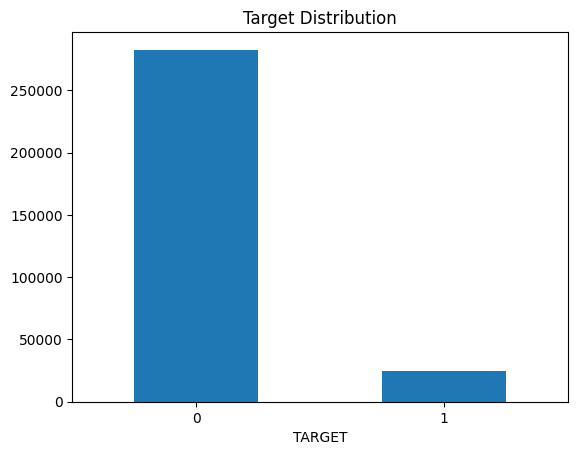

In [ ]:
# =========================
# IMBALANCE CHECK
# =========================
import matplotlib.pyplot as plt

print("=== TARGET DISTRIBUTION CHECK ===")

target_counts = y.value_counts()
target_ratio = y.value_counts(normalize=True)

print("\nCounts:")
print(target_counts)
print("\nRatio:")
print(target_ratio)

imbalance_ratio = target_counts[0] / target_counts[1]
print(f"\nImbalance Ratio (0:1) = {imbalance_ratio:.2f}")

target_counts.plot(kind='bar')
plt.title("Target Distribution")
plt.xticks(rotation=0)
plt.show()

In [ ]:
X = df_final.drop(columns=['TARGET'])
y = df_final['TARGET']

### Feature Selection

Running feature selection...
Total fitur awal   : 236
Fitur terpilih     : 167


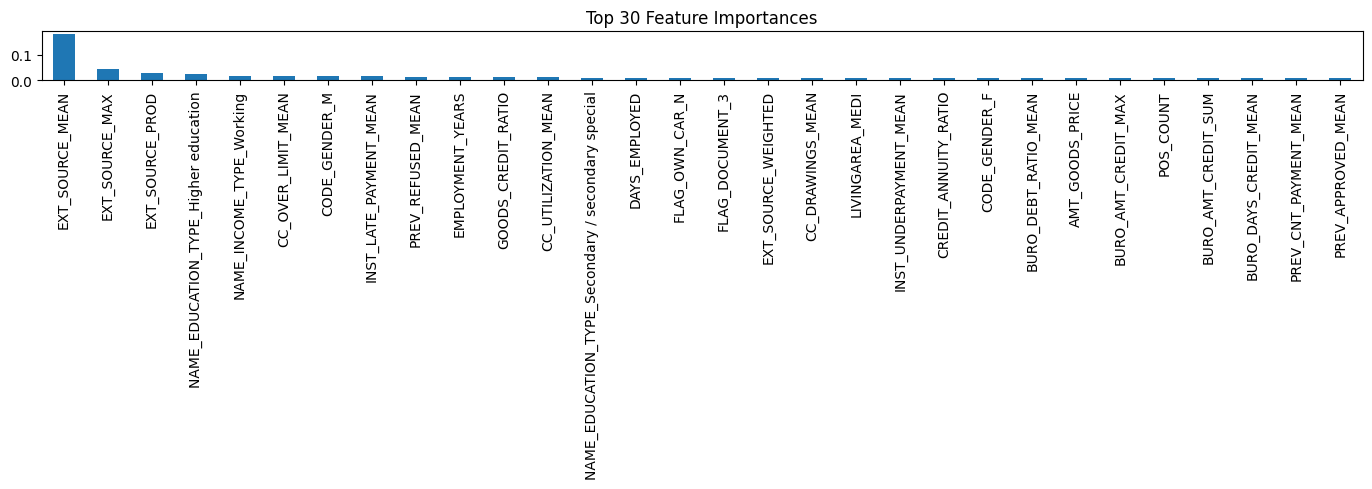


Shape setelah feature selection:
X_sel      : (307511, 167)
X_test_sel : (48744, 167)


In [ ]:
# =========================
# FEATURE SELECTION via Baseline XGB Feature Importance
# =========================
from xgboost import XGBClassifier
import numpy as np
import pandas as pd

print("Running feature selection...")

fs_model = XGBClassifier(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=4,
    scale_pos_weight=imbalance_ratio,
    tree_method='hist',
    eval_metric='auc',
    random_state=42,
    n_jobs=-1
)

fs_model.fit(X, y, verbose=False)

importances = pd.Series(fs_model.feature_importances_, index=X.columns)
importances = importances.sort_values(ascending=False)

# Ambil top N fitur yang punya importance > threshold
importance_threshold = 0.001  # bisa di-tune
selected_features = importances[importances > importance_threshold].index.tolist()

print(f"Total fitur awal   : {X.shape[1]}")
print(f"Fitur terpilih     : {len(selected_features)}")

# Plot top 30
importances.head(30).plot(kind='bar', figsize=(14, 5))
plt.title("Top 30 Feature Importances")
plt.tight_layout()
plt.show()

# Apply selection
X_sel = X[selected_features]
X_test_sel = X_test[selected_features]

print("\nShape setelah feature selection:")
print("X_sel      :", X_sel.shape)
print("X_test_sel :", X_test_sel.shape)

### Define Model

In [ ]:


# =========================
# TAHAP 7 — DEFINE MODEL (ANTI-OVERFIT)
# =========================
from xgboost import XGBClassifier

# Gap sebelumnya 0.10 → perlu regularisasi lebih kuat
xgb_params = {
    'n_estimators'         : 3000,       # tinggi, biar early stop yang kerja
    'learning_rate'        : 0.01,       # lebih kecil dari 0.02 → lebih smooth
    'max_depth'            : 4,          # turun dari 6 → kurangi kompleksitas
    'min_child_weight'     : 10,         # naik dari 5 → node butuh lebih banyak data
    'gamma'                : 1.0,        # naik dari 0.3 → pruning lebih agresif
    'subsample'            : 0.7,        # turun dari 0.85 → lebih random
    'colsample_bytree'     : 0.6,        # turun dari 0.75 → fitur lebih random
    'colsample_bylevel'    : 0.6,        # tambah regularisasi per level
    'colsample_bynode'     : 0.7,        # tambah regularisasi per node (baru)
    'reg_alpha'            : 2.0,        # naik dari 0.5 → L1 lebih kuat
    'reg_lambda'           : 10.0,       # naik dari 5.0 → L2 lebih kuat
    'scale_pos_weight'     : imbalance_ratio,
    'eval_metric'          : 'auc',
    'early_stopping_rounds': 150,        # naik dari 100 → lebih sabar
    'tree_method'          : 'hist',
    # 🔥 GPU modern
    'device'              : 'cuda',
    'random_state'         : 42,
    'n_jobs'               : -1
}

print("✅ Model params defined (anti-overfit version)")
print(f"   scale_pos_weight = {imbalance_ratio:.2f}")
print(f"   Target: kurangi gap dari 0.10 ke < 0.05")

✅ Model params defined (anti-overfit version)
   scale_pos_weight = 11.39
   Target: kurangi gap dari 0.10 ke < 0.05


### K-Fold + OOF + Overfit Check

In [ ]:
# =========================
# TAHAP 8 — K-FOLD + OOF + OVERFITTING CHECK
# (Semua dalam 1 loop — ini yang benar)
# =========================
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from xgboost import XGBClassifier
import numpy as np
import matplotlib.pyplot as plt

folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

oof_pred             = np.zeros(len(X_sel))
test_preds           = np.zeros((len(X_test_sel), 5))
fold_val_scores      = []   # val AUC per fold
fold_train_scores    = []   # train AUC per fold
fold_best_iterations = []

for fold, (train_idx, val_idx) in enumerate(folds.split(X_sel, y)):
    print(f"\n{'='*45}")
    print(f"  FOLD {fold+1}/5")
    print(f"{'='*45}")

    X_tr,      X_val_fold = X_sel.iloc[train_idx], X_sel.iloc[val_idx]
    y_tr,      y_val_fold = y.iloc[train_idx],     y.iloc[val_idx]

    model = XGBClassifier(**xgb_params)
    model.fit(
        X_tr, y_tr,
        eval_set=[(X_val_fold, y_val_fold)],
        verbose=300
    )

    best_iter = model.best_iteration
    fold_best_iterations.append(best_iter)

    # --- OOF (val) prediction ---
    val_pred          = model.predict_proba(X_val_fold)[:, 1]
    oof_pred[val_idx] = val_pred
    val_auc           = roc_auc_score(y_val_fold, val_pred)
    fold_val_scores.append(val_auc)

    # --- Train prediction (overfitting check) ---
    train_pred = model.predict_proba(X_tr)[:, 1]
    train_auc  = roc_auc_score(y_tr, train_pred)
    fold_train_scores.append(train_auc)

    # --- Test prediction ---
    test_preds[:, fold] = model.predict_proba(X_test_sel)[:, 1]

    gap    = train_auc - val_auc
    status = '✅ OK' if gap < 0.05 else ('⚠️ MODERATE' if gap < 0.08 else '❌ OVERFIT')
    print(f"\n  Best iteration : {best_iter}")
    print(f"  Train AUC      : {train_auc:.5f}")
    print(f"  Val AUC        : {val_auc:.5f}")
    print(f"  Gap            : {gap:.5f}  {status}")

# Final test prediction = rata-rata semua fold
test_pred_final = test_preds.mean(axis=1)


  FOLD 1/5
[0]	validation_0-auc:0.71473
[300]	validation_0-auc:0.75646
[600]	validation_0-auc:0.76935
[900]	validation_0-auc:0.77469
[1200]	validation_0-auc:0.77746
[1500]	validation_0-auc:0.77925
[1800]	validation_0-auc:0.78054
[2100]	validation_0-auc:0.78148
[2400]	validation_0-auc:0.78237
[2700]	validation_0-auc:0.78306
[2999]	validation_0-auc:0.78355

  Best iteration : 2996
  Train AUC      : 0.82560
  Val AUC        : 0.78356
  Gap            : 0.04204  ✅ OK

  FOLD 2/5
[0]	validation_0-auc:0.71766
[300]	validation_0-auc:0.76218
[600]	validation_0-auc:0.77591
[900]	validation_0-auc:0.78151
[1200]	validation_0-auc:0.78447
[1500]	validation_0-auc:0.78659
[1800]	validation_0-auc:0.78811
[2100]	validation_0-auc:0.78912
[2400]	validation_0-auc:0.78991
[2700]	validation_0-auc:0.79050
[2999]	validation_0-auc:0.79094

  Best iteration : 2999
  Train AUC      : 0.82435
  Val AUC        : 0.79094
  Gap            : 0.03341  ✅ OK

  FOLD 3/5
[0]	validation_0-auc:0.71391
[300]	validation_0-

### OOF Evaluation

In [ ]:
# =========================
# SUMMARY TABLE
# =========================
oof_auc    = roc_auc_score(y, oof_pred)
mean_train = np.mean(fold_train_scores)
mean_val   = np.mean(fold_val_scores)
mean_gap   = mean_train - mean_val

print(f"\n{'='*58}")
print(f"  SUMMARY K-FOLD")
print(f"{'='*58}")
print(f"{'Fold':<8} {'Train AUC':<14} {'Val AUC':<14} {'Gap':<10} Status")
print("-" * 58)

for i, (tr, vl) in enumerate(zip(fold_train_scores, fold_val_scores)):
    gap    = tr - vl
    status = '✅ OK' if gap < 0.05 else ('⚠️ MODERATE' if gap < 0.08 else '❌ OVERFIT')
    print(f"Fold {i+1:<3} {tr:<14.5f} {vl:<14.5f} {gap:<10.5f} {status}")

print("-" * 58)
print(f"{'Mean':<8} {mean_train:<14.5f} {mean_val:<14.5f} {mean_gap:<10.5f}")
print(f"\nOOF AUC           : {oof_auc:.5f}")
print(f"Mean Val AUC      : {mean_val:.5f}  (std: {np.std(fold_val_scores):.5f})")
print(f"Mean Train AUC    : {mean_train:.5f}")
print(f"Rata-rata Gap     : {mean_gap:.5f}")
print(f"Best iterations   : {fold_best_iterations}")

if mean_gap < 0.03:
    verdict = "✅ TIDAK OVERFIT — generalisasi sangat baik"
elif mean_gap < 0.05:
    verdict = "✅ GAP WAJAR — dalam batas normal untuk XGBoost"
elif mean_gap < 0.08:
    verdict = "⚠️  MODERATE OVERFIT — masih acceptable, monitor"
else:
    verdict = "❌ OVERFIT — regularisasi perlu diperkuat lagi"

print(f"\nVerdict: {verdict}")


  SUMMARY K-FOLD
Fold     Train AUC      Val AUC        Gap        Status
----------------------------------------------------------
Fold 1   0.82560        0.78356        0.04204    ✅ OK
Fold 2   0.82435        0.79094        0.03341    ✅ OK
Fold 3   0.82585        0.78255        0.04331    ✅ OK
Fold 4   0.82429        0.78894        0.03535    ✅ OK
Fold 5   0.82558        0.78255        0.04304    ✅ OK
----------------------------------------------------------
Mean     0.82514        0.78571        0.03943   

OOF AUC           : 0.78569
Mean Val AUC      : 0.78571  (std: 0.00353)
Mean Train AUC    : 0.82514
Rata-rata Gap     : 0.03943
Best iterations   : [2996, 2999, 2999, 2999, 2997]

Verdict: ✅ GAP WAJAR — dalam batas normal untuk XGBoost


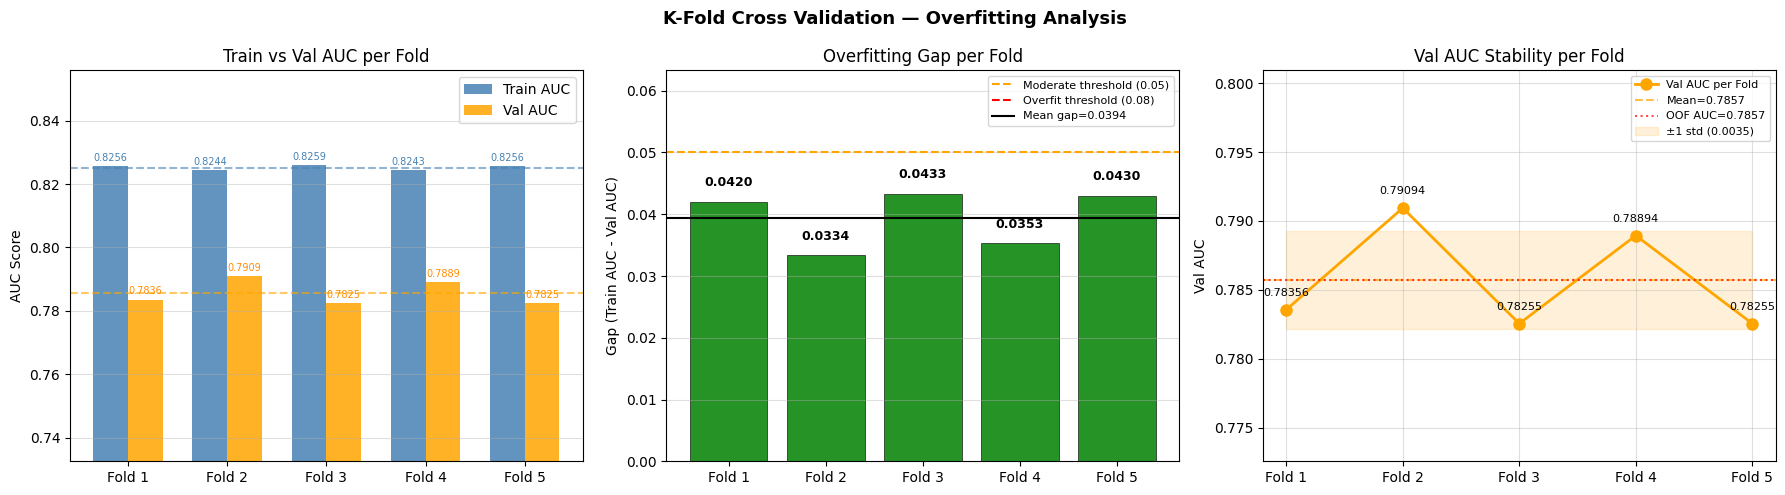


✅ Plot disimpan sebagai 'overfitting_analysis.png'


In [ ]:
# =========================
# VISUALISASI OVERFITTING
# =========================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('K-Fold Cross Validation — Overfitting Analysis', fontsize=13, fontweight='bold')

fold_labels = [f'Fold {i+1}' for i in range(5)]
x     = np.arange(5)
width = 0.35
gaps  = [tr - vl for tr, vl in zip(fold_train_scores, fold_val_scores)]

# --- Plot 1: Train vs Val AUC per fold ---
bars1 = axes[0].bar(x - width/2, fold_train_scores, width,
                    label='Train AUC', color='steelblue', alpha=0.85)
bars2 = axes[0].bar(x + width/2, fold_val_scores, width,
                    label='Val AUC', color='orange', alpha=0.85)
axes[0].set_xticks(x)
axes[0].set_xticklabels(fold_labels)
axes[0].set_ylim(min(fold_val_scores) - 0.05, max(fold_train_scores) + 0.03)
axes[0].set_ylabel('AUC Score')
axes[0].set_title('Train vs Val AUC per Fold')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.4)
axes[0].axhline(mean_val,   color='orange',    linestyle='--', alpha=0.6, label=f'Mean Val={mean_val:.4f}')
axes[0].axhline(mean_train, color='steelblue', linestyle='--', alpha=0.6, label=f'Mean Train={mean_train:.4f}')

for bar in bars1:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
                 f'{bar.get_height():.4f}', ha='center', va='bottom', fontsize=7, color='steelblue')
for bar in bars2:
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
                 f'{bar.get_height():.4f}', ha='center', va='bottom', fontsize=7, color='darkorange')

# --- Plot 2: Gap per fold ---
gap_colors = ['green' if g < 0.05 else ('orange' if g < 0.08 else 'red') for g in gaps]
bars3 = axes[1].bar(fold_labels, gaps, color=gap_colors, alpha=0.85, edgecolor='black', linewidth=0.5)
axes[1].axhline(0.05, color='orange', linestyle='--', linewidth=1.5, label='Moderate threshold (0.05)')
axes[1].axhline(0.08, color='red',    linestyle='--', linewidth=1.5, label='Overfit threshold (0.08)')
axes[1].axhline(mean_gap, color='black', linestyle='-', linewidth=1.5, label=f'Mean gap={mean_gap:.4f}')
axes[1].set_ylabel('Gap (Train AUC - Val AUC)')
axes[1].set_title('Overfitting Gap per Fold')
axes[1].legend(fontsize=8)
axes[1].grid(axis='y', alpha=0.4)
axes[1].set_ylim(0, max(gaps) + 0.02)
for bar, g in zip(bars3, gaps):
    axes[1].text(bar.get_x() + bar.get_width()/2, g + 0.002,
                 f'{g:.4f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

# --- Plot 3: Val AUC per fold (stability check) ---
axes[2].plot(fold_labels, fold_val_scores, 'o-', color='orange',
             linewidth=2, markersize=8, label='Val AUC per Fold')
axes[2].axhline(mean_val, color='orange', linestyle='--', alpha=0.7, label=f'Mean={mean_val:.4f}')
axes[2].axhline(oof_auc,  color='red',    linestyle=':',  alpha=0.7, label=f'OOF AUC={oof_auc:.4f}')
axes[2].fill_between(fold_labels,
                      [mean_val - np.std(fold_val_scores)] * 5,
                      [mean_val + np.std(fold_val_scores)] * 5,
                      alpha=0.15, color='orange', label=f'±1 std ({np.std(fold_val_scores):.4f})')
axes[2].set_ylabel('Val AUC')
axes[2].set_title('Val AUC Stability per Fold')
axes[2].legend(fontsize=8)
axes[2].grid(alpha=0.4)
axes[2].set_ylim(min(fold_val_scores) - 0.01, max(fold_val_scores) + 0.01)
for i, v in enumerate(fold_val_scores):
    axes[2].annotate(f'{v:.5f}', (fold_labels[i], v),
                     textcoords="offset points", xytext=(0, 10), ha='center', fontsize=8)

plt.tight_layout()
plt.savefig('overfitting_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n✅ Plot disimpan sebagai 'overfitting_analysis.png'")

### Threshold optimization

Best Threshold (F1): 0.6741
Best F1            : 0.3375


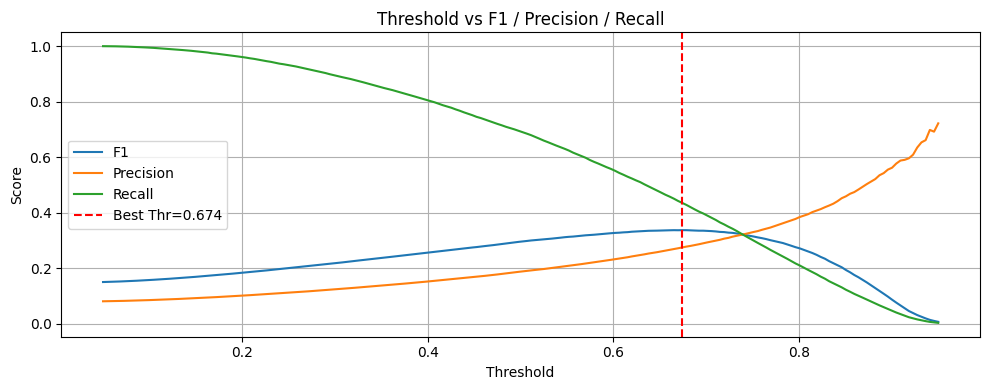

In [ ]:
# =========================
# THRESHOLD OPTIMIZATION (FIXED)
# =========================
import numpy as np
from sklearn.metrics import f1_score, precision_score, recall_score

# Sweep lebih granular dan lebar
thresholds = np.linspace(0.05, 0.95, 200)

best_thr_f1    = 0
best_f1        = 0
results        = []

for t in thresholds:
    pred = (oof_pred > t).astype(int)

    # Hindari division by zero
    if pred.sum() == 0:
        continue

    f1        = f1_score(y, pred, zero_division=0)
    precision = precision_score(y, pred, zero_division=0)
    recall    = recall_score(y, pred, zero_division=0)

    results.append({
        'threshold' : t,
        'f1'        : f1,
        'precision' : precision,
        'recall'    : recall
    })

    if f1 > best_f1:
        best_f1    = f1
        best_thr_f1 = t

print(f"Best Threshold (F1): {best_thr_f1:.4f}")
print(f"Best F1            : {best_f1:.4f}")

# Plot threshold vs metrics
results_df = pd.DataFrame(results)
plt.figure(figsize=(10, 4))
plt.plot(results_df['threshold'], results_df['f1'],        label='F1')
plt.plot(results_df['threshold'], results_df['precision'], label='Precision')
plt.plot(results_df['threshold'], results_df['recall'],    label='Recall')
plt.axvline(best_thr_f1, color='red', linestyle='--', label=f'Best Thr={best_thr_f1:.3f}')
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Threshold vs F1 / Precision / Recall")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

### Final Evaluation

In [ ]:
# =========================
# TAHAP 10 — FINAL EVALUATION + VISUALISASI LENGKAP
# =========================
final_pred = (oof_pred > best_thr_f1).astype(int)
oof_auc    = roc_auc_score(y, oof_pred)
cm         = confusion_matrix(y, final_pred)
report     = classification_report(y, final_pred, output_dict=True)

# --- Print ringkas di console ---
print("=" * 52)
print("  FINAL EVALUATION SUMMARY")
print("=" * 52)
print(f"  OOF AUC              : {oof_auc:.5f}")
print(f"  Threshold used       : {best_thr_f1:.4f}")
print(f"  Accuracy             : {report['accuracy']:.4f}")
print(f"  Precision (class 1)  : {report['1']['precision']:.4f}")
print(f"  Recall    (class 1)  : {report['1']['recall']:.4f}")
print(f"  F1-Score  (class 1)  : {report['1']['f1-score']:.4f}")
print("=" * 52)
print("\nClassification Report:")
print(classification_report(y, final_pred))
print("Confusion Matrix:")
print(cm)



  FINAL EVALUATION SUMMARY
  OOF AUC              : 0.78569
  Threshold used       : 0.6741
  Accuracy             : 0.8619
  Precision (class 1)  : 0.2755
  Recall    (class 1)  : 0.4357
  F1-Score  (class 1)  : 0.3375

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.90      0.92    282686
           1       0.28      0.44      0.34     24825

    accuracy                           0.86    307511
   macro avg       0.61      0.67      0.63    307511
weighted avg       0.89      0.86      0.88    307511

Confusion Matrix:
[[254240  28446]
 [ 14009  10816]]


### Final Visualization

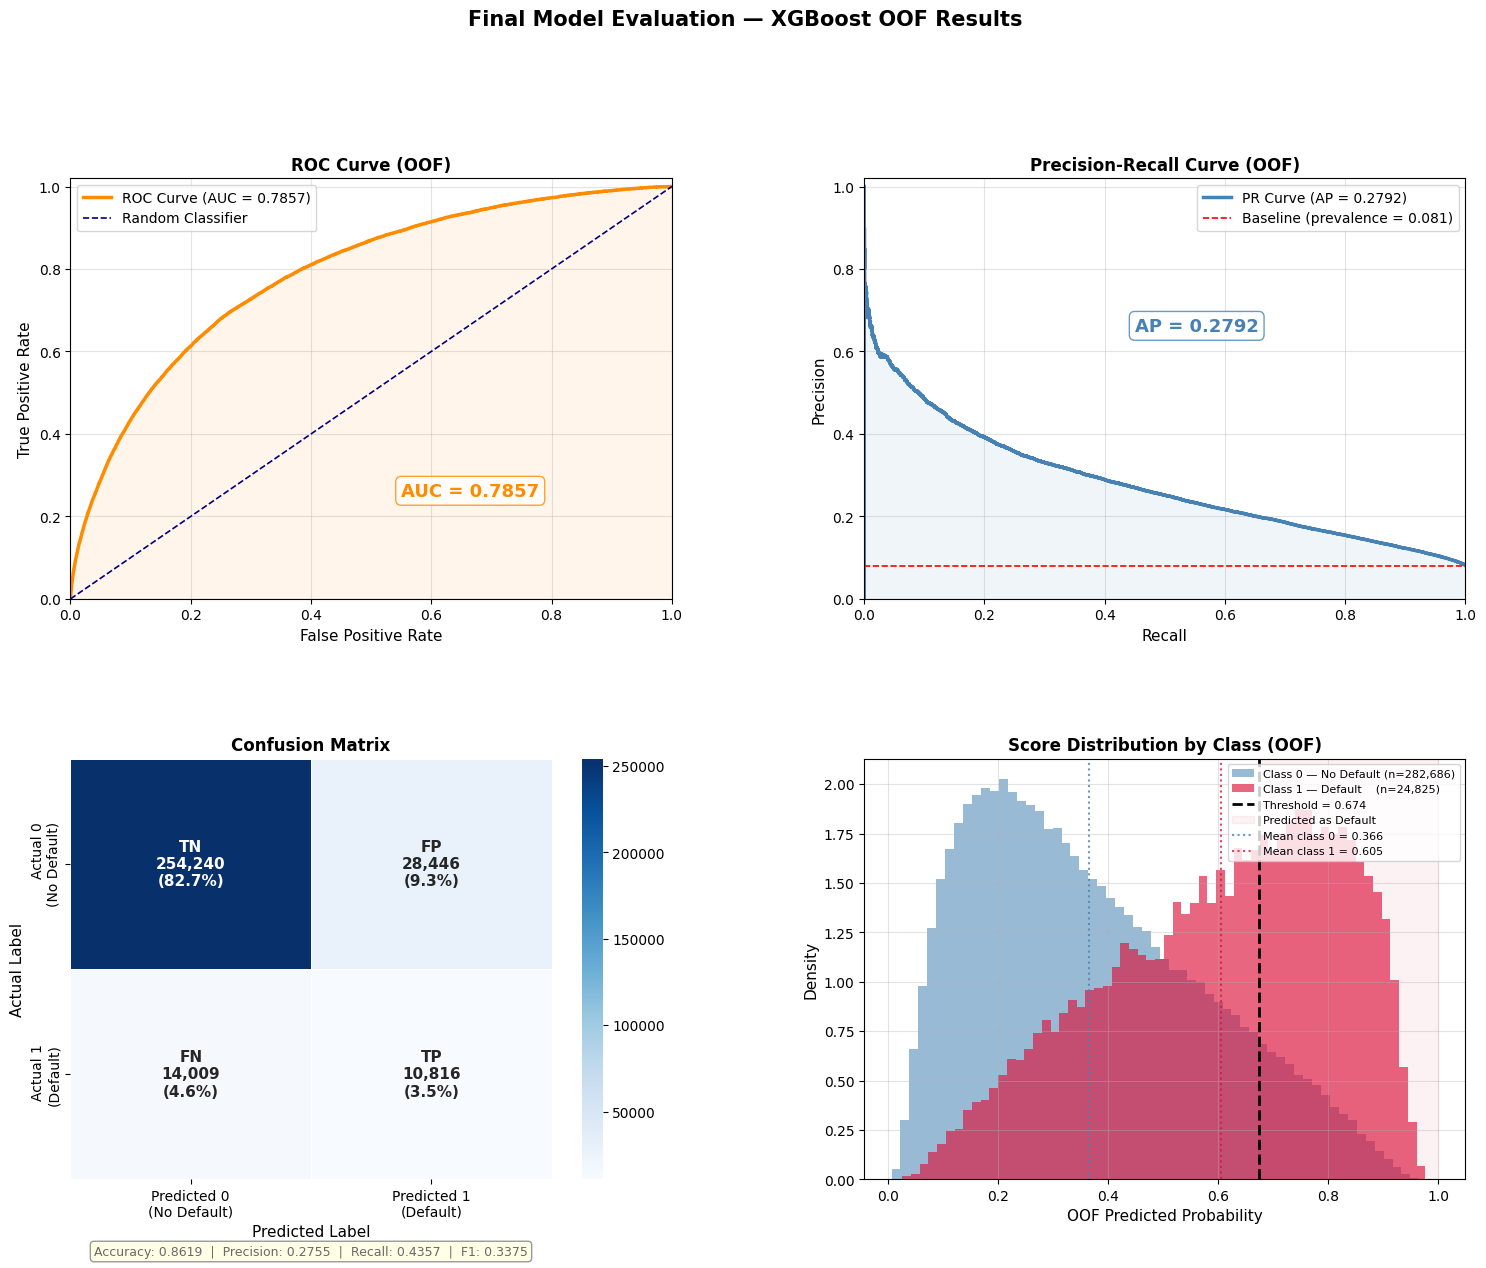


  MODEL PERFORMANCE RINGKASAN
  OOF AUC                    : 0.78569
  Average Precision (PR-AUC) : 0.27918
  Best Threshold (F1)        : 0.6741
  Accuracy                   : 0.8619
  Precision  (Default)       : 0.2755
  Recall     (Default)       : 0.4357
  F1-Score   (Default)       : 0.3375
  True Positive              : 10,816  (default terdeteksi)
  False Negative             : 14,009  (default lolos)
  False Positive             : 28,446  (salah prediksi default)
  True Negative              : 254,240  (non-default benar)

✅ Plot disimpan: 'final_evaluation.png'


In [ ]:
# ============================================================
# VISUALISASI FINAL — 4 PANEL
# ============================================================
fig = plt.figure(figsize=(18, 13))
fig.suptitle('Final Model Evaluation — XGBoost OOF Results',
             fontsize=15, fontweight='bold', y=1.01)

gs = gridspec.GridSpec(2, 2, figure=fig, hspace=0.38, wspace=0.32)

ax1 = fig.add_subplot(gs[0, 0])  # ROC Curve
ax2 = fig.add_subplot(gs[0, 1])  # Precision-Recall Curve
ax3 = fig.add_subplot(gs[1, 0])  # Confusion Matrix Heatmap
ax4 = fig.add_subplot(gs[1, 1])  # Score Distribution

# --------------------------------------------------
# PANEL 1 — ROC Curve
# --------------------------------------------------
fpr, tpr, _ = roc_curve(y, oof_pred)
roc_auc_val = auc(fpr, tpr)

ax1.plot(fpr, tpr, color='darkorange', linewidth=2.5,
         label=f'ROC Curve (AUC = {roc_auc_val:.4f})')
ax1.plot([0, 1], [0, 1], linestyle='--', color='navy',
         linewidth=1.2, label='Random Classifier')
ax1.fill_between(fpr, tpr, alpha=0.08, color='darkorange')
ax1.set_xlabel('False Positive Rate', fontsize=11)
ax1.set_ylabel('True Positive Rate',  fontsize=11)
ax1.set_title('ROC Curve (OOF)',       fontsize=12, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.35)
ax1.set_xlim([0, 1])
ax1.set_ylim([0, 1.02])

# Annotasi AUC di dalam plot
ax1.annotate(f'AUC = {roc_auc_val:.4f}',
             xy=(0.55, 0.25), fontsize=13, fontweight='bold',
             color='darkorange',
             bbox=dict(boxstyle='round,pad=0.3', facecolor='white',
                       edgecolor='darkorange', alpha=0.8))

# --------------------------------------------------
# PANEL 2 — Precision-Recall Curve
# --------------------------------------------------
precision_curve, recall_curve, _ = precision_recall_curve(y, oof_pred)
avg_precision = average_precision_score(y, oof_pred)
baseline      = y.mean()  # prevalence class 1

ax2.plot(recall_curve, precision_curve, color='steelblue', linewidth=2.5,
         label=f'PR Curve (AP = {avg_precision:.4f})')
ax2.axhline(baseline, color='red', linestyle='--', linewidth=1.2,
            label=f'Baseline (prevalence = {baseline:.3f})')
ax2.fill_between(recall_curve, precision_curve, alpha=0.08, color='steelblue')
ax2.set_xlabel('Recall',    fontsize=11)
ax2.set_ylabel('Precision', fontsize=11)
ax2.set_title('Precision-Recall Curve (OOF)', fontsize=12, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.35)
ax2.set_xlim([0, 1])
ax2.set_ylim([0, 1.02])

ax2.annotate(f'AP = {avg_precision:.4f}',
             xy=(0.45, 0.65), fontsize=13, fontweight='bold',
             color='steelblue',
             bbox=dict(boxstyle='round,pad=0.3', facecolor='white',
                       edgecolor='steelblue', alpha=0.8))

# --------------------------------------------------
# PANEL 3 — Confusion Matrix Heatmap
# --------------------------------------------------
tn, fp, fn, tp = cm.ravel()
total          = cm.sum()

cm_labels = np.array([
    [f'TN\n{tn:,}\n({tn/total*100:.1f}%)', f'FP\n{fp:,}\n({fp/total*100:.1f}%)'],
    [f'FN\n{fn:,}\n({fn/total*100:.1f}%)', f'TP\n{tp:,}\n({tp/total*100:.1f}%)']
])

sns.heatmap(cm, annot=cm_labels, fmt='', ax=ax3,
            cmap='Blues', linewidths=0.5,
            xticklabels=['Predicted 0\n(No Default)', 'Predicted 1\n(Default)'],
            yticklabels=['Actual 0\n(No Default)', 'Actual 1\n(Default)'],
            annot_kws={'size': 11, 'weight': 'bold'})
ax3.set_title('Confusion Matrix', fontsize=12, fontweight='bold')
ax3.set_ylabel('Actual Label',    fontsize=11)
ax3.set_xlabel('Predicted Label', fontsize=11)

# Metrics box di bawah heatmap
metrics_text = (f"Accuracy: {(tn+tp)/total:.4f}  |  "
                f"Precision: {tp/(tp+fp):.4f}  |  "
                f"Recall: {tp/(tp+fn):.4f}  |  "
                f"F1: {2*tp/(2*tp+fp+fn):.4f}")
ax3.text(0.5, -0.18, metrics_text, transform=ax3.transAxes,
         ha='center', fontsize=9, color='dimgray',
         bbox=dict(boxstyle='round', facecolor='lightyellow',
                   edgecolor='gray', alpha=0.8))

# --------------------------------------------------
# PANEL 4 — OOF Score Distribution
# --------------------------------------------------
y_arr    = np.array(y)
scores_0 = oof_pred[y_arr == 0]
scores_1 = oof_pred[y_arr == 1]

ax4.hist(scores_0, bins=60, alpha=0.55, color='steelblue',
         label=f'Class 0 — No Default (n={len(scores_0):,})',
         density=True, edgecolor='none')
ax4.hist(scores_1, bins=60, alpha=0.65, color='crimson',
         label=f'Class 1 — Default    (n={len(scores_1):,})',
         density=True, edgecolor='none')
ax4.axvline(best_thr_f1, color='black', linestyle='--', linewidth=2,
            label=f'Threshold = {best_thr_f1:.3f}')
ax4.set_xlabel('OOF Predicted Probability', fontsize=11)
ax4.set_ylabel('Density',                   fontsize=11)
ax4.set_title('Score Distribution by Class (OOF)', fontsize=12, fontweight='bold')
ax4.legend(fontsize=9)
ax4.grid(True, alpha=0.35)

# Shading area prediksi default
ax4.axvspan(best_thr_f1, 1.0, alpha=0.06, color='crimson',
            label='Predicted as Default')

# Annotasi separation
mean_0 = scores_0.mean()
mean_1 = scores_1.mean()
ax4.axvline(mean_0, color='steelblue', linestyle=':', linewidth=1.5,
            alpha=0.8, label=f'Mean class 0 = {mean_0:.3f}')
ax4.axvline(mean_1, color='crimson',   linestyle=':', linewidth=1.5,
            alpha=0.8, label=f'Mean class 1 = {mean_1:.3f}')
ax4.legend(fontsize=8, loc='upper right')

plt.savefig('final_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()

# --------------------------------------------------
# PRINT RINGKASAN AKHIR
# --------------------------------------------------
print("\n" + "=" * 52)
print("  MODEL PERFORMANCE RINGKASAN")
print("=" * 52)
print(f"  OOF AUC                    : {oof_auc:.5f}")
print(f"  Average Precision (PR-AUC) : {avg_precision:.5f}")
print(f"  Best Threshold (F1)        : {best_thr_f1:.4f}")
print(f"  Accuracy                   : {report['accuracy']:.4f}")
print(f"  Precision  (Default)       : {report['1']['precision']:.4f}")
print(f"  Recall     (Default)       : {report['1']['recall']:.4f}")
print(f"  F1-Score   (Default)       : {report['1']['f1-score']:.4f}")
print(f"  True Positive              : {tp:,}  (default terdeteksi)")
print(f"  False Negative             : {fn:,}  (default lolos)")
print(f"  False Positive             : {fp:,}  (salah prediksi default)")
print(f"  True Negative              : {tn:,}  (non-default benar)")
print("=" * 52)
print("\n✅ Plot disimpan: 'final_evaluation.png'")

## Modeling Logistic Regression

### Scaling LogReg

In [ ]:
# =========================
# TAHAP 12 — SCALING UNTUK LOGREG
# (XGBoost tidak butuh scaling, LogReg wajib)
# =========================

print("Scaling fitur untuk Logistic Regression...")

scaler = StandardScaler()

# Fit HANYA dari train, transform ke train dan test
X_sel_scaled      = scaler.fit_transform(X_sel)
X_test_sel_scaled = scaler.transform(X_test_sel)

# Kembalikan ke DataFrame agar nama kolom terjaga
X_sel_scaled      = pd.DataFrame(X_sel_scaled,
                                  columns=X_sel.columns,
                                  index=X_sel.index)
X_test_sel_scaled = pd.DataFrame(X_test_sel_scaled,
                                  columns=X_test_sel.columns,
                                  index=X_test_sel.index)

print(f"✅ Scaling selesai")
print(f"   X_sel_scaled      : {X_sel_scaled.shape}")
print(f"   X_test_sel_scaled : {X_test_sel_scaled.shape}")
print(f"\nContoh nilai setelah scaling (mean ≈ 0, std ≈ 1):")
print(X_sel_scaled.describe().loc[['mean','std']].round(3).iloc[:, :5])

Scaling fitur untuk Logistic Regression...
✅ Scaling selesai
   X_sel_scaled      : (307511, 167)
   X_test_sel_scaled : (48744, 167)

Contoh nilai setelah scaling (mean ≈ 0, std ≈ 1):
      EXT_SOURCE_MEAN  EXT_SOURCE_MAX  EXT_SOURCE_PROD  \
mean              0.0            -0.0             -0.0   
std               1.0             1.0              1.0   

      NAME_EDUCATION_TYPE_Higher education  NAME_INCOME_TYPE_Working  
mean                                  -0.0                      -0.0  
std                                    1.0                       1.0  


### Define Model

In [ ]:
# =========================
# TAHAP 13 — DEFINE MODEL LOGISTIC REGRESSION
# =========================
from sklearn.linear_model import LogisticRegression

logreg_params = {
    'C'            : 0.05,          # regularisasi kuat (inverse of lambda)
    'penalty'      : 'l2',          # L2 regularization
    'solver'       : 'saga',        # saga = cepat untuk dataset besar
    'max_iter'     : 1000,
    'class_weight' : 'balanced',    # handle imbalance otomatis
    'random_state' : 42,
    'n_jobs'       : -1
}

print("✅ LogReg params defined:")
for k, v in logreg_params.items():
    print(f"   {k:<20} : {v}")

print(f"\nCatatan:")
print(f"  - class_weight='balanced' menggantikan scale_pos_weight di XGB")
print(f"  - C=0.05 artinya regularisasi cukup kuat (cegah overfit)")
print(f"  - solver='saga' optimal untuk dataset besar (307K rows)")

✅ LogReg params defined:
   C                    : 0.05
   penalty              : l2
   solver               : saga
   max_iter             : 1000
   class_weight         : balanced
   random_state         : 42
   n_jobs               : -1

Catatan:
  - class_weight='balanced' menggantikan scale_pos_weight di XGB
  - C=0.05 artinya regularisasi cukup kuat (cegah overfit)
  - solver='saga' optimal untuk dataset besar (307K rows)


### K-Fold + OOF + Overfit Check LogReg

In [ ]:
# =========================
# TAHAP 14 — K-FOLD + OOF + OVERFIT CHECK (LOGREG)
# Struktur loop sama dengan XGB, isi berbeda
# =========================
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Pakai X_sel_scaled (bukan X_sel!) untuk LogReg
oof_pred_lr   = np.zeros(len(X_sel_scaled))
test_preds_lr = np.zeros((len(X_test_sel_scaled), 5))

fold_val_scores_lr   = []
fold_train_scores_lr = []

for fold, (train_idx, val_idx) in enumerate(folds.split(X_sel_scaled, y)):
    print(f"\n{'='*45}")
    print(f"  LOGREG — FOLD {fold+1}/5")
    print(f"{'='*45}")

    X_tr_lr,   X_val_lr = X_sel_scaled.iloc[train_idx], X_sel_scaled.iloc[val_idx]
    y_tr_lr,   y_val_lr = y.iloc[train_idx],            y.iloc[val_idx]

    # Instantiate fresh model tiap fold
    model_lr = LogisticRegression(**logreg_params)
    model_lr.fit(X_tr_lr, y_tr_lr)

    # OOF (val) prediction
    val_pred_lr          = model_lr.predict_proba(X_val_lr)[:, 1]
    oof_pred_lr[val_idx] = val_pred_lr
    val_auc_lr           = roc_auc_score(y_val_lr, val_pred_lr)
    fold_val_scores_lr.append(val_auc_lr)

    # Train prediction (overfitting check)
    train_pred_lr = model_lr.predict_proba(X_tr_lr)[:, 1]
    train_auc_lr  = roc_auc_score(y_tr_lr, train_pred_lr)
    fold_train_scores_lr.append(train_auc_lr)

    # Test prediction per fold
    test_preds_lr[:, fold] = model_lr.predict_proba(X_test_sel_scaled)[:, 1]

    gap    = train_auc_lr - val_auc_lr
    status = '✅ OK' if gap < 0.05 else ('⚠️ MODERATE' if gap < 0.08 else '❌ OVERFIT')
    print(f"  Train AUC : {train_auc_lr:.5f}")
    print(f"  Val AUC   : {val_auc_lr:.5f}")
    print(f"  Gap       : {gap:.5f}  {status}")

# Final test prediction LogReg
test_pred_final_lr = test_preds_lr.mean(axis=1)






  LOGREG — FOLD 1/5
  Train AUC : 0.77006
  Val AUC   : 0.76379
  Gap       : 0.00628  ✅ OK

  LOGREG — FOLD 2/5
  Train AUC : 0.76830
  Val AUC   : 0.77134
  Gap       : -0.00305  ✅ OK

  LOGREG — FOLD 3/5
  Train AUC : 0.76939
  Val AUC   : 0.76712
  Gap       : 0.00227  ✅ OK

  LOGREG — FOLD 4/5
  Train AUC : 0.76850
  Val AUC   : 0.77034
  Gap       : -0.00183  ✅ OK

  LOGREG — FOLD 5/5
  Train AUC : 0.77034
  Val AUC   : 0.76317
  Gap       : 0.00718  ✅ OK


### Evaluation

In [ ]:
# --- Summary ---
oof_auc_lr    = roc_auc_score(y, oof_pred_lr)
mean_train_lr = np.mean(fold_train_scores_lr)
mean_val_lr   = np.mean(fold_val_scores_lr)
mean_gap_lr   = mean_train_lr - mean_val_lr

print(f"\n{'='*58}")
print(f"  SUMMARY K-FOLD — LOGISTIC REGRESSION")
print(f"{'='*58}")
print(f"{'Fold':<8} {'Train AUC':<14} {'Val AUC':<14} {'Gap':<10} Status")
print("-" * 58)

for i, (tr, vl) in enumerate(zip(fold_train_scores_lr, fold_val_scores_lr)):
    gap    = tr - vl
    status = '✅ OK' if gap < 0.05 else ('⚠️ MODERATE' if gap < 0.08 else '❌ OVERFIT')
    print(f"Fold {i+1:<3} {tr:<14.5f} {vl:<14.5f} {gap:<10.5f} {status}")

print("-" * 58)
print(f"{'Mean':<8} {mean_train_lr:<14.5f} {mean_val_lr:<14.5f} {mean_gap_lr:<10.5f}")
print(f"\nOOF AUC           : {oof_auc_lr:.5f}")
print(f"Mean Val AUC      : {mean_val_lr:.5f}  (std: {np.std(fold_val_scores_lr):.5f})")
print(f"Mean Train AUC    : {mean_train_lr:.5f}")
print(f"Rata-rata Gap     : {mean_gap_lr:.5f}")

if mean_gap_lr < 0.01:
    verdict_lr = "✅ TIDAK OVERFIT — generalisasi sangat baik"
elif mean_gap_lr < 0.03:
    verdict_lr = "✅ GAP WAJAR — dalam batas normal"
elif mean_gap_lr < 0.05:
    verdict_lr = "⚠️  MODERATE — monitor"
else:
    verdict_lr = "❌ OVERFIT — tuning diperlukan"

print(f"\nVerdict: {verdict_lr}")


  SUMMARY K-FOLD — LOGISTIC REGRESSION
Fold     Train AUC      Val AUC        Gap        Status
----------------------------------------------------------
Fold 1   0.77006        0.76379        0.00628    ✅ OK
Fold 2   0.76830        0.77134        -0.00305   ✅ OK
Fold 3   0.76939        0.76712        0.00227    ✅ OK
Fold 4   0.76850        0.77034        -0.00183   ✅ OK
Fold 5   0.77034        0.76317        0.00718    ✅ OK
----------------------------------------------------------
Mean     0.76932        0.76715        0.00217   

OOF AUC           : 0.76713
Mean Val AUC      : 0.76715  (std: 0.00331)
Mean Train AUC    : 0.76932
Rata-rata Gap     : 0.00217

Verdict: ✅ TIDAK OVERFIT — generalisasi sangat baik


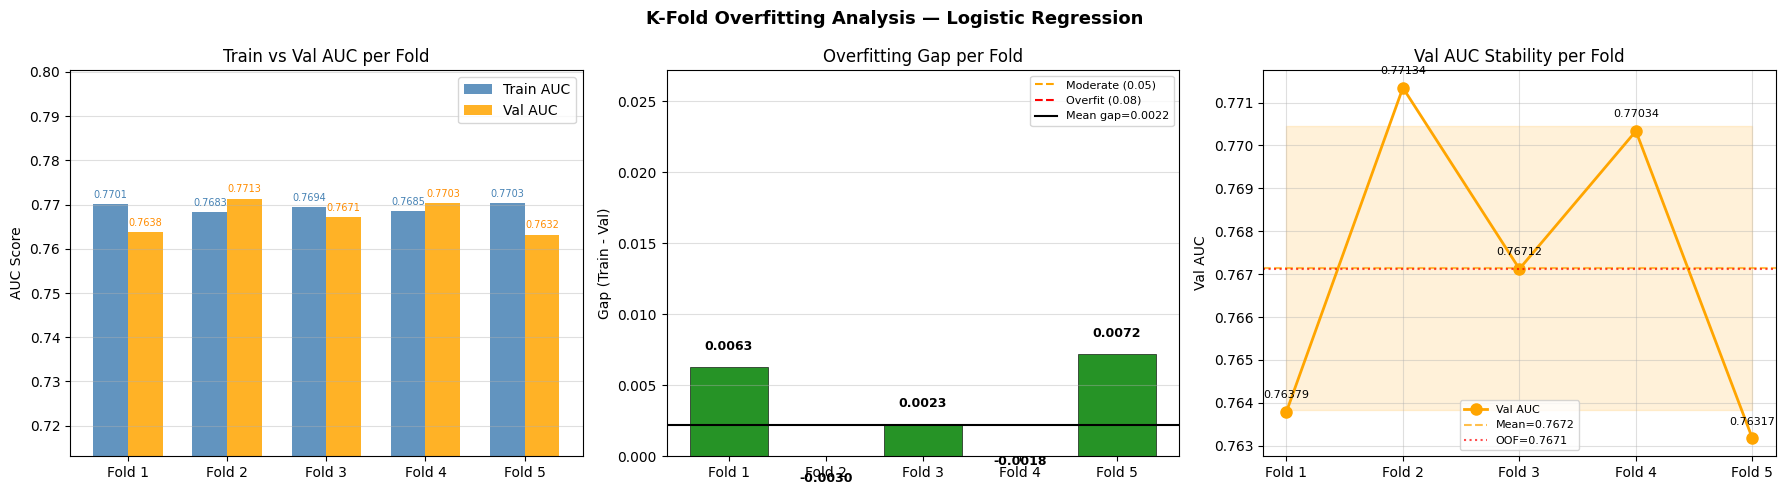

In [ ]:
# --- Visualisasi Overfit LogReg ---
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle('K-Fold Overfitting Analysis — Logistic Regression',
             fontsize=13, fontweight='bold')

fold_labels  = [f'Fold {i+1}' for i in range(5)]
x            = np.arange(5)
width        = 0.35
gaps_lr      = [tr - vl for tr, vl
                in zip(fold_train_scores_lr, fold_val_scores_lr)]

# Plot 1: Train vs Val
bars1 = axes[0].bar(x - width/2, fold_train_scores_lr, width,
                    label='Train AUC', color='steelblue', alpha=0.85)
bars2 = axes[0].bar(x + width/2, fold_val_scores_lr,   width,
                    label='Val AUC',   color='orange',   alpha=0.85)
axes[0].set_xticks(x)
axes[0].set_xticklabels(fold_labels)
axes[0].set_ylim(min(fold_val_scores_lr) - 0.05,
                 max(fold_train_scores_lr) + 0.03)
axes[0].set_ylabel('AUC Score')
axes[0].set_title('Train vs Val AUC per Fold')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.4)
for bar in bars1:
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.001,
                 f'{bar.get_height():.4f}',
                 ha='center', va='bottom', fontsize=7, color='steelblue')
for bar in bars2:
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 bar.get_height() + 0.001,
                 f'{bar.get_height():.4f}',
                 ha='center', va='bottom', fontsize=7, color='darkorange')

# Plot 2: Gap
gap_colors = ['green' if g < 0.05 else ('orange' if g < 0.08 else 'red')
              for g in gaps_lr]
bars3 = axes[1].bar(fold_labels, gaps_lr, color=gap_colors,
                    alpha=0.85, edgecolor='black', linewidth=0.5)
axes[1].axhline(0.05, color='orange', linestyle='--', linewidth=1.5,
                label='Moderate (0.05)')
axes[1].axhline(0.08, color='red',    linestyle='--', linewidth=1.5,
                label='Overfit (0.08)')
axes[1].axhline(mean_gap_lr, color='black', linestyle='-', linewidth=1.5,
                label=f'Mean gap={mean_gap_lr:.4f}')
axes[1].set_ylabel('Gap (Train - Val)')
axes[1].set_title('Overfitting Gap per Fold')
axes[1].legend(fontsize=8)
axes[1].grid(axis='y', alpha=0.4)
axes[1].set_ylim(0, max(gaps_lr) + 0.02)
for bar, g in zip(bars3, gaps_lr):
    axes[1].text(bar.get_x() + bar.get_width()/2,
                 g + 0.001, f'{g:.4f}',
                 ha='center', va='bottom', fontsize=9, fontweight='bold')

# Plot 3: Val AUC stability
axes[2].plot(fold_labels, fold_val_scores_lr, 'o-',
             color='orange', linewidth=2, markersize=8, label='Val AUC')
axes[2].axhline(mean_val_lr, color='orange', linestyle='--', alpha=0.7,
                label=f'Mean={mean_val_lr:.4f}')
axes[2].axhline(oof_auc_lr,  color='red',    linestyle=':',  alpha=0.7,
                label=f'OOF={oof_auc_lr:.4f}')
axes[2].fill_between(fold_labels,
                      [mean_val_lr - np.std(fold_val_scores_lr)] * 5,
                      [mean_val_lr + np.std(fold_val_scores_lr)] * 5,
                      alpha=0.15, color='orange')
axes[2].set_ylabel('Val AUC')
axes[2].set_title('Val AUC Stability per Fold')
axes[2].legend(fontsize=8)
axes[2].grid(alpha=0.4)
for i, v in enumerate(fold_val_scores_lr):
    axes[2].annotate(f'{v:.5f}', (fold_labels[i], v),
                     textcoords="offset points",
                     xytext=(0, 10), ha='center', fontsize=8)

plt.tight_layout()
plt.savefig('logreg_overfitting_analysis.png', dpi=150, bbox_inches='tight')
plt.show()

### Threshold Optimization

Best Threshold (F1) : 0.6741
Best F1 (minority)  : 0.3150


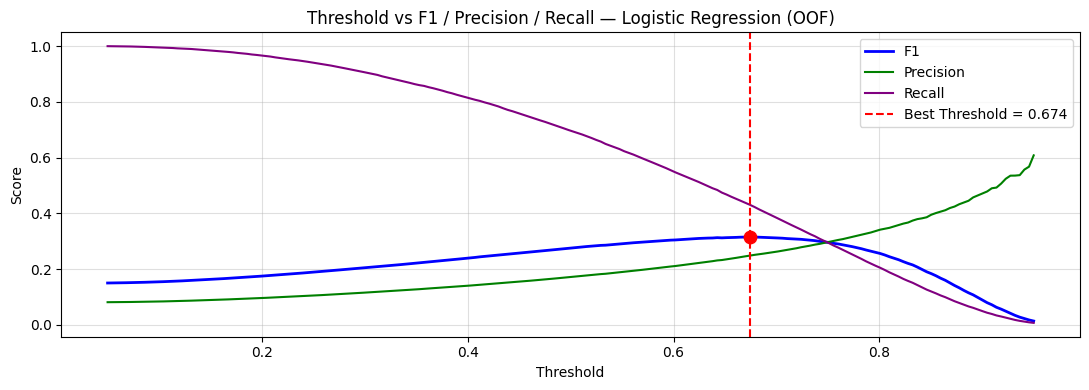

In [ ]:
# =========================
# TAHAP 15 — THRESHOLD OPTIMIZATION LOGREG
# =========================
from sklearn.metrics import f1_score, precision_score, recall_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

thresholds     = np.linspace(0.05, 0.95, 200)
best_thr_lr    = 0
best_f1_lr     = 0
results_lr     = []

for t in thresholds:
    pred = (oof_pred_lr > t).astype(int)
    if pred.sum() == 0:
        continue

    f1        = f1_score(y,        pred, zero_division=0)
    precision = precision_score(y, pred, zero_division=0)
    recall    = recall_score(y,    pred, zero_division=0)

    results_lr.append({'threshold': t, 'f1': f1,
                       'precision': precision, 'recall': recall})

    if f1 > best_f1_lr:
        best_f1_lr  = f1
        best_thr_lr = t

print(f"Best Threshold (F1) : {best_thr_lr:.4f}")
print(f"Best F1 (minority)  : {best_f1_lr:.4f}")

results_lr_df = pd.DataFrame(results_lr)

plt.figure(figsize=(11, 4))
plt.plot(results_lr_df['threshold'], results_lr_df['f1'],
         label='F1', color='blue', linewidth=2)
plt.plot(results_lr_df['threshold'], results_lr_df['precision'],
         label='Precision', color='green', linewidth=1.5)
plt.plot(results_lr_df['threshold'], results_lr_df['recall'],
         label='Recall', color='purple', linewidth=1.5)
plt.axvline(best_thr_lr, color='red', linestyle='--', linewidth=1.5,
            label=f'Best Threshold = {best_thr_lr:.3f}')
plt.scatter([best_thr_lr], [best_f1_lr], color='red', zorder=5, s=80)
plt.xlabel("Threshold")
plt.ylabel("Score")
plt.title("Threshold vs F1 / Precision / Recall — Logistic Regression (OOF)")
plt.legend()
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

### Final Evaluation

  FINAL EVALUATION — LOGISTIC REGRESSION
  OOF AUC              : 0.76713
  Threshold used       : 0.6741
  Accuracy             : 0.8488
  Precision (class 1)  : 0.2483
  Recall    (class 1)  : 0.4307
  F1-Score  (class 1)  : 0.3150

Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.89      0.92    282686
           1       0.25      0.43      0.32     24825

    accuracy                           0.85    307511
   macro avg       0.60      0.66      0.62    307511
weighted avg       0.89      0.85      0.87    307511

Confusion Matrix:
[[250324  32362]
 [ 14134  10691]]


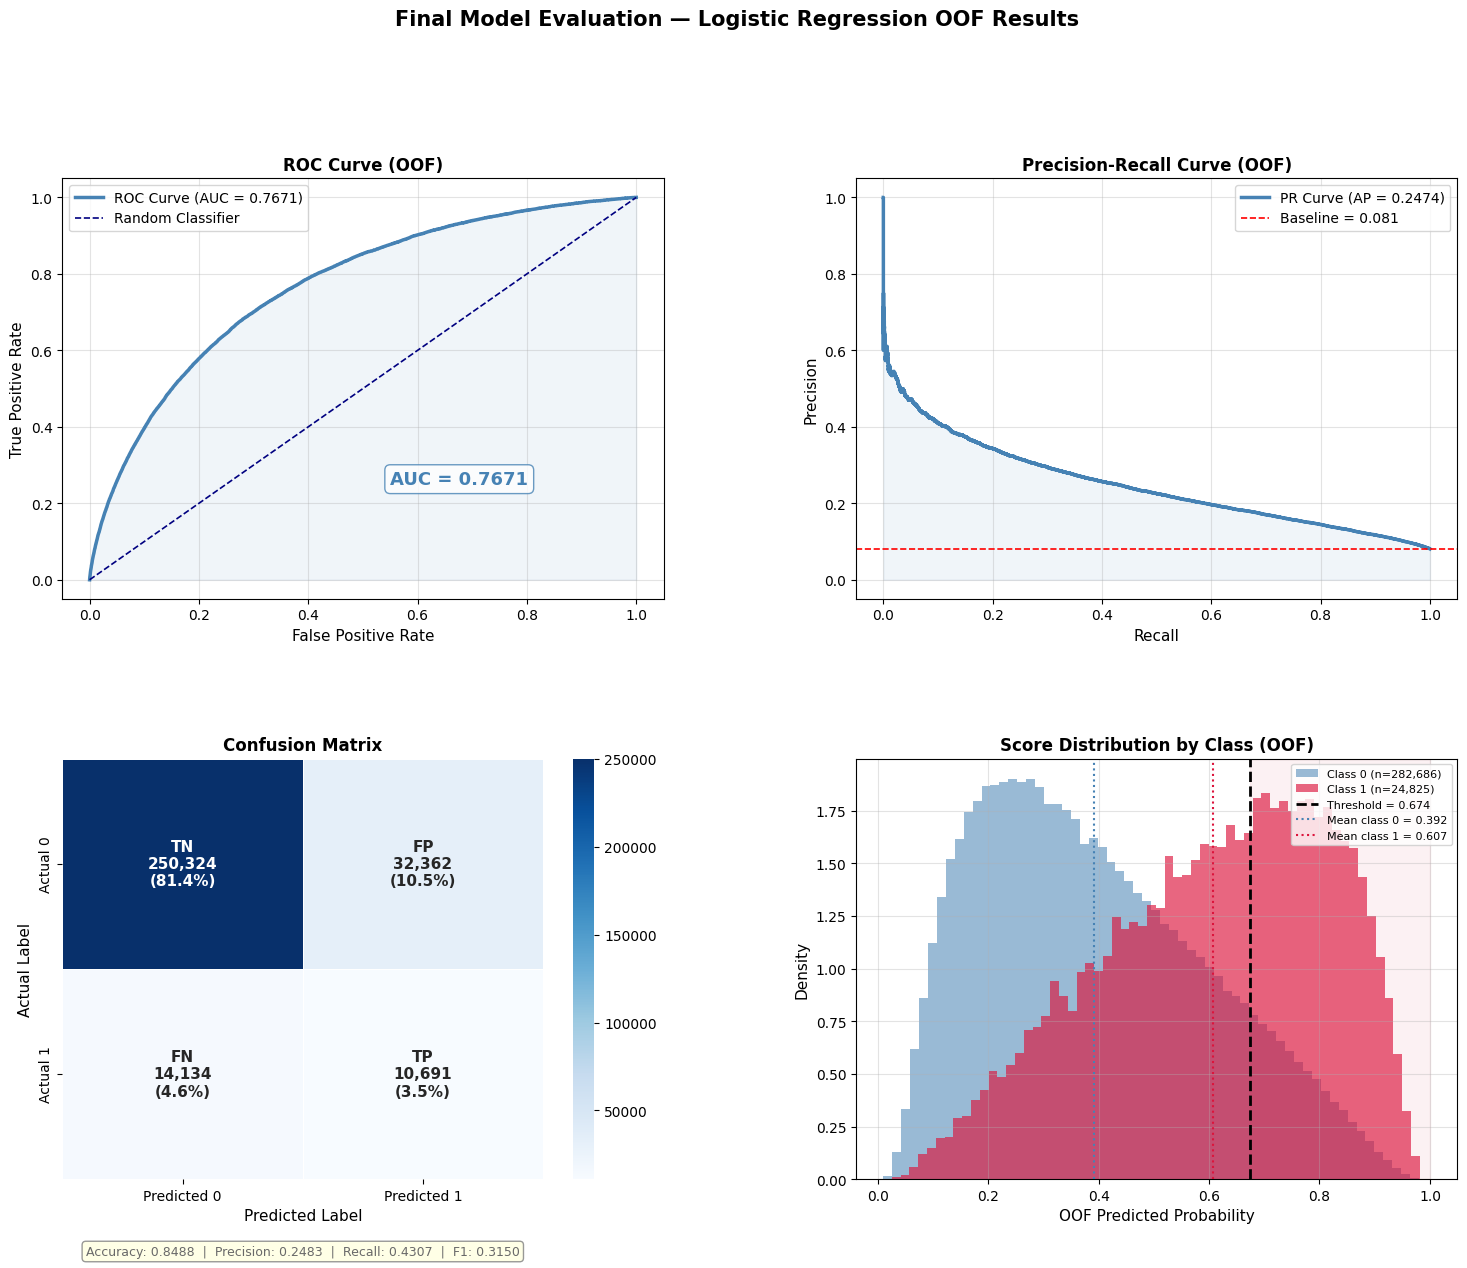


✅ Plot disimpan: 'logreg_final_evaluation.png'


In [ ]:
# =========================
# TAHAP 16 — FINAL EVALUATION LOGREG
# =========================
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve, auc,
    precision_recall_curve, average_precision_score
)
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
import numpy as np

final_pred_lr = (oof_pred_lr > best_thr_lr).astype(int)
oof_auc_lr    = roc_auc_score(y, oof_pred_lr)
cm_lr         = confusion_matrix(y, final_pred_lr)
report_lr     = classification_report(y, final_pred_lr, output_dict=True)

print("=" * 52)
print("  FINAL EVALUATION — LOGISTIC REGRESSION")
print("=" * 52)
print(f"  OOF AUC              : {oof_auc_lr:.5f}")
print(f"  Threshold used       : {best_thr_lr:.4f}")
print(f"  Accuracy             : {report_lr['accuracy']:.4f}")
print(f"  Precision (class 1)  : {report_lr['1']['precision']:.4f}")
print(f"  Recall    (class 1)  : {report_lr['1']['recall']:.4f}")
print(f"  F1-Score  (class 1)  : {report_lr['1']['f1-score']:.4f}")
print("=" * 52)
print("\nClassification Report:")
print(classification_report(y, final_pred_lr))
print("Confusion Matrix:")
print(cm_lr)

# 4-Panel Visualization
fig = plt.figure(figsize=(18, 13))
fig.suptitle('Final Model Evaluation — Logistic Regression OOF Results',
             fontsize=15, fontweight='bold', y=1.01)

gs   = gridspec.GridSpec(2, 2, figure=fig, hspace=0.38, wspace=0.32)
ax1  = fig.add_subplot(gs[0, 0])
ax2  = fig.add_subplot(gs[0, 1])
ax3  = fig.add_subplot(gs[1, 0])
ax4  = fig.add_subplot(gs[1, 1])

# Panel 1 — ROC
fpr_lr, tpr_lr, _ = roc_curve(y, oof_pred_lr)
ax1.plot(fpr_lr, tpr_lr, color='steelblue', linewidth=2.5,
         label=f'ROC Curve (AUC = {oof_auc_lr:.4f})')
ax1.plot([0,1],[0,1], linestyle='--', color='navy', linewidth=1.2,
         label='Random Classifier')
ax1.fill_between(fpr_lr, tpr_lr, alpha=0.08, color='steelblue')
ax1.set_xlabel('False Positive Rate', fontsize=11)
ax1.set_ylabel('True Positive Rate',  fontsize=11)
ax1.set_title('ROC Curve (OOF)',       fontsize=12, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.35)
ax1.annotate(f'AUC = {oof_auc_lr:.4f}',
             xy=(0.55, 0.25), fontsize=13, fontweight='bold', color='steelblue',
             bbox=dict(boxstyle='round,pad=0.3', facecolor='white',
                       edgecolor='steelblue', alpha=0.8))

# Panel 2 — PR Curve
prec_lr, rec_lr, _ = precision_recall_curve(y, oof_pred_lr)
ap_lr               = average_precision_score(y, oof_pred_lr)
baseline            = y.mean()
ax2.plot(rec_lr, prec_lr, color='steelblue', linewidth=2.5,
         label=f'PR Curve (AP = {ap_lr:.4f})')
ax2.axhline(baseline, color='red', linestyle='--', linewidth=1.2,
            label=f'Baseline = {baseline:.3f}')
ax2.fill_between(rec_lr, prec_lr, alpha=0.08, color='steelblue')
ax2.set_xlabel('Recall', fontsize=11)
ax2.set_ylabel('Precision', fontsize=11)
ax2.set_title('Precision-Recall Curve (OOF)', fontsize=12, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.35)

# Panel 3 — Confusion Matrix
tn_lr, fp_lr, fn_lr, tp_lr = cm_lr.ravel()
total_lr = cm_lr.sum()
cm_labels_lr = np.array([
    [f'TN\n{tn_lr:,}\n({tn_lr/total_lr*100:.1f}%)',
     f'FP\n{fp_lr:,}\n({fp_lr/total_lr*100:.1f}%)'],
    [f'FN\n{fn_lr:,}\n({fn_lr/total_lr*100:.1f}%)',
     f'TP\n{tp_lr:,}\n({tp_lr/total_lr*100:.1f}%)']
])
sns.heatmap(cm_lr, annot=cm_labels_lr, fmt='', ax=ax3,
            cmap='Blues', linewidths=0.5,
            xticklabels=['Predicted 0', 'Predicted 1'],
            yticklabels=['Actual 0', 'Actual 1'],
            annot_kws={'size': 11, 'weight': 'bold'})
ax3.set_title('Confusion Matrix', fontsize=12, fontweight='bold')
ax3.set_ylabel('Actual Label',    fontsize=11)
ax3.set_xlabel('Predicted Label', fontsize=11)
metrics_text_lr = (f"Accuracy: {(tn_lr+tp_lr)/total_lr:.4f}  |  "
                   f"Precision: {tp_lr/(tp_lr+fp_lr):.4f}  |  "
                   f"Recall: {tp_lr/(tp_lr+fn_lr):.4f}  |  "
                   f"F1: {2*tp_lr/(2*tp_lr+fp_lr+fn_lr):.4f}")
ax3.text(0.5, -0.18, metrics_text_lr, transform=ax3.transAxes,
         ha='center', fontsize=9, color='dimgray',
         bbox=dict(boxstyle='round', facecolor='lightyellow',
                   edgecolor='gray', alpha=0.8))

# Panel 4 — Score Distribution
y_arr     = np.array(y)
scores_0  = oof_pred_lr[y_arr == 0]
scores_1  = oof_pred_lr[y_arr == 1]
ax4.hist(scores_0, bins=60, alpha=0.55, color='steelblue',
         label=f'Class 0 (n={len(scores_0):,})', density=True)
ax4.hist(scores_1, bins=60, alpha=0.65, color='crimson',
         label=f'Class 1 (n={len(scores_1):,})', density=True)
ax4.axvline(best_thr_lr, color='black', linestyle='--', linewidth=2,
            label=f'Threshold = {best_thr_lr:.3f}')
ax4.axvspan(best_thr_lr, 1.0, alpha=0.06, color='crimson')
ax4.axvline(scores_0.mean(), color='steelblue', linestyle=':', linewidth=1.5,
            label=f'Mean class 0 = {scores_0.mean():.3f}')
ax4.axvline(scores_1.mean(), color='crimson',   linestyle=':', linewidth=1.5,
            label=f'Mean class 1 = {scores_1.mean():.3f}')
ax4.set_xlabel('OOF Predicted Probability', fontsize=11)
ax4.set_ylabel('Density',                   fontsize=11)
ax4.set_title('Score Distribution by Class (OOF)', fontsize=12, fontweight='bold')
ax4.legend(fontsize=8)
ax4.grid(True, alpha=0.35)

plt.savefig('logreg_final_evaluation.png', dpi=150, bbox_inches='tight')
plt.show()

print("\n✅ Plot disimpan: 'logreg_final_evaluation.png'")

## Model Comparison XGBoost vs LogReg

  MODEL COMPARISON — XGBoost vs Logistic Regression
Metric                              XGBoost         LogReg
--------------------------------------------------------------
  OOF AUC                           0.78569        0.76713  ← XGB
  Avg Precision (PR)                0.27918        0.24736  ← XGB
  Accuracy                           0.8619         0.8488  ← XGB
  Precision (Default)                0.2755         0.2483  ← XGB
  Recall (Default)                   0.4357         0.4307  ← XGB
  F1 (Default)                       0.3375         0.3150  ← XGB
  Mean Val AUC (CV)                 0.78571        0.76715  ← XGB
  Mean Train AUC (CV)               0.82514        0.76932  ← XGB
  Mean Gap (overfit)                0.03943        0.00217  ← LR 
  Val AUC Std                       0.00353        0.00331  ← LR 

  XGBoost wins : 8/10 metrics
  LogReg wins  : 2/10 metrics

  → Rekomendasi model: XGBoost


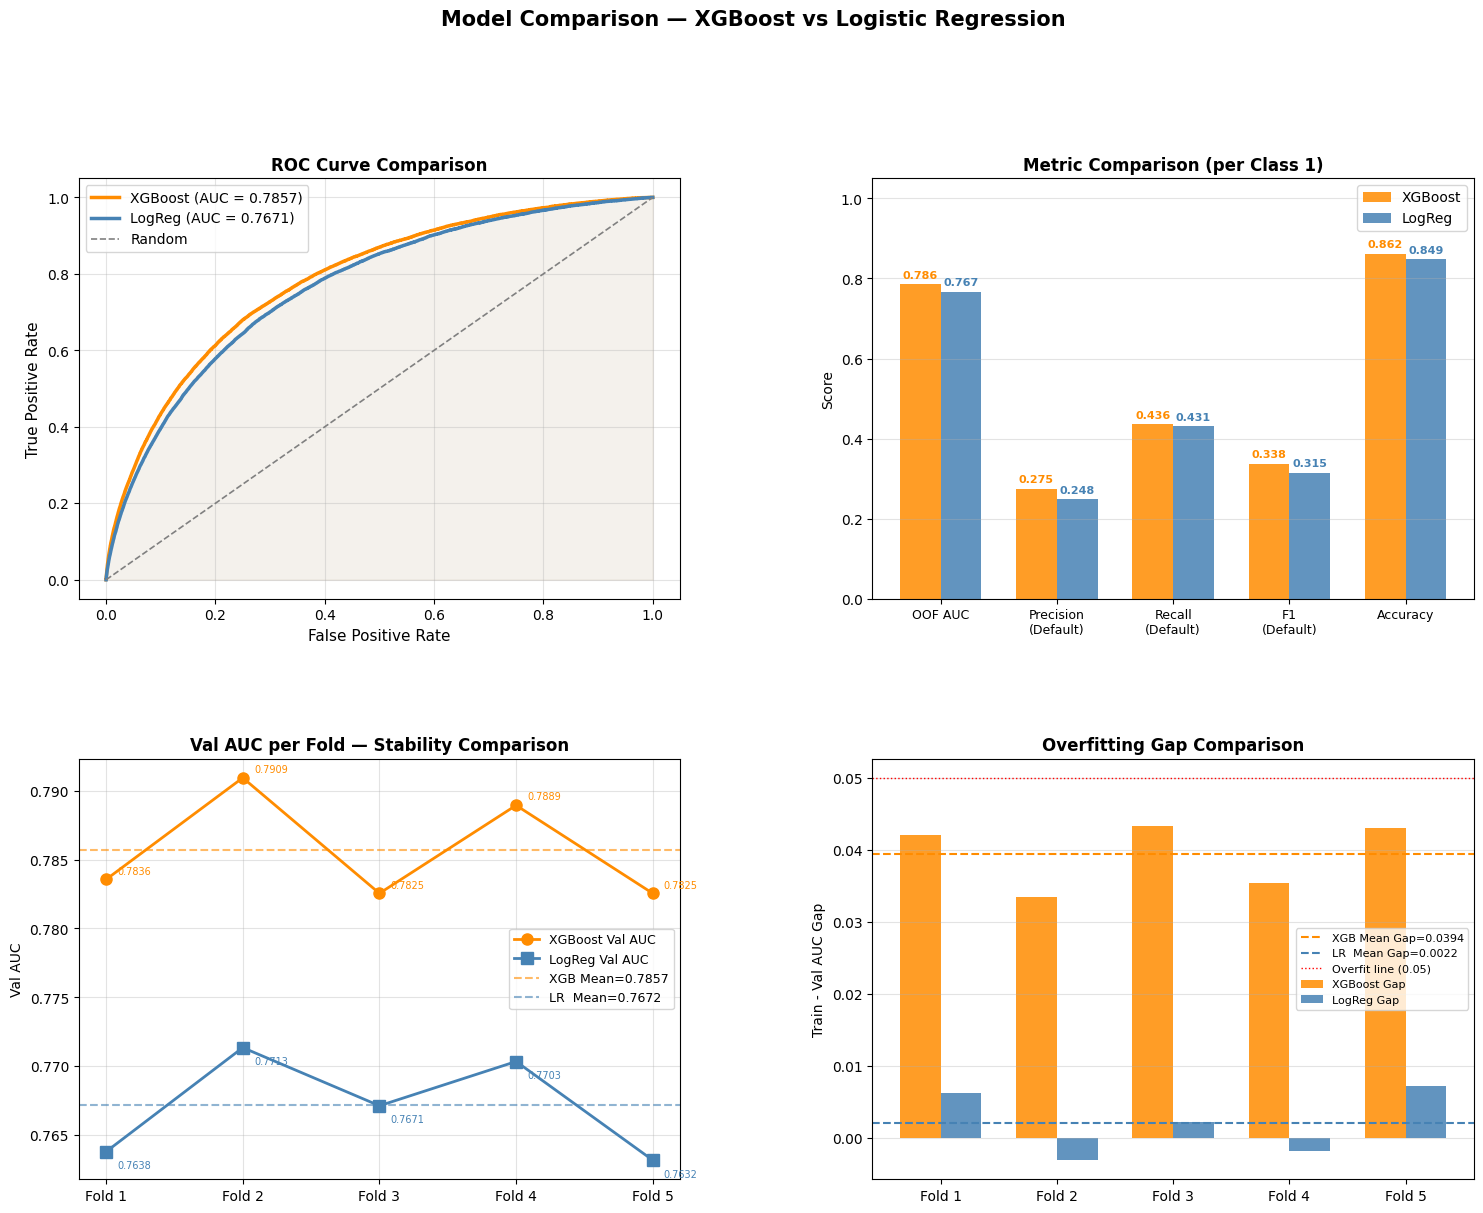


✅ Comparison plot disimpan: 'model_comparison.png'


In [ ]:
# =========================
# TAHAP 17 — COMPARISON XGB vs LOGREG
# (Jalankan setelah Tahap 10 dan Tahap 16 selesai)
# =========================
from sklearn.metrics import roc_curve, auc
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import numpy as np

# Kumpulkan semua metrik
# Ambil dari variabel yang sudah ada di Tahap 10 dan 16
metrics = {
    'XGBoost': {
        'oof_auc'    : oof_auc,
        'avg_prec'   : avg_precision,
        'accuracy'   : report['accuracy'],
        'precision'  : report['1']['precision'],
        'recall'     : report['1']['recall'],
        'f1'         : report['1']['f1-score'],
        'mean_val'   : mean_val,
        'mean_train' : mean_train,
        'mean_gap'   : mean_gap,
        'val_std'    : np.std(fold_val_scores),
        'oof_pred'   : oof_pred,
        'fold_vals'  : fold_val_scores,
        'color'      : 'darkorange'
    },
    'LogReg': {
        'oof_auc'    : oof_auc_lr,
        'avg_prec'   : ap_lr,
        'accuracy'   : report_lr['accuracy'],
        'precision'  : report_lr['1']['precision'],
        'recall'     : report_lr['1']['recall'],
        'f1'         : report_lr['1']['f1-score'],
        'mean_val'   : mean_val_lr,
        'mean_train' : mean_train_lr,
        'mean_gap'   : mean_gap_lr,
        'val_std'    : np.std(fold_val_scores_lr),
        'oof_pred'   : oof_pred_lr,
        'fold_vals'  : fold_val_scores_lr,
        'color'      : 'steelblue'
    }
}

# --------------------------------------------------
# PRINT COMPARISON TABLE
# --------------------------------------------------
print("=" * 62)
print("  MODEL COMPARISON — XGBoost vs Logistic Regression")
print("=" * 62)
print(f"{'Metric':<28} {'XGBoost':>14} {'LogReg':>14}")
print("-" * 62)

rows = [
    ('OOF AUC',              'oof_auc',    '.5f'),
    ('Avg Precision (PR)',   'avg_prec',   '.5f'),
    ('Accuracy',             'accuracy',   '.4f'),
    ('Precision (Default)',  'precision',  '.4f'),
    ('Recall (Default)',     'recall',     '.4f'),
    ('F1 (Default)',         'f1',         '.4f'),
    ('Mean Val AUC (CV)',    'mean_val',   '.5f'),
    ('Mean Train AUC (CV)',  'mean_train', '.5f'),
    ('Mean Gap (overfit)',   'mean_gap',   '.5f'),
    ('Val AUC Std',          'val_std',    '.5f'),
]

for label, key, fmt in rows:
    xgb_val = metrics['XGBoost'][key]
    lr_val  = metrics['LogReg'][key]
    winner  = '← XGB' if xgb_val > lr_val else '← LR '
    # Untuk gap, lebih kecil lebih baik
    if key == 'mean_gap' or key == 'val_std':
        winner = '← XGB' if xgb_val < lr_val else '← LR '
    print(f"  {label:<26} {xgb_val:>{14}{fmt}} {lr_val:>{14}{fmt}}  {winner}")

print("=" * 62)

xgb_wins = sum(1 for _, key, _ in rows
               if (metrics['XGBoost'][key] > metrics['LogReg'][key]
                   and key not in ['mean_gap','val_std'])
               or (metrics['XGBoost'][key] < metrics['LogReg'][key]
                   and key in ['mean_gap','val_std']))
print(f"\n  XGBoost wins : {xgb_wins}/{len(rows)} metrics")
print(f"  LogReg wins  : {len(rows)-xgb_wins}/{len(rows)} metrics")
print(f"\n  → Rekomendasi model: {'XGBoost' if xgb_wins >= len(rows)//2 else 'LogReg'}")
print("=" * 62)

# --------------------------------------------------
# VISUALISASI COMPARISON — 4 PANEL
# --------------------------------------------------
fig = plt.figure(figsize=(18, 13))
fig.suptitle('Model Comparison — XGBoost vs Logistic Regression',
             fontsize=15, fontweight='bold', y=1.01)

gs  = gridspec.GridSpec(2, 2, figure=fig, hspace=0.38, wspace=0.32)
ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, 0])
ax4 = fig.add_subplot(gs[1, 1])

# --- Panel 1: ROC Curve Overlay ---
for name, m in metrics.items():
    fpr_, tpr_, _ = roc_curve(y, m['oof_pred'])
    ax1.plot(fpr_, tpr_, color=m['color'], linewidth=2.5,
             label=f"{name} (AUC = {m['oof_auc']:.4f})")
    ax1.fill_between(fpr_, tpr_, alpha=0.06, color=m['color'])

ax1.plot([0,1],[0,1], linestyle='--', color='gray', linewidth=1.2,
         label='Random')
ax1.set_xlabel('False Positive Rate', fontsize=11)
ax1.set_ylabel('True Positive Rate',  fontsize=11)
ax1.set_title('ROC Curve Comparison',  fontsize=12, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.35)

# --- Panel 2: Metric Bar Chart ---
metric_labels = ['OOF AUC', 'Precision\n(Default)',
                 'Recall\n(Default)', 'F1\n(Default)', 'Accuracy']
metric_keys   = ['oof_auc', 'precision', 'recall', 'f1', 'accuracy']

xgb_vals = [metrics['XGBoost'][k] for k in metric_keys]
lr_vals  = [metrics['LogReg'][k]  for k in metric_keys]

x     = np.arange(len(metric_labels))
width = 0.35

bars_xgb = ax2.bar(x - width/2, xgb_vals, width,
                   label='XGBoost', color='darkorange', alpha=0.85)
bars_lr  = ax2.bar(x + width/2, lr_vals,  width,
                   label='LogReg',  color='steelblue',  alpha=0.85)

ax2.set_xticks(x)
ax2.set_xticklabels(metric_labels, fontsize=9)
ax2.set_ylim(0, 1.05)
ax2.set_ylabel('Score')
ax2.set_title('Metric Comparison (per Class 1)',
              fontsize=12, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(axis='y', alpha=0.35)

for bar in bars_xgb:
    ax2.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.01,
             f'{bar.get_height():.3f}',
             ha='center', va='bottom', fontsize=8, color='darkorange',
             fontweight='bold')
for bar in bars_lr:
    ax2.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.01,
             f'{bar.get_height():.3f}',
             ha='center', va='bottom', fontsize=8, color='steelblue',
             fontweight='bold')

# --- Panel 3: Val AUC per Fold Comparison ---
fold_labels = [f'Fold {i+1}' for i in range(5)]
ax3.plot(fold_labels, metrics['XGBoost']['fold_vals'], 'o-',
         color='darkorange', linewidth=2, markersize=8, label='XGBoost Val AUC')
ax3.plot(fold_labels, metrics['LogReg']['fold_vals'],  's-',
         color='steelblue',  linewidth=2, markersize=8, label='LogReg Val AUC')
ax3.axhline(metrics['XGBoost']['mean_val'], color='darkorange',
            linestyle='--', alpha=0.6,
            label=f"XGB Mean={metrics['XGBoost']['mean_val']:.4f}")
ax3.axhline(metrics['LogReg']['mean_val'],  color='steelblue',
            linestyle='--', alpha=0.6,
            label=f"LR  Mean={metrics['LogReg']['mean_val']:.4f}")
ax3.set_ylabel('Val AUC')
ax3.set_title('Val AUC per Fold — Stability Comparison',
              fontsize=12, fontweight='bold')
ax3.legend(fontsize=9)
ax3.grid(alpha=0.35)

for i, (xv, lv) in enumerate(zip(metrics['XGBoost']['fold_vals'],
                                  metrics['LogReg']['fold_vals'])):
    ax3.annotate(f'{xv:.4f}', (fold_labels[i], xv),
                 textcoords="offset points", xytext=(8, 4),
                 fontsize=7, color='darkorange')
    ax3.annotate(f'{lv:.4f}', (fold_labels[i], lv),
                 textcoords="offset points", xytext=(8, -12),
                 fontsize=7, color='steelblue')

# --- Panel 4: Overfit Gap Comparison ---
gaps_xgb = [tr - vl for tr, vl
             in zip(metrics['XGBoost']['fold_vals'],
                    metrics['XGBoost']['fold_vals'])]

# Hitung ulang gap dari train dan val yang tersimpan
gaps_xgb_real = [tr - vl for tr, vl
                 in zip(fold_train_scores, fold_val_scores)]
gaps_lr_real  = [tr - vl for tr, vl
                 in zip(fold_train_scores_lr, fold_val_scores_lr)]

x2    = np.arange(5)
width = 0.35
ax4.bar(x2 - width/2, gaps_xgb_real, width,
        label='XGBoost Gap', color='darkorange', alpha=0.85)
ax4.bar(x2 + width/2, gaps_lr_real,  width,
        label='LogReg Gap',  color='steelblue',  alpha=0.85)
ax4.axhline(np.mean(gaps_xgb_real), color='darkorange', linestyle='--',
            linewidth=1.5,
            label=f"XGB Mean Gap={np.mean(gaps_xgb_real):.4f}")
ax4.axhline(np.mean(gaps_lr_real),  color='steelblue',  linestyle='--',
            linewidth=1.5,
            label=f"LR  Mean Gap={np.mean(gaps_lr_real):.4f}")
ax4.axhline(0.05, color='red', linestyle=':', linewidth=1,
            label='Overfit line (0.05)')
ax4.set_xticks(x2)
ax4.set_xticklabels(fold_labels)
ax4.set_ylabel('Train - Val AUC Gap')
ax4.set_title('Overfitting Gap Comparison',
              fontsize=12, fontweight='bold')
ax4.legend(fontsize=8)
ax4.grid(axis='y', alpha=0.35)

plt.savefig('model_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print("\n✅ Comparison plot disimpan: 'model_comparison.png'")

## Prediction Pada Test Dataset

In [ ]:
# =========================
# TAHAP 18 — PREDICTION TEST DATASET
# Tidak perlu train ulang!
# test_pred_final sudah tersedia dari Tahap 8
# =========================

# --- 18.1 Load kembali df_test_final (data asli dengan SK_ID_CURR) ---
# Karena di Tahap 3 (Final Cleaning) SK_ID_CURR sudah di-drop dari
# working variables, kita reload dari file yang sudah disimpan
base_path = '/content/drive/MyDrive/dataset PBI home credit/'

df_test_display = pd.read_csv(base_path + 'final_test.csv')

print("Test data loaded:")
print(f"  Shape : {df_test_display.shape}")
print(f"  Kolom pertama: {df_test_display.columns[:5].tolist()}")

# --- 18.2 Verifikasi panjang prediction sama dengan test ---
assert len(test_pred_final) == len(df_test_display), \
    f"❌ Panjang tidak sama! pred={len(test_pred_final)}, test={len(df_test_display)}"

print(f"\n✅ Panjang test_pred_final ({len(test_pred_final)}) "
      f"== df_test_display ({len(df_test_display)})")

# --- 18.3 Tambahkan kolom prediksi ke df_test_display ---
df_test_display = df_test_display.copy()
df_test_display['DEFAULT_PROBABILITY'] = test_pred_final

# Label prediksi menggunakan threshold XGBoost
df_test_display['PREDICTED_DEFAULT']   = (test_pred_final > best_thr_f1).astype(int)

# Risk category berdasarkan probabilitas
def assign_risk(prob):
    if prob < 0.2:
        return 'LOW RISK'
    elif prob < 0.4:
        return 'MEDIUM RISK'
    elif prob < best_thr_f1:
        return 'HIGH RISK'
    else:
        return 'VERY HIGH RISK'

df_test_display['RISK_CATEGORY'] = df_test_display['DEFAULT_PROBABILITY'].apply(assign_risk)

# --- 18.4 Tampilkan ringkasan ---
print("\n" + "=" * 55)
print("  PREDICTION SUMMARY")
print("=" * 55)
print(f"  Total aplikasi diprediksi : {len(df_test_display):,}")
print(f"  Threshold digunakan       : {best_thr_f1:.4f}")
print(f"\n  Prediksi DEFAULT (1)      : "
      f"{df_test_display['PREDICTED_DEFAULT'].sum():,} "
      f"({df_test_display['PREDICTED_DEFAULT'].mean()*100:.2f}%)")
print(f"  Prediksi NO DEFAULT (0)   : "
      f"{(df_test_display['PREDICTED_DEFAULT']==0).sum():,} "
      f"({(df_test_display['PREDICTED_DEFAULT']==0).mean()*100:.2f}%)")

print(f"\n  Probabilitas rata-rata    : {test_pred_final.mean():.4f}")
print(f"  Probabilitas min          : {test_pred_final.min():.4f}")
print(f"  Probabilitas max          : {test_pred_final.max():.4f}")

print(f"\n  Distribusi Risk Category:")
risk_counts = df_test_display['RISK_CATEGORY'].value_counts()
risk_order  = ['LOW RISK', 'MEDIUM RISK', 'HIGH RISK', 'VERY HIGH RISK']
for cat in risk_order:
    if cat in risk_counts:
        n   = risk_counts[cat]
        pct = n / len(df_test_display) * 100
        print(f"    {cat:<16} : {n:>6,}  ({pct:.2f}%)")

print("=" * 55)

# --- 18.5 Tampilkan sample hasil prediksi ---
preview_cols = [
    'SK_ID_CURR',
    'DEFAULT_PROBABILITY',
    'PREDICTED_DEFAULT',
    'RISK_CATEGORY'
]

# Copy biar aman
prediction_preview = df_test_display[preview_cols].copy()

# Format probability biar rapi
prediction_preview['DEFAULT_PROBABILITY'] = (
    prediction_preview['DEFAULT_PROBABILITY']
    .round(4)
)

print("=" * 60)
print("          SAMPLE PREDICTION RESULTS")
print("=" * 60)

display(prediction_preview.head(25))

print(f"\nTotal rows previewed : 25")
print(f"Total prediction rows: {len(prediction_preview):,}")

print("\n📋 Sample HIGH/VERY HIGH RISK (10 teratas berdasarkan probabilitas):")
print("=" * 60)
print("          TOP 10 HIGHEST RISK APPLICANTS")
print("=" * 60)

top_risk_preview = (
    prediction_preview
    .sort_values('DEFAULT_PROBABILITY', ascending=False)
    .head(10)
)

display(top_risk_preview)



Test data loaded:
  Shape : (48744, 190)
  Kolom pertama: ['SK_ID_CURR', 'NAME_CONTRACT_TYPE', 'CODE_GENDER', 'FLAG_OWN_CAR', 'FLAG_OWN_REALTY']

✅ Panjang test_pred_final (48744) == df_test_display (48744)

  PREDICTION SUMMARY
  Total aplikasi diprediksi : 48,744
  Threshold digunakan       : 0.6741

  Prediksi DEFAULT (1)      : 5,439 (11.16%)
  Prediksi NO DEFAULT (0)   : 43,305 (88.84%)

  Probabilitas rata-rata    : 0.3690
  Probabilitas min          : 0.0118
  Probabilitas max          : 0.9582

  Distribusi Risk Category:
    LOW RISK         : 13,127  (26.93%)
    MEDIUM RISK      : 15,972  (32.77%)
    HIGH RISK        : 14,206  (29.14%)
    VERY HIGH RISK   :  5,439  (11.16%)
          SAMPLE PREDICTION RESULTS


,SK_ID_CURR,DEFAULT_PROBABILITY,PREDICTED_DEFAULT,RISK_CATEGORY
0,100001,0.3172,0,MEDIUM RISK
1,100005,0.7433,1,VERY HIGH RISK
2,100013,0.1465,0,LOW RISK
3,100028,0.2760,0,MEDIUM RISK
4,100038,0.6489,0,HIGH RISK
5,100042,0.2826,0,MEDIUM RISK
6,100057,0.1322,0,LOW RISK
7,100065,0.2280,0,MEDIUM RISK
8,100066,0.0911,0,LOW RISK
9,100067,0.5078,0,HIGH RISK



Total rows previewed : 25
Total prediction rows: 48,744

📋 Sample HIGH/VERY HIGH RISK (10 teratas berdasarkan probabilitas):
          TOP 10 HIGHEST RISK APPLICANTS


,SK_ID_CURR,DEFAULT_PROBABILITY,PREDICTED_DEFAULT,RISK_CATEGORY
4525,132358,0.9582,1,VERY HIGH RISK
44795,428054,0.9512,1,VERY HIGH RISK
5719,141945,0.9502,1,VERY HIGH RISK
26317,291592,0.9498,1,VERY HIGH RISK
40533,398348,0.9478,1,VERY HIGH RISK
11587,184226,0.9449,1,VERY HIGH RISK
15007,208127,0.9435,1,VERY HIGH RISK
634,104410,0.9431,1,VERY HIGH RISK
47394,446472,0.9431,1,VERY HIGH RISK
10527,176483,0.9429,1,VERY HIGH RISK


### Visualisasi Prediksi

/tmp/ipykernel_884/3709591697.py:61: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax4.boxplot(data_box, labels=risk_ordered, patch_artist=True,


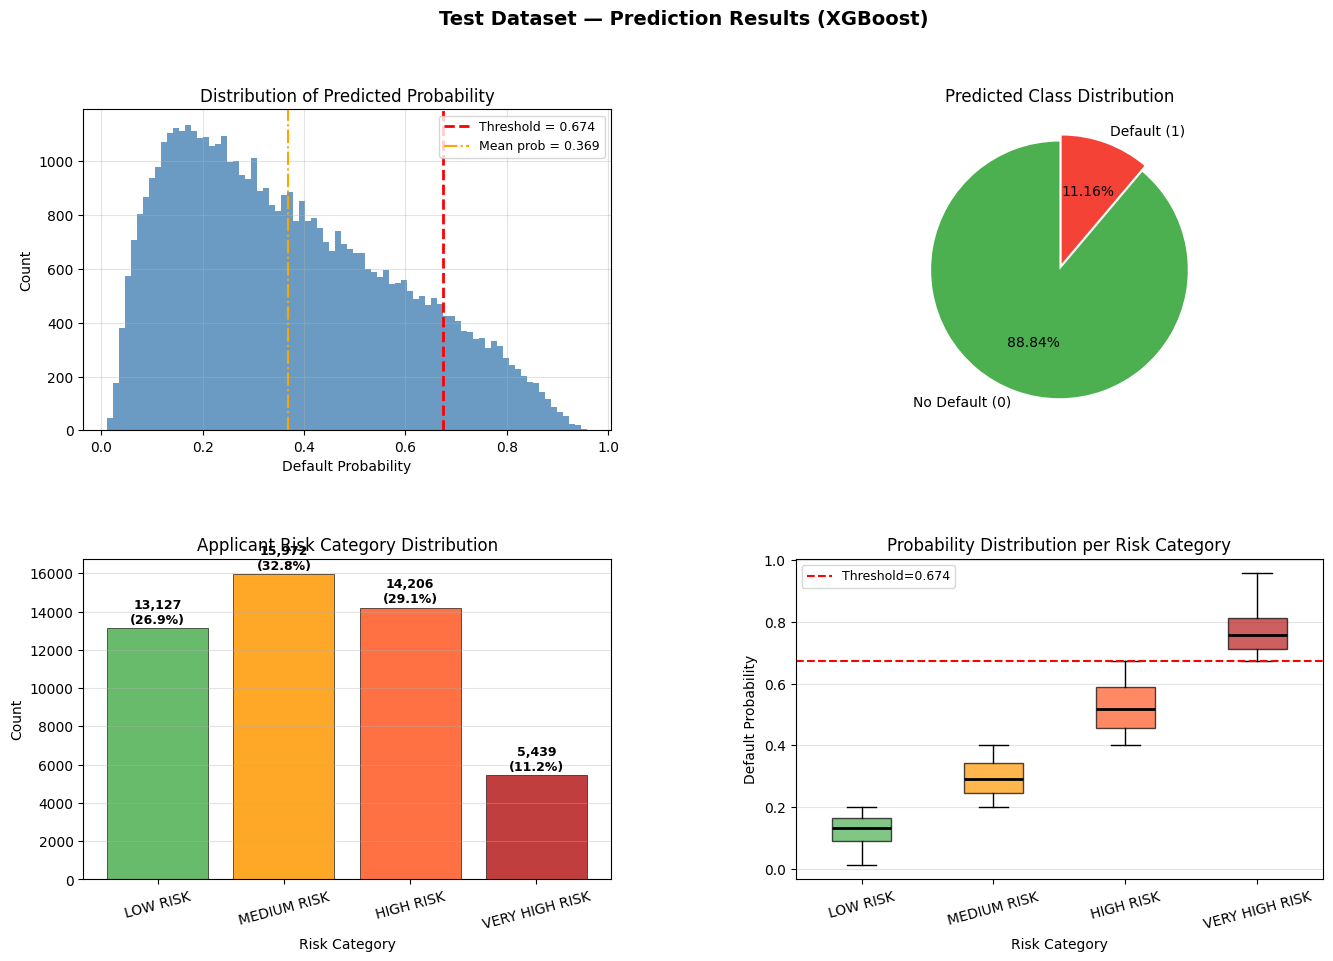


✅ Plot disimpan: 'test_prediction_results.png'


In [ ]:
# --- 18.6 Visualisasi distribusi probabilitas prediksi ---
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(16, 10))
fig.suptitle('Test Dataset — Prediction Results (XGBoost)',
             fontsize=14, fontweight='bold')

gs  = gridspec.GridSpec(2, 2, figure=fig, hspace=0.4, wspace=0.35)
ax1 = fig.add_subplot(gs[0, 0])
ax2 = fig.add_subplot(gs[0, 1])
ax3 = fig.add_subplot(gs[1, 0])
ax4 = fig.add_subplot(gs[1, 1])

# Panel 1 — Histogram probabilitas
ax1.hist(df_test_display['DEFAULT_PROBABILITY'], bins=80,
         color='steelblue', alpha=0.8, edgecolor='none')
ax1.axvline(best_thr_f1, color='red', linestyle='--', linewidth=2,
            label=f'Threshold = {best_thr_f1:.3f}')
ax1.axvline(test_pred_final.mean(), color='orange', linestyle='-.',
            linewidth=1.5,
            label=f'Mean prob = {test_pred_final.mean():.3f}')
ax1.set_xlabel('Default Probability')
ax1.set_ylabel('Count')
ax1.set_title('Distribution of Predicted Probability')
ax1.legend(fontsize=9)
ax1.grid(True, alpha=0.35)

# Panel 2 — Pie chart predicted class
pred_counts = df_test_display['PREDICTED_DEFAULT'].value_counts()
labels_pie  = ['No Default (0)', 'Default (1)']
colors_pie  = ['#4CAF50', '#F44336']
explode     = (0, 0.05)
ax2.pie(pred_counts.values, labels=labels_pie, colors=colors_pie,
        autopct='%1.2f%%', startangle=90, explode=explode,
        textprops={'fontsize': 10})
ax2.set_title('Predicted Class Distribution')

# Panel 3 — Bar chart risk category
risk_ordered = [cat for cat in risk_order if cat in risk_counts]
vals_ordered = [risk_counts[cat] for cat in risk_ordered]
colors_risk  = ['#4CAF50', '#FF9800', '#FF5722', '#B71C1C']
bars = ax3.bar(risk_ordered, vals_ordered, color=colors_risk[:len(risk_ordered)],
               alpha=0.85, edgecolor='black', linewidth=0.5)
ax3.set_xlabel('Risk Category')
ax3.set_ylabel('Count')
ax3.set_title('Applicant Risk Category Distribution')
ax3.grid(axis='y', alpha=0.35)
ax3.tick_params(axis='x', labelrotation=15)
for bar, val in zip(bars, vals_ordered):
    pct = val / len(df_test_display) * 100
    ax3.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 100,
             f'{val:,}\n({pct:.1f}%)',
             ha='center', va='bottom', fontsize=9, fontweight='bold')

# Panel 4 — Box plot probabilitas per risk category
data_box   = [df_test_display[df_test_display['RISK_CATEGORY'] == cat]
              ['DEFAULT_PROBABILITY'].values
              for cat in risk_ordered]
bp = ax4.boxplot(data_box, labels=risk_ordered, patch_artist=True,
                 medianprops={'color':'black','linewidth':2})
for patch, color in zip(bp['boxes'], colors_risk[:len(risk_ordered)]):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
ax4.axhline(best_thr_f1, color='red', linestyle='--', linewidth=1.5,
            label=f'Threshold={best_thr_f1:.3f}')
ax4.set_xlabel('Risk Category')
ax4.set_ylabel('Default Probability')
ax4.set_title('Probability Distribution per Risk Category')
ax4.legend(fontsize=9)
ax4.grid(axis='y', alpha=0.35)
ax4.tick_params(axis='x', labelrotation=15)

plt.savefig('test_prediction_results.png', dpi=150, bbox_inches='tight')
plt.show()
print("\n✅ Plot disimpan: 'test_prediction_results.png'")

# # --- 18.7 Save hasil prediksi lengkap ---
# output_path = base_path + 'test_predictions_full.csv'
# df_test_display.to_csv(output_path, index=False)
# print(f"✅ Full prediction saved: {output_path}")
# print(f"   Shape: {df_test_display.shape}")

# # Save versi ringkas (hanya ID + prediksi) untuk submission Kaggle
# submission_clean = df_test_display[['SK_ID_CURR',
#                                      'DEFAULT_PROBABILITY']].copy()
# submission_clean.columns = ['SK_ID_CURR', 'TARGET']
# submission_clean.to_csv(base_path + 'submission_final.csv', index=False)
# print(f"✅ Kaggle submission saved: {base_path}submission_final.csv")
# print(submission_clean.head(10).to_string(index=False))

## Save Model XGBoost

In [ ]:
# =========================
# TAHAP 19 — SAVE MODEL XGBOOST
# Untuk deployment di website/API
# =========================
import joblib
import json
import os
import pickle
from datetime import datetime
import numpy as np
import pandas as pd

model_dir = base_path + 'model_xgb/'
os.makedirs(model_dir, exist_ok=True)

timestamp = datetime.now().strftime('%Y%m%d_%H%M%S')

# --- 19.1 Latih Final Model di FULL TRAIN DATA ---
# Gunakan best iteration rata-rata dari K-Fold
# agar model final tidak pakai early stopping
# (karena tidak ada val set lagi — train di semua data)

best_iter_mean = int(np.mean(fold_best_iterations))
print(f"Best iteration rata-rata dari K-Fold : {best_iter_mean}")

from xgboost import XGBClassifier

final_model_params = {k: v for k, v in xgb_params.items()
                      if k != 'early_stopping_rounds'}
final_model_params['n_estimators'] = best_iter_mean

print("\nTraining final model on FULL training data...")
print(f"  n_estimators (dari best iter CV) : {best_iter_mean}")
print(f"  Features                          : {X_sel.shape[1]}")
print(f"  Training rows                     : {X_sel.shape[0]:,}")

final_model = XGBClassifier(**final_model_params)
final_model.fit(X_sel, y, verbose=False)

print("✅ Final model trained!")

# --- 19.2 Verifikasi model final di training data ---
train_prob_final = final_model.predict_proba(X_sel)[:, 1]
train_auc_final  = roc_auc_score(y, train_prob_final)
print(f"   Train AUC final model : {train_auc_final:.5f}")
print(f"   OOF AUC (CV estimate) : {oof_auc:.5f}")

# --- 19.3 Save model dalam berbagai format ---

# Format 1: joblib (recommended untuk sklearn-compatible pipeline)
joblib_path = model_dir + f'xgb_model_{timestamp}.joblib'
joblib.dump(final_model, joblib_path)
print(f"\n✅ [1] Saved joblib : {joblib_path}")

# Format 2: pickle (universal Python)
pickle_path = model_dir + f'xgb_model_{timestamp}.pkl'
with open(pickle_path, 'wb') as f:
    pickle.dump(final_model, f)
print(f"✅ [2] Saved pickle : {pickle_path}")

# Format 3: XGBoost native JSON (paling stabil lintas versi)
json_model_path = model_dir + f'xgb_model_{timestamp}.json'
final_model.save_model(json_model_path)
print(f"✅ [3] Saved XGB JSON : {json_model_path}")

# --- 19.4 Save feature list (WAJIB untuk deployment) ---
feature_list_path = model_dir + 'feature_list.json'
with open(feature_list_path, 'w') as f:
    json.dump(selected_features, f, indent=2)
print(f"✅ [4] Saved feature list ({len(selected_features)} features): {feature_list_path}")

# --- 19.5 Save scaler (untuk LogReg, opsional untuk XGB) ---
scaler_path = model_dir + 'scaler.joblib'
joblib.dump(scaler, scaler_path)
print(f"✅ [5] Saved scaler : {scaler_path}")

# --- 19.6 Save model metadata (untuk dokumentasi & monitoring) ---
metadata = {
    'model_type'          : 'XGBoostClassifier',
    'trained_at'          : timestamp,
    'xgboost_version'     : final_model.__class__.__module__,
    'n_features'          : len(selected_features),
    'n_training_rows'     : int(X_sel.shape[0]),
    'best_iter_per_fold'  : fold_best_iterations,
    'best_iter_used'      : best_iter_mean,
    'oof_auc'             : round(float(oof_auc), 6),
    'mean_val_auc_cv'     : round(float(mean_val), 6),
    'mean_train_auc_cv'   : round(float(mean_train), 6),
    'mean_gap_cv'         : round(float(mean_gap), 6),
    'val_auc_std'         : round(float(np.std(fold_val_scores)), 6),
    'best_threshold_f1'   : round(float(best_thr_f1), 6),
    'imbalance_ratio'     : round(float(imbalance_ratio), 4),
    'model_params'        : {k: str(v) for k, v in final_model_params.items()},
    'files': {
        'model_joblib'    : joblib_path,
        'model_pickle'    : pickle_path,
        'model_json'      : json_model_path,
        'feature_list'    : feature_list_path,
        'scaler'          : scaler_path,
    }
}

metadata_path = model_dir + f'model_metadata_{timestamp}.json'
with open(metadata_path, 'w') as f:
    json.dump(metadata, f, indent=2)
print(f"✅ [6] Saved metadata : {metadata_path}")

# --- 19.7 Print ringkasan semua file ---
print("\n" + "=" * 60)
print("  MODEL SAVE SUMMARY")
print("=" * 60)
print(f"  Directory       : {model_dir}")
print(f"  Timestamp       : {timestamp}")
print(f"  OOF AUC         : {oof_auc:.5f}")
print(f"  Threshold       : {best_thr_f1:.4f}")
print(f"  Features        : {len(selected_features)}")
print(f"  Best iter (avg) : {best_iter_mean}")
print(f"\n  Files saved:")
for i, (label, path) in enumerate([
    ('XGB model (.joblib)', joblib_path),
    ('XGB model (.pkl)',    pickle_path),
    ('XGB model (.json)',   json_model_path),
    ('Feature list',        feature_list_path),
    ('Scaler',              scaler_path),
    ('Metadata',            metadata_path),
], 1):
    size_kb = os.path.getsize(path) / 1024
    print(f"    [{i}] {label:<22} → {os.path.basename(path):<45} ({size_kb:.1f} KB)")

print("=" * 60)

# --- 19.8 Quick load test (verifikasi model bisa di-load ulang) ---
print("\n🔍 Quick load test...")
model_loaded = joblib.load(joblib_path)
test_prob    = model_loaded.predict_proba(X_sel.iloc[:5])[: , 1]
print(f"   Sample probabilities dari loaded model: {np.round(test_prob, 4)}")
print("✅ Model load test passed — siap untuk deployment!")

Best iteration rata-rata dari K-Fold : 2998

Training final model on FULL training data...
  n_estimators (dari best iter CV) : 2998
  Features                          : 167
  Training rows                     : 307,511
✅ Final model trained!
   Train AUC final model : 0.81894
   OOF AUC (CV estimate) : 0.78569

✅ [1] Saved joblib : /content/drive/MyDrive/dataset PBI home credit/model_xgb/xgb_model_20260516_045411.joblib
✅ [2] Saved pickle : /content/drive/MyDrive/dataset PBI home credit/model_xgb/xgb_model_20260516_045411.pkl
✅ [3] Saved XGB JSON : /content/drive/MyDrive/dataset PBI home credit/model_xgb/xgb_model_20260516_045411.json
✅ [4] Saved feature list (167 features): /content/drive/MyDrive/dataset PBI home credit/model_xgb/feature_list.json
✅ [5] Saved scaler : /content/drive/MyDrive/dataset PBI home credit/model_xgb/scaler.joblib
✅ [6] Saved metadata : /content/drive/MyDrive/dataset PBI home credit/model_xgb/model_metadata_20260516_045411.json

  MODEL SAVE SUMMARY
  Directo